# T2D gene-prioritization notebook




In [1]:

import sys
import os
import subprocess
import importlib


PINNED = {
    "numpy": "2.2.6",
    "scipy": "1.15.3",
    "pandas": "2.2.3",
    "scikit-learn": "1.6.1",
    "matplotlib": "3.10.1",
    "seaborn": "0.13.2",
    "joblib": "1.4.2",
    "openpyxl": "3.1.5",
}

def scientific_stack_healthy():
    """Test the actual binary imports, not just package metadata."""
    try:
        import numpy as np
        from scipy import stats
        import pandas as pd
        import sklearn
        import matplotlib
        # Exercise a compiled NumPy/SciPy path.
        _ = np.array([1.0, 2.0, 3.0]) + 1.0
        _ = stats.norm.cdf(0.0)
        _ = sklearn.__version__
        return True, {
            "numpy": np.__version__,
            "scipy": stats.__package__.split(".")[0] if False else __import__("scipy").__version__,
            "pandas": pd.__version__,
            "sklearn": sklearn.__version__,
            "matplotlib": matplotlib.__version__,
        }
    except Exception as e:
        return False, repr(e)

healthy, versions = scientific_stack_healthy()

if not healthy:
    print("=" * 78)
    print("BROKEN COLAB SCIENTIFIC STACK DETECTED")
    print("=" * 78)
    print("Python:", sys.version)
    print("Reason:", versions)
    print("\nRepairing NumPy + SciPy + Pandas + scikit-learn as ONE compatible stack...")

    # Uninstall the conflicting compiled packages first, then install
    # the complete pinned stack in one transaction.
    packages = [f"{name}=={version}" for name, version in PINNED.items()]

    subprocess.check_call([
        sys.executable, "-m", "pip", "uninstall", "-y",
        "numpy", "scipy", "pandas", "scikit-learn", "matplotlib",
        "seaborn", "joblib", "openpyxl"
    ])

    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "--no-cache-dir",
        "--force-reinstall", *packages
    ])

    print("\nRepair completed.")
    print("The kernel must restart so Python unloads the old binary modules.")
    print("Restarting Colab automatically...")

    # Hard restart. The next execution starts with the repaired binaries.
    os.kill(os.getpid(), 9)

# ----------------------------------------------------------------
# Healthy runtime: import everything needed by the notebook.
# ----------------------------------------------------------------

import os, json, math, time, random, warnings, hashlib, platform
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, brier_score_loss,
    roc_curve, precision_recall_curve, confusion_matrix,
    precision_score, recall_score, f1_score, accuracy_score,
    log_loss
)
from sklearn.model_selection import (
    StratifiedGroupKFold, StratifiedKFold, GridSearchCV
)
from sklearn.inspection import permutation_importance
from sklearn.calibration import calibration_curve

import joblib
import openpyxl

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 20260910
np.random.seed(SEED)
random.seed(SEED)

# --- CONFIGURABLE OUTPUT PATHS ---
BASE = Path(os.environ.get("T2D_BASE", "/content"))
# Custom result path as requested
OUT = BASE / "T2D_v10_ML_Results"
FIG = OUT / "figures"
TAB = OUT / "tables"
MODEL_DIR = OUT / "models"

for pth in [OUT, FIG, TAB, MODEL_DIR]:
    pth.mkdir(parents=True, exist_ok=True)

print("=" * 78)
print("T2D ML ENVIRONMENT — READY")
print("=" * 78)
print("Python :", sys.version.split()[0])
print("NumPy  :", np.__version__)
print("Pandas :", pd.__version__)
print("SciPy  :", __import__("scipy").__version__)
print("sklearn:", __import__("sklearn").__version__)
print("Matplotlib:", matplotlib.__version__)
print("Seaborn:", sns.__version__)
print("Output :", OUT)
print("\nNo NumPy/SciPy binary mismatch detected.")

# The reported numbers were produced with these versions. StratifiedGroupKFold fold assignment can differ
# across scikit-learn releases, so metrics can shift slightly if the versions differ.
EXPECTED_VERSIONS = {"sklearn": "1.6.1", "pandas": "2.2.3"}
_mismatch = {k: {"expected": v, "found": __import__(k).__version__}
             for k, v in EXPECTED_VERSIONS.items() if __import__(k).__version__ != v}
if _mismatch:
    print("\nWARNING: library versions differ from those used for the reported numbers:", _mismatch)
    print("Small shifts in fold-level and pooled metrics are expected; re-report all numbers from THIS run.")

T2D ML ENVIRONMENT — READY
Python : 3.13.16
NumPy  : 2.1.3
Pandas : 2.2.3
SciPy  : 1.16.3
sklearn: 1.6.1
Matplotlib: 3.10.0
Seaborn: 0.13.2
Output : /content/T2D_v10_ML_Results

No NumPy/SciPy binary mismatch detected.


### Runtime repair rule

**First run:** if the runtime is broken, Cell 1 repairs the complete scientific stack and intentionally restarts the kernel. After the restart, use **Runtime → Run all** again. If Cell 1 prints `T2D ML ENVIRONMENT — READY`, continue normally.

Do **not** add `pip install -U numpy/scipy/pandas/scikit-learn` anywhere in this notebook; mixing independently upgraded binary packages is what caused the `_slice` import error.


## 2. Provide the gene-level workbook

The notebook expects `T2D_Final_Dataset_with_HGNC_Ensembl.xlsx` (any single .xlsx containing sheet `FINAL_3868_GENE_DATASET`; the sheet already holds the HGNC / Ensembl columns).

The next cell looks in `/content` for such a workbook and opens the upload dialog only if none is found. If several workbooks are present it prefers the one with
"HGNC_Ensembl" in its name; otherwise delete the stale ones. Set `T2D_XLSX` to use an explicit path (for example on Google Drive) or `T2D_XLSX_URL` to download the workbook
from an archive (for example Zenodo). An older workbook without the identifier columns also works if the two reference files are present (cell 4B).

The workbook also carries sheet `LITERATURE_ANNOTATION` (hand-compiled literature check used for Table 10 / Supplementary Table S1), so this single file is the only upload needed.


In [2]:
#@title 2. Locate / upload dataset
try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

GENE_SHEET = "FINAL_3868_GENE_DATASET"

def workbooks_with_gene_sheet(folder):
    found = []
    for p in sorted(Path(folder).glob("*.xlsx")):
        try:
            wb = openpyxl.load_workbook(p, read_only=True)
            if GENE_SHEET in wb.sheetnames:
                found.append(p)
            wb.close()
        except Exception:
            pass
    return found

if os.environ.get("T2D_XLSX"):
    XLSX = Path(os.environ["T2D_XLSX"])
else:
    candidates = workbooks_with_gene_sheet(BASE)
    if not candidates and os.environ.get("T2D_XLSX_URL"):
        import urllib.request
        urllib.request.urlretrieve(os.environ["T2D_XLSX_URL"], BASE / "T2D_Final_Dataset_with_HGNC_Ensembl.xlsx")
        candidates = workbooks_with_gene_sheet(BASE)
    if not candidates:
        if not IN_COLAB:
            raise FileNotFoundError(f"No .xlsx containing sheet {GENE_SHEET} found in {BASE}; "
                                    "copy the workbook there or set T2D_XLSX.")
        uploaded = files.upload()
        print("Uploaded:", list(uploaded.keys()))
        candidates = workbooks_with_gene_sheet(BASE)
    if len(candidates) > 1:
        _pref = [c for c in candidates if "HGNC_Ensembl" in c.name]
        if len(_pref) == 1:
            print("Several workbooks found; using the one with HGNC / Ensembl identifiers:", _pref[0].name)
            candidates = _pref
    if len(candidates) != 1:
        raise FileNotFoundError(
            f"Expected exactly one workbook containing sheet {GENE_SHEET} in {BASE}; found "
            f"{[c.name for c in candidates]}. Delete stale copies and re-run.")
    XLSX = candidates[0]

assert XLSX.exists(), f"Workbook not found: {XLSX}"
print("Using:", XLSX)
print("SHA256:", hashlib.sha256(XLSX.read_bytes()).hexdigest())


Saving T2D_Final_Dataset_with_HGNC_Ensembl.xlsx to T2D_Final_Dataset_with_HGNC_Ensembl.xlsx
Uploaded: ['T2D_Final_Dataset_with_HGNC_Ensembl.xlsx']
Using: /content/T2D_Final_Dataset_with_HGNC_Ensembl.xlsx
SHA256: 13d8ac5c3088c385414983cf1bc4ff8f18c201c3aa7b5daf22c0ab6cd008ea66


In [3]:
#@title 3. Configuration
PRIMARY_FEATURES = [
    "in_gwas_evidence",
    "in_pisa_evidence",
    "in_gse164416_tested",
    "ppi_degree",
    "gtex_pancreas_tpm",
    "gtex_tau_specificity",
    "in_kegg_t2d_pathway",
    "in_reactome_t2d_pathway",
    "gse164416_baseMean",
    "gse164416_log2FC",
    "lfcSE",
    "stat",
    "gse164416_pvalue",
    "gse164416_FDR",
]

FORBIDDEN_PREFIXES = ("gse221156_", "emtab5061_")
SAME_COHORT_PATTERNS = ("2026", "orthogonal_2026")
TARGET_CANDIDATES = ["gse221156_beta_cell_DE", "label", "target", "primary_label"]
GROUP_CANDIDATES = [
    "locus_group_v6", "locus_group", "signal_group_v6",
    "gwas_lead_variant_group", "lead_variant_group"
]

print("Features:", len(PRIMARY_FEATURES))
print(PRIMARY_FEATURES)


Features: 14
['in_gwas_evidence', 'in_pisa_evidence', 'in_gse164416_tested', 'ppi_degree', 'gtex_pancreas_tpm', 'gtex_tau_specificity', 'in_kegg_t2d_pathway', 'in_reactome_t2d_pathway', 'gse164416_baseMean', 'gse164416_log2FC', 'lfcSE', 'stat', 'gse164416_pvalue', 'gse164416_FDR']


In [4]:
#@title 4. Inspect workbook and select the gene table
xls = pd.ExcelFile(XLSX)
print("Sheets:", len(xls.sheet_names))
print(xls.sheet_names)

preferred = ["FINAL_3868_GENE_DATASET"]
gene_sheet = "FINAL_3868_GENE_DATASET" if "FINAL_3868_GENE_DATASET" in xls.sheet_names else None
if gene_sheet is None:
    raise KeyError("Could not find the gene table sheet.")

df = pd.read_excel(XLSX, sheet_name=gene_sheet)
print("Gene table:", gene_sheet, df.shape)
display(df.head(3))

missing = [f for f in PRIMARY_FEATURES if f not in df.columns]
assert not missing, f"Missing features: {missing}"
assert len(df) == 3868, f"Expected 3868 genes in canonical sheet, found {len(df)}"

target_col = next((c for c in TARGET_CANDIDATES if c in df.columns), None)
if target_col is None:
    raise KeyError(f"Could not find primary target among {TARGET_CANDIDATES}")

print("Target column:", target_col)

group_col = next((c for c in GROUP_CANDIDATES if c in df.columns), None)
print("Candidate grouping column:", group_col)


Sheets: 4
['FINAL_3868_GENE_DATASET', 'ID_MAPPING_SUMMARY', 'DUPLICATE_GENES', 'LITERATURE_ANNOTATION']
Gene table: FINAL_3868_GENE_DATASET (3868, 153)


,gene_symbol,PISA_gene_id,Ensembl_mapping_status,annotation_note,gwas_n_gws_snps,gwas_n_unique_variants,gwas_strongest_pval,gwas_strongest_or,gwas_strongest_variant_id,gwas_source,...,GSE164416_validation_role_v6,hgnc_symbol,hgnc_id,ensembl_gene_id_grch38,ensembl_gene_name,gene_biotype,id_mapping_method,gene_label_clean,duplicate_gene_group,duplicate_resolution
0,A1CF,NaN,unmapped_in_available_local_master,No validated local Ensembl mapping was availab...,1.0,1.0,1.038857e-08,1.015,rs12570156,T2DGGI_2024_Suzuki_SupplementaryTable4,...,INDEPENDENT_EXTERNAL_VALIDATION_V6,A1CF,HGNC:24086,ENSG00000148584,A1CF,protein_coding,approved_symbol,A1CF,NaN,NaN
1,A3GALT2,NaN,unmapped_in_available_local_master,No validated local Ensembl mapping was availab...,NaN,NaN,NaN,NaN,NaN,NaN,...,not_tested,A3GALT2,HGNC:30005,ENSG00000184389,A3GALT2,protein_coding,approved_symbol,A3GALT2,NaN,NaN
2,AACS,NaN,unmapped_in_available_local_master,No validated local Ensembl mapping was availab...,NaN,NaN,NaN,NaN,NaN,NaN,...,INDEPENDENT_EXTERNAL_VALIDATION_V6,AACS,HGNC:21298,ENSG00000081760,AACS,protein_coding,approved_symbol,AACS,NaN,NaN


Target column: label
Candidate grouping column: locus_group_v6


In [5]:
#@title 4B. Identifier mapping (HGNC / Ensembl GRCh38) and duplicate-gene audit
# The evidence matrix was assembled, and matched across resources, from the ORIGINAL gene symbols. This cell ADDS
# authoritative identifiers afterwards. It never changes a row, a label or a predictor value.
# If the workbook already contains the identifier columns (T2D_Final_Dataset_with_HGNC_Ensembl.xlsx) the cell only
# summarises them. Otherwise it builds them from two reference files, placed in BASE or BASE/reference:
#   hgnc_complete_set.txt            HGNC complete set (genenames.org/download/archive), file dated 2026-10-15
#   ensembl_grch38_gene_export.tsv   Ensembl BioMart export, GRCh38.p14, one row per GENE with the columns
#                                    Gene stable ID, Gene stable ID version, Gene name, Gene type, HGNC symbol
#                                    (downloaded 2026-10-22). Any file named mart_export*.txt|tsv is also accepted.
ID_NEW_COLS = ["hgnc_symbol", "hgnc_id", "ensembl_gene_id_grch38", "ensembl_gene_name", "gene_biotype",
               "id_mapping_method", "gene_label_clean", "duplicate_gene_group", "duplicate_resolution"]
EXPECTED_ID_COUNTS = {"n_hgnc": 3339, "n_ensembl": 3745, "n_duplicate_rows_excluded": 14}   # values reported in the manuscript

def _find_ref(patterns):
    for folder in (BASE, BASE / "reference"):
        for pat in patterns:
            hits = sorted(Path(folder).glob(pat))
            if hits:
                return hits[0]
    return None

ID_MAPPING_INFO = {}
if all(c in df.columns for c in ID_NEW_COLS):
    print("Identifier columns already present in the workbook; summarising them (no mapping step needed).")
    ID_MAPPING_INFO["source"] = "columns present in workbook"
else:
    hgnc_path = _find_ref(["hgnc_complete_set*.txt", "hgnc_complete_set*.tsv"])
    ens_path = _find_ref(["ensembl_grch38_gene_export*.tsv", "mart_export*.txt", "mart_export*.tsv"])
    if hgnc_path is None or ens_path is None:
        raise FileNotFoundError(
            "Identifier columns are missing from the workbook and the reference files were not found. Either use "
            "T2D_Final_Dataset_with_HGNC_Ensembl.xlsx, or place hgnc_complete_set.txt and ensembl_grch38_gene_export.tsv "
            f"in {BASE} (or {BASE / 'reference'}). Found HGNC={hgnc_path}, Ensembl={ens_path}.")
    print("HGNC file   :", hgnc_path)
    print("Ensembl file:", ens_path)
    hg = pd.read_csv(hgnc_path, sep="\t", dtype=str, low_memory=False)
    hg = hg[hg["status"] == "Approved"]
    bm = pd.read_csv(ens_path, sep="\t", dtype=str).drop_duplicates("Gene stable ID")
    bm = bm.rename(columns={"Gene stable ID": "ens", "Gene name": "bm_name", "Gene type": "bm_type",
                            "HGNC symbol": "bm_hgnc"}).set_index("ens")
    assert {"bm_name", "bm_type"} <= set(bm.columns), "Ensembl export must contain Gene name and Gene type"
    hg_by_ens = hg.dropna(subset=["ensembl_gene_id"]).drop_duplicates("ensembl_gene_id").set_index("ensembl_gene_id")
    hg_by_sym = hg.set_index("symbol")

    def _expand(col):                       # previous / alias symbols that point to exactly one approved symbol
        found = {}
        for sym_, vals in zip(hg["symbol"], hg[col]):
            if isinstance(vals, str):
                for a in vals.split("|"):
                    found.setdefault(a, set()).add(sym_)
        return {k: next(iter(v)) for k, v in found.items() if len(v) == 1}
    prev_map, alias_map = _expand("prev_symbol"), _expand("alias_symbol")
    bm_by_name = bm.dropna(subset=["bm_name"]).reset_index().drop_duplicates("bm_name").set_index("bm_name")

    recs = []
    for s_ in df["gene_symbol"].astype(str).str.strip():
        r = dict(hgnc_symbol=None, hgnc_id=None, ensembl_gene_id_grch38=None, ensembl_gene_name=None,
                 gene_biotype=None, id_mapping_method=None)
        if s_.startswith("ENSG"):
            e = s_.split(".")[0]
            r["ensembl_gene_id_grch38"] = e
            if e in hg_by_ens.index:
                r["hgnc_symbol"], r["hgnc_id"] = hg_by_ens.loc[e, "symbol"], hg_by_ens.loc[e, "hgnc_id"]
                r["id_mapping_method"] = "ensembl_id_to_hgnc"
            elif e in bm.index:
                r["id_mapping_method"] = "ensembl_only"
            else:
                r["id_mapping_method"] = "ensembl_id_not_in_grch38_release"
        else:
            sym_ = None
            if s_ in hg_by_sym.index:
                sym_, r["id_mapping_method"] = s_, "approved_symbol"
            elif s_ in prev_map:
                sym_, r["id_mapping_method"] = prev_map[s_], "previous_symbol"
            elif s_ in alias_map:
                sym_, r["id_mapping_method"] = alias_map[s_], "alias_symbol"
            if sym_ is not None:
                r["hgnc_symbol"], r["hgnc_id"] = sym_, hg_by_sym.loc[sym_, "hgnc_id"]
                e_ = hg_by_sym.loc[sym_, "ensembl_gene_id"]
                r["ensembl_gene_id_grch38"] = e_ if isinstance(e_, str) else None
            elif s_ in bm_by_name.index:
                r["ensembl_gene_id_grch38"], r["id_mapping_method"] = bm_by_name.loc[s_, "ens"], "ensembl_gene_name"
            else:
                r["id_mapping_method"] = "unmapped"
        e = r["ensembl_gene_id_grch38"]
        if e is not None and e in bm.index:
            r["ensembl_gene_name"], r["gene_biotype"] = bm.loc[e, "bm_name"], bm.loc[e, "bm_type"]
        recs.append(r)
    _m = pd.DataFrame(recs, index=df.index)
    for c in _m.columns:
        df[c] = _m[c]
    df["gene_label_clean"] = df["hgnc_symbol"].fillna(df["ensembl_gene_name"]).fillna(df["gene_symbol"])
    df = df.copy()   # defragment after adding columns

    # Genes recorded twice (an old and a current symbol, or a symbol and its ENSG id): keep the labeled entry, else the
    # entry with more observed predictors, and flag the others. Labels and predictor values are not edited.
    _key = df["ensembl_gene_id_grch38"].fillna(df["gene_symbol"].astype(str))
    _lab = pd.to_numeric(df["label"], errors="coerce").notna()
    _obs = df[["gtex_pancreas_tpm", "gse164416_baseMean", "lfcSE", "ppi_degree"]].notna().sum(axis=1)
    df["duplicate_gene_group"] = np.where(_key.duplicated(keep=False), _key, None)
    df["duplicate_resolution"] = None
    for _k, _g in df[df["duplicate_gene_group"].notna()].groupby("duplicate_gene_group"):
        _keep = sorted(_g.index, key=lambda i: (-int(_lab[i]) * 1000 - int(_obs[i])))[0]
        for i in _g.index:
            df.loc[i, "duplicate_resolution"] = "keep" if i == _keep else "exclude_duplicate_row"
    ID_MAPPING_INFO.update({
        "source": "built in this run",
        "hgnc_file": hgnc_path.name, "hgnc_sha256": hashlib.sha256(hgnc_path.read_bytes()).hexdigest(),
        "ensembl_file": ens_path.name, "ensembl_sha256": hashlib.sha256(ens_path.read_bytes()).hexdigest()})

# ---- summary and checks (run in both branches)
_excl = df["duplicate_resolution"].eq("exclude_duplicate_row")
_labeled_now = pd.to_numeric(df["label"], errors="coerce").notna()
assert len(df) == 3868
assert not (_excl & _labeled_now).any(), "A labeled gene was flagged as a redundant duplicate row."
_kept_ids = df.loc[~_excl, "ensembl_gene_id_grch38"].dropna()
assert not _kept_ids.duplicated().any(), "Duplicate Ensembl IDs remain among the retained rows."

id_counts = {
    "n_genes": int(len(df)),
    "n_hgnc": int(df["hgnc_symbol"].notna().sum()),
    "n_ensembl": int(df["ensembl_gene_id_grch38"].notna().sum()),
    "n_no_hgnc_symbol": int(df["hgnc_symbol"].isna().sum()),
    "n_ensg_symbol_resolved_to_hgnc": int(((df["id_mapping_method"] == "ensembl_id_to_hgnc")).sum()),
    "n_duplicate_rows_excluded": int(_excl.sum()),
}
ID_MAPPING_INFO["counts"] = id_counts
print("Identifier mapping summary:", id_counts)
display(df["id_mapping_method"].value_counts(dropna=False).rename_axis("id_mapping_method").reset_index(name="n"))
for k_, v_ in EXPECTED_ID_COUNTS.items():
    if id_counts[k_] != v_:
        print(f"NOTE: {k_} = {id_counts[k_]} differs from the manuscript value {v_} (reference-file release?).")
df[["gene_symbol"] + ID_NEW_COLS].to_csv(TAB / "identifier_map.csv", index=False)
print("Excluded duplicate rows are removed from candidate lists only; labels, predictors, CV and all metrics are unchanged.")
print("IDENTIFIER MAPPING: PASS")


Identifier columns already present in the workbook; summarising them (no mapping step needed).
Identifier mapping summary: {'n_genes': 3868, 'n_hgnc': 3339, 'n_ensembl': 3745, 'n_no_hgnc_symbol': 529, 'n_ensg_symbol_resolved_to_hgnc': 419, 'n_duplicate_rows_excluded': 14}


,id_mapping_method,n
0,approved_symbol,2872
1,ensembl_id_to_hgnc,419
2,ensembl_only,355
3,unmapped,123
4,ensembl_id_not_in_grch38_release,49
5,previous_symbol,46
6,alias_symbol,2
7,ensembl_gene_name,2


Excluded duplicate rows are removed from candidate lists only; labels, predictors, CV and all metrics are unchanged.
IDENTIFIER MAPPING: PASS


In [6]:
#@title 5. Hard leakage / schema audit
cols_lower = {str(c).lower(): c for c in df.columns}

forbidden_present = [
    c for c in df.columns
    if str(c).lower().startswith(FORBIDDEN_PREFIXES)
]
forbidden_predictors = [
    f for f in PRIMARY_FEATURES
    if str(f).lower().startswith(FORBIDDEN_PREFIXES)
]

print("Forbidden-family columns physically present in raw table:", len(forbidden_present))
print(forbidden_present[:30])
print("Forbidden-family predictors:", forbidden_predictors)

assert forbidden_predictors == [], "A forbidden predictor entered the allow-list."

# Stronger audit: no primary feature may contain label-source or same-cohort strings.
assert not any("gse221156" in f.lower() for f in PRIMARY_FEATURES)
assert not any("emtab5061" in f.lower() for f in PRIMARY_FEATURES)
assert not any("2026" in f.lower() for f in PRIMARY_FEATURES)

print("LEAKAGE AUDIT: PASS")


Forbidden-family columns physically present in raw table: 33
['gse221156_beta_log2FC', 'gse221156_beta_FDR', 'gse221156_direction', 'gse221156_n_donors_ND', 'gse221156_n_donors_T2D', 'emtab5061_alpha_mean_ND', 'emtab5061_alpha_mean_T2D', 'emtab5061_alpha_log2FC', 'emtab5061_alpha_pvalue', 'emtab5061_alpha_n_donors_ND', 'emtab5061_alpha_n_donors_T2D', 'emtab5061_alpha_FDR', 'emtab5061_beta_mean_ND', 'emtab5061_beta_mean_T2D', 'emtab5061_beta_log2FC', 'emtab5061_beta_pvalue', 'emtab5061_beta_n_donors_ND', 'emtab5061_beta_n_donors_T2D', 'emtab5061_beta_FDR', 'emtab5061_delta_mean_ND', 'emtab5061_delta_mean_T2D', 'emtab5061_delta_log2FC', 'emtab5061_delta_pvalue', 'emtab5061_delta_n_donors_ND', 'emtab5061_delta_n_donors_T2D', 'emtab5061_delta_FDR', 'emtab5061_PP_mean_ND', 'emtab5061_PP_mean_T2D', 'emtab5061_PP_log2FC', 'emtab5061_PP_pvalue']
Forbidden-family predictors: []
LEAKAGE AUDIT: PASS


In [7]:
#@title 6. Construct primary labeled analysis table
# Canonical target: label (1=positive beta-cell phenotype, 0=strict control, NaN=unlabeled)

if "df" not in globals():
    raise RuntimeError("Run Cell 4 first: dataframe df is not defined.")

# Explicit target; never infer/guess from candidate columns.
target_col = "label"
if target_col not in df.columns:
    raise KeyError("Required target column 'label' is missing.")

y_raw = pd.to_numeric(df[target_col], errors="coerce")
labeled = y_raw.isin([0, 1])

# Exactly the 14 predictors.
missing = [f for f in PRIMARY_FEATURES if f not in df.columns]
assert not missing, f"Missing features: {missing}"

X = df.loc[labeled, PRIMARY_FEATURES].copy()
for f in PRIMARY_FEATURES:
    X[f] = pd.to_numeric(X[f], errors="coerce")

y = y_raw.loc[labeled].astype(int).copy()
df_labeled = df.loc[labeled].copy()

print("Labeled genes:", len(y))
print("Positive genes:", int((y == 1).sum()))
print("Strict controls:", int((y == 0).sum()))
print("Unlabeled genes:", int((~labeled).sum()))
print("Prevalence:", float(y.mean()))

assert len(df) == 3868
assert int((y == 1).sum()) == 51
assert int((y == 0).sum()) == 1991
assert int((~labeled).sum()) == 1826
assert y.nunique() == 2
assert list(X.columns) == PRIMARY_FEATURES

print("TARGET/FEATURE CONSTRUCTION: PASS")


Labeled genes: 2042
Positive genes: 51
Strict controls: 1991
Unlabeled genes: 1826
Prevalence: 0.02497551420176298
TARGET/FEATURE CONSTRUCTION: PASS


In [8]:
#@title 7. Build groups — lead-variant group proxy
# Preferred grouping is the validated locus_group_v6 field. Missing group IDs
# become unique singleton groups; no physical locus is fabricated.

group_col = "locus_group_v6" if "locus_group_v6" in df.columns else None

if group_col is None:
    # Conservative fallback only if the canonical grouping field is absent.
    variant_candidates = [
        c for c in df.columns
        if any(k in str(c).lower() for k in [
            "lead_variant", "strongest_variant", "gwas_lead"
        ])
    ]
    if variant_candidates:
        group_col = variant_candidates[0]

if group_col is not None:
    g = df.loc[labeled, group_col].astype("string")
    missing_g = g.isna() | g.str.strip().eq("")
    groups = g.astype("object").copy()
    groups.loc[missing_g] = [f"singleton_{i}" for i in groups.index[missing_g]]
    groups = groups.astype(str).to_numpy()
    group_method = f"existing:{group_col}"
else:
    groups = np.array([f"singleton_{i}" for i in range(len(y))], dtype=str)
    group_method = "singleton_fallback"

assert len(groups) == len(X) == len(y)
assert np.all(pd.Series(groups).str.len() > 0)

print("Grouping:", group_method)
print("Grouping column:", group_col)
print("Labeled genes:", len(y))
print("Unique groups:", len(np.unique(groups)))
print("Largest group:", int(pd.Series(groups).value_counts().max()))

# Audit how much real grouping the proxy provides (reported honestly in the manuscript).
_gs = pd.Series(groups)
_vc = _gs.value_counts()
group_audit = {
    "n_labeled_genes": int(len(_gs)),
    "n_groups": int(_vc.size),
    "n_groups_with_more_than_one_gene": int((_vc > 1).sum()),
    "n_genes_in_multi_gene_groups": int(_vc[_vc > 1].sum()),
    "frac_genes_in_multi_gene_groups": float(_vc[_vc > 1].sum() / len(_gs)),
    "n_genes_with_placeholder_group_id": int(_gs.str.startswith(("NO_GWAS_LEAD", "singleton_")).sum()),
}
print("Group audit:", group_audit)
if group_audit["frac_genes_in_multi_gene_groups"] < 0.25:
    print("NOTE: most genes are their own group, so grouped CV is close to plain stratified CV. "
          "Describe locus_group_v6 as a lead-variant proxy, not a physical-locus split.")
print("GROUP CONSTRUCTION: PASS")


Grouping: existing:locus_group_v6
Grouping column: locus_group_v6
Labeled genes: 2042
Unique groups: 1951
Largest group: 5
Group audit: {'n_labeled_genes': 2042, 'n_groups': 1951, 'n_groups_with_more_than_one_gene': 71, 'n_genes_in_multi_gene_groups': 162, 'frac_genes_in_multi_gene_groups': 0.07933398628795299, 'n_genes_with_placeholder_group_id': 1562}
NOTE: most genes are their own group, so grouped CV is close to plain stratified CV. Describe locus_group_v6 as a lead-variant proxy, not a physical-locus split.
GROUP CONSTRUCTION: PASS


# 8. Primary model definition

The primary model is a standardized, median-imputed L2 logistic regression with **C = 0.1, fixed a priori**.
Imputation and scaling are fitted inside each training fold, so no information leaks from held-out genes.

The primary evaluation is **grouped 5-fold cross-validation** (`StratifiedGroupKFold`, shuffled, seed 20260910).
Because no hyperparameter is tuned and no model is selected using held-out results, **no nested loop is needed for model selection**. A fixed-configuration nested protocol audit (5 outer × 3 inner folds, C = 0.1 carried through unchanged) is run separately in Section 10B so that the protocol statement in the manuscript is backed by code.


In [9]:
#@title 9. Primary model + robust evaluation helpers
from sklearn.ensemble import (
    RandomForestClassifier, ExtraTreesClassifier,
    HistGradientBoostingClassifier, GradientBoostingClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis

PRIMARY_C = 0.1


def make_lr(C=PRIMARY_C, class_weight=None):
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="l2", C=C, solver="liblinear",
            class_weight=class_weight, max_iter=5000,
            random_state=SEED
        ))
    ])


def make_elasticnet():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(
            penalty="elasticnet", l1_ratio=0.5, C=0.1,
            solver="saga", max_iter=15000, random_state=SEED
        ))
    ])


def make_rf():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", RandomForestClassifier(
            n_estimators=800, min_samples_leaf=4, max_features="sqrt",
            class_weight="balanced_subsample", random_state=SEED,
            n_jobs=-1
        ))
    ])


def make_extra_trees():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", ExtraTreesClassifier(
            n_estimators=800, min_samples_leaf=3, max_features="sqrt",
            class_weight="balanced", random_state=SEED, n_jobs=-1
        ))
    ])


def make_hist_gb():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", HistGradientBoostingClassifier(
            max_iter=250, learning_rate=0.04, max_leaf_nodes=15,
            min_samples_leaf=15, l2_regularization=1.0,
            random_state=SEED
        ))
    ])


def make_gradient_boosting():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("model", GradientBoostingClassifier(
            n_estimators=250, learning_rate=0.03, max_depth=2,
            min_samples_leaf=10, subsample=0.8, random_state=SEED
        ))
    ])


def make_rbf_svm():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", SVC(
            C=0.5, kernel="rbf", gamma="scale", probability=True,
            class_weight="balanced", random_state=SEED
        ))
    ])


def make_knn():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=31, weights="distance", p=2))
    ])


def make_nb():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", GaussianNB())
    ])


def make_lda():
    return Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=False)),
        ("scaler", StandardScaler()),
        ("model", LinearDiscriminantAnalysis(shrinkage="auto", solver="lsqr"))
    ])


def safe_brier(y_true, p):
    return brier_score_loss(y_true, np.clip(p, 1e-7, 1-1e-7))


def evaluate_binary(y_true, p):
    p = np.asarray(p, dtype=float)
    return {
        "roc_auc": roc_auc_score(y_true, p),
        "pr_auc": average_precision_score(y_true, p),
        "brier": safe_brier(y_true, p),
        "log_loss": log_loss(y_true, np.clip(p, 1e-7, 1-1e-7)),
    }


def fixed_primary_grouped_cv(X, y, groups, seed=SEED):
    """Primary protocol: plain grouped 5-fold CV with fixed C=0.1. No C tuning, no model selection,
    so no nested loop is needed for selection (see 10B for the fixed-config nested audit)."""
    outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    oof = np.full(len(y), np.nan, dtype=float)
    rows = []
    for fold, (tr, te) in enumerate(outer.split(X, y, groups), start=1):
        model = make_lr(C=PRIMARY_C)
        model.fit(X.iloc[tr], y.iloc[tr])
        p = model.predict_proba(X.iloc[te])[:, 1]
        oof[te] = p
        m = evaluate_binary(y.iloc[te], p)
        rows.append({
            "fold": fold,
            "n_train": len(tr),
            "n_test": len(te),
            "positive_train": int(y.iloc[tr].sum()),
            "positive_test": int(y.iloc[te].sum()),
            "C": PRIMARY_C,
            **m
        })
    return oof, pd.DataFrame(rows)


oof, primary_folds = fixed_primary_grouped_cv(X, y, groups)
primary_metrics = evaluate_binary(y, oof)
print("PRIMARY (fixed C=0.1) grouped OOF:", primary_metrics)
display(primary_folds)


primary_folds.to_csv(TAB/"primary_grouped_cv_folds_FIXED_C01.csv", index=False)
pd.DataFrame([primary_metrics]).to_csv(TAB/"primary_grouped_cv_summary_FIXED_C01.csv", index=False)


PRIMARY (fixed C=0.1) grouped OOF: {'roc_auc': np.float64(0.784825833899607), 'pr_auc': np.float64(0.07488057916215082), 'brier': np.float64(0.024210396525195032), 'log_loss': 0.11240753890257829}


,fold,n_train,n_test,positive_train,positive_test,C,roc_auc,pr_auc,brier,log_loss
0,1,1638,404,38,13,0.1,0.786937,0.169541,0.030010,0.129610
1,2,1627,415,40,11,0.1,0.835509,0.131247,0.025091,0.114083
2,3,1634,408,45,6,0.1,0.733416,0.047203,0.015911,0.087405
3,4,1635,407,39,12,0.1,0.820042,0.110475,0.027899,0.122649
4,5,1634,408,42,9,0.1,0.741298,0.066020,0.022191,0.108455


In [10]:
#@title 10. Repeated grouped 5-fold robustness — fixed C=0.1

def repeated_grouped_oof(X, y, groups, C=PRIMARY_C, seeds=(11,22,33,44,55)):
    records=[]
    pred_sum=np.zeros(len(y),dtype=float)
    pred_n=np.zeros(len(y),dtype=int)
    for seed in seeds:
        cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=seed)
        p_seed=np.full(len(y),np.nan)
        for tr,te in cv.split(X,y,groups):
            model=make_lr(C=C)
            model.fit(X.iloc[tr],y.iloc[tr])
            p=model.predict_proba(X.iloc[te])[:,1]
            p_seed[te]=p
            pred_sum[te]+=p
            pred_n[te]+=1
        records.append({"seed":seed,**evaluate_binary(y,p_seed)})
    avg_oof=pred_sum/np.maximum(pred_n,1)
    return avg_oof,pd.DataFrame(records)

rep_oof,repeated_metrics=repeated_grouped_oof(X,y,groups)
print("Repeated grouped summary:")
display(repeated_metrics)
print("Mean ROC:",repeated_metrics.roc_auc.mean())
print("Mean PR:",repeated_metrics.pr_auc.mean())
repeated_metrics.to_csv(TAB/"repeated_grouped_cv_FIXED_C01.csv",index=False)


Repeated grouped summary:


,seed,roc_auc,pr_auc,brier,log_loss
0,11,0.773825,0.068003,0.024390,0.113443
1,22,0.742862,0.059285,0.024570,0.114910
2,33,0.777440,0.072938,0.024227,0.112670
3,44,0.781044,0.073427,0.024193,0.112422
4,55,0.786244,0.075752,0.024219,0.112467


Mean ROC: 0.772283117164495
Mean PR: 0.0698809487731999


In [11]:
#@title 10B. Protocol audits: fixed-configuration nested structure and grouped-vs-plain CV
# (1) Nested 5 x 3 structure with the configuration FIXED (C = 0.1). Nothing is tuned or selected on the inner
#     folds; they exist only to document that the protocol carries the fixed model through an inner loop.
#     The outer predictions must therefore reproduce the primary out-of-fold predictions exactly.
def nested_fixed_audit(X, y, groups, seed=SEED, inner_splits=3):
    outer_cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    oof_n = np.full(len(y), np.nan)
    rows = []
    for fo, (tr, te) in enumerate(outer_cv.split(X, y, groups), start=1):
        X_tr, y_tr, g_tr = X.iloc[tr], y.iloc[tr], groups[tr]
        inner_cv = StratifiedGroupKFold(n_splits=inner_splits, shuffle=True, random_state=seed + fo)
        inner_oof = np.full(len(tr), np.nan)
        for itr, iva in inner_cv.split(X_tr, y_tr, g_tr):
            m_in = make_lr(C=PRIMARY_C).fit(X_tr.iloc[itr], y_tr.iloc[itr])
            inner_oof[iva] = m_in.predict_proba(X_tr.iloc[iva])[:, 1]
        m_out = make_lr(C=PRIMARY_C).fit(X_tr, y_tr)
        oof_n[te] = m_out.predict_proba(X.iloc[te])[:, 1]
        rows.append({"outer_fold": fo, "n_inner_splits": inner_splits, "C_used": PRIMARY_C,
                     "inner_roc_auc": roc_auc_score(y_tr, inner_oof),
                     "inner_pr_auc": average_precision_score(y_tr, inner_oof),
                     "outer_roc_auc": roc_auc_score(y.iloc[te], oof_n[te]),
                     "outer_pr_auc": average_precision_score(y.iloc[te], oof_n[te])})
    return oof_n, pd.DataFrame(rows)

oof_nested, nested_audit = nested_fixed_audit(X, y, groups)
nested_matches_primary = bool(np.allclose(oof_nested, oof, atol=1e-12))
print("Nested fixed-configuration audit (C fixed at", PRIMARY_C, "in every inner and outer fit):")
display(nested_audit)
print("Outer predictions identical to the primary out-of-fold predictions:", nested_matches_primary)
assert nested_matches_primary, "Nested audit outer predictions differ from the primary OOF predictions."
nested_audit.to_csv(TAB/"protocol_audit_nested_fixed_config.csv", index=False)

# (2) Does grouping matter? Same model, same seed, plain stratified 5-fold vs grouped 5-fold.
oof_plain = np.full(len(y), np.nan)
for tr, te in StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y):
    oof_plain[te] = make_lr(C=PRIMARY_C).fit(X.iloc[tr], y.iloc[tr]).predict_proba(X.iloc[te])[:, 1]
plain_cv_metrics = {"plain_stratified_roc_auc": float(roc_auc_score(y, oof_plain)),
                    "plain_stratified_pr_auc": float(average_precision_score(y, oof_plain)),
                    "grouped_roc_auc": float(primary_metrics["roc_auc"]),
                    "grouped_pr_auc": float(primary_metrics["pr_auc"])}
print("\nGrouped vs plain stratified CV (same model, same seed):", {k: round(v, 4) for k, v in plain_cv_metrics.items()})
pd.DataFrame([{**plain_cv_metrics, **group_audit}]).to_csv(TAB/"protocol_audit_grouped_vs_plain_cv.csv", index=False)

Nested fixed-configuration audit (C fixed at 0.1 in every inner and outer fit):


,outer_fold,n_inner_splits,C_used,inner_roc_auc,inner_pr_auc,outer_roc_auc,outer_pr_auc
0,1,3,0.1,0.740970,0.060774,0.786937,0.169541
1,2,3,0.1,0.769849,0.067566,0.835509,0.131247
2,3,3,0.1,0.796797,0.085667,0.733416,0.047203
3,4,3,0.1,0.766146,0.070839,0.820042,0.110475
4,5,3,0.1,0.787165,0.085134,0.741298,0.066020


Outer predictions identical to the primary out-of-fold predictions: True

Grouped vs plain stratified CV (same model, same seed): {'plain_stratified_roc_auc': 0.7728, 'plain_stratified_pr_auc': 0.0696, 'grouped_roc_auc': 0.7848, 'grouped_pr_auc': 0.0749}


In [12]:
#@title 11. Expanded ML model benchmark — identical grouped outer folds
# IMPORTANT: The primary model remains fixed L2 LR, C=0.1.
# These models are secondary benchmarks, evaluated on exactly the same grouped folds.
# No model is promoted to primary solely because it performs better after inspection.

BENCHMARK_MODELS = {
    "L2 Logistic Regression (primary)": make_lr(C=0.1),
    "ElasticNet Logistic Regression": make_elasticnet(),
    "Random Forest": make_rf(),
    "Extra Trees": make_extra_trees(),
    "HistGradientBoosting": make_hist_gb(),
    "Gradient Boosting": make_gradient_boosting(),
    "RBF SVM": make_rbf_svm(),
    "KNN": make_knn(),
    "Gaussian Naive Bayes": make_nb(),
    "Shrinkage LDA": make_lda(),
}

cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
benchmark_rows=[]
benchmark_oof={}

for name, model in BENCHMARK_MODELS.items():
    print("Running:", name)
    p=np.full(len(y),np.nan,dtype=float)
    fold_metrics=[]
    for fold,(tr,te) in enumerate(cv.split(X,y,groups),1):
        m=clone(model)
        m.fit(X.iloc[tr],y.iloc[tr])
        p[te]=m.predict_proba(X.iloc[te])[:,1]
        fm=evaluate_binary(y.iloc[te],p[te])
        fold_metrics.append(fm)
    benchmark_oof[name]=p
    overall=evaluate_binary(y,p)
    benchmark_rows.append({"model":name,**overall,
                           "mean_fold_roc":np.mean([z["roc_auc"] for z in fold_metrics]),
                           "sd_fold_roc":np.std([z["roc_auc"] for z in fold_metrics],ddof=1),
                           "mean_fold_pr":np.mean([z["pr_auc"] for z in fold_metrics]),
                           "sd_fold_pr":np.std([z["pr_auc"] for z in fold_metrics],ddof=1)})

model_comparison=pd.DataFrame(benchmark_rows).sort_values(["pr_auc","roc_auc"],ascending=False).reset_index(drop=True)
model_comparison["delta_pr_vs_locked_primary"]=model_comparison["pr_auc"]-model_comparison.loc[model_comparison.model.str.startswith("L2 Logistic"),"pr_auc"].iloc[0]
model_comparison["delta_roc_vs_locked_primary"]=model_comparison["roc_auc"]-model_comparison.loc[model_comparison.model.str.startswith("L2 Logistic"),"roc_auc"].iloc[0]

print("\nMODEL BENCHMARK — ranked by PR-AUC, with ROC-AUC shown:")
display(model_comparison)

best_secondary=model_comparison[~model_comparison.model.str.startswith("L2 Logistic")].iloc[0]
print("\nBest secondary model by PR-AUC:",best_secondary["model"])
print("PR-AUC:",best_secondary["pr_auc"],"ROC-AUC:",best_secondary["roc_auc"])

model_comparison.to_csv(TAB/"model_comparison_expanded_grouped_cv.csv",index=False)
for name,p in benchmark_oof.items():
    safe_name=name.lower().replace(" ","_").replace("(","").replace(")","").replace("/","_")
    pd.DataFrame({"y_true":y.to_numpy(),"prediction":p}).to_csv(TAB/f"oof_{safe_name}.csv",index=False)


Running: L2 Logistic Regression (primary)
Running: ElasticNet Logistic Regression
Running: Random Forest
Running: Extra Trees
Running: HistGradientBoosting
Running: Gradient Boosting
Running: RBF SVM
Running: KNN
Running: Gaussian Naive Bayes
Running: Shrinkage LDA

MODEL BENCHMARK — ranked by PR-AUC, with ROC-AUC shown:


,model,roc_auc,pr_auc,brier,log_loss,mean_fold_roc,sd_fold_roc,mean_fold_pr,sd_fold_pr,delta_pr_vs_locked_primary,delta_roc_vs_locked_primary
0,Gradient Boosting,0.800056,0.183515,0.022484,0.098576,0.793151,0.069879,0.215451,0.061945,0.108635,0.015230
1,Random Forest,0.762692,0.133344,0.029049,0.126955,0.750716,0.064739,0.167425,0.089127,0.058463,-0.022134
2,KNN,0.656405,0.088373,0.023987,0.213121,0.634290,0.119326,0.142900,0.087045,0.013492,-0.128421
3,HistGradientBoosting,0.718567,0.087888,0.025380,0.133403,0.714672,0.075956,0.122828,0.074340,0.013007,-0.066259
4,Extra Trees,0.714687,0.087401,0.065192,0.255278,0.704848,0.070314,0.158113,0.107788,0.012521,-0.070139
5,L2 Logistic Regression (primary),0.784826,0.074881,0.024210,0.112408,0.783440,0.045666,0.104897,0.049357,0.000000,0.000000
6,Shrinkage LDA,0.781970,0.073137,0.028092,0.116588,0.777123,0.050376,0.092543,0.037357,-0.001744,-0.002856
7,ElasticNet Logistic Regression,0.778090,0.069536,0.023905,0.106032,0.777937,0.050872,0.094630,0.044716,-0.005345,-0.006736
8,Gaussian Naive Bayes,0.671020,0.061503,0.300986,2.134618,0.713124,0.097208,0.100698,0.067804,-0.013378,-0.113806
9,RBF SVM,0.709585,0.053398,0.024078,0.110531,0.717166,0.073165,0.088522,0.057879,-0.021482,-0.075241



Best secondary model by PR-AUC: Gradient Boosting
PR-AUC: 0.18351517216494626 ROC-AUC: 0.8000561349602623


In [13]:
#@title 11B. Repeated grouped benchmark — primary vs best secondary
# Repeat the identical 5-fold grouped evaluation across five seeds for the primary
# and the best secondary identified above. This is a robustness check, not model selection.

def repeated_model_oof(model_factory, X, y, groups, seeds=(11,22,33,44,55)):
    rows=[]
    pred_sum=np.zeros(len(y)); pred_n=np.zeros(len(y),dtype=int)
    for seed in seeds:
        cv=StratifiedGroupKFold(n_splits=5,shuffle=True,random_state=seed)
        ps=np.full(len(y),np.nan)
        for tr,te in cv.split(X,y,groups):
            m=model_factory()
            m.fit(X.iloc[tr],y.iloc[tr])
            ps[te]=m.predict_proba(X.iloc[te])[:,1]
            pred_sum[te]+=ps[te]; pred_n[te]+=1
        rows.append({"seed":seed,**evaluate_binary(y,ps)})
    return pred_sum/np.maximum(pred_n,1),pd.DataFrame(rows)

secondary_name=best_secondary["model"]
secondary_factory={
    "ElasticNet Logistic Regression":make_elasticnet,
    "Random Forest":make_rf,
    "Extra Trees":make_extra_trees,
    "HistGradientBoosting":make_hist_gb,
    "Gradient Boosting":make_gradient_boosting,
    "RBF SVM":make_rbf_svm,
    "KNN":make_knn,
    "Gaussian Naive Bayes":make_nb,
    "Shrinkage LDA":make_lda,
}[secondary_name]

lr_rep_oof,lr_rep_df=repeated_model_oof(lambda:make_lr(0.1),X,y,groups)
sec_rep_oof,sec_rep_df=repeated_model_oof(secondary_factory,X,y,groups)

repeated_benchmark=pd.concat([
    lr_rep_df.assign(model="L2 Logistic Regression (primary)"),
    sec_rep_df.assign(model=secondary_name)
],ignore_index=True)
print("Repeated grouped comparison:")
display(repeated_benchmark)
repeated_benchmark.to_csv(TAB/"repeated_primary_vs_best_secondary.csv",index=False)


Repeated grouped comparison:


,seed,roc_auc,pr_auc,brier,log_loss,model
0,11,0.773825,0.068003,0.024390,0.113443,L2 Logistic Regression (primary)
1,22,0.742862,0.059285,0.024570,0.114910,L2 Logistic Regression (primary)
2,33,0.777440,0.072938,0.024227,0.112670,L2 Logistic Regression (primary)
3,44,0.781044,0.073427,0.024193,0.112422,L2 Logistic Regression (primary)
4,55,0.786244,0.075752,0.024219,0.112467,L2 Logistic Regression (primary)
5,11,0.732000,0.096609,0.024217,0.109606,Gradient Boosting
6,22,0.785963,0.129843,0.023981,0.104158,Gradient Boosting
7,33,0.764972,0.119913,0.024232,0.106012,Gradient Boosting
8,44,0.754651,0.109916,0.024366,0.107244,Gradient Boosting
9,55,0.793660,0.134199,0.023798,0.101903,Gradient Boosting


In [14]:
#@title 12. Bootstrap confidence intervals for primary OOF predictions
def bootstrap_metric_ci(y_true, p, metric_fn, n_boot=5000, seed=SEED):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    vals = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(y_true[idx])) < 2:
            continue
        vals.append(metric_fn(y_true[idx], p[idx]))
    vals = np.asarray(vals)
    return float(np.quantile(vals, .025)), float(np.quantile(vals, .975)), vals

roc_ci = bootstrap_metric_ci(y.to_numpy(), oof, roc_auc_score, 5000)
pr_ci = bootstrap_metric_ci(y.to_numpy(), oof, average_precision_score, 5000)

ci_df = pd.DataFrame([
    {"metric":"ROC-AUC", "estimate":primary_metrics["roc_auc"], "ci_low":roc_ci[0], "ci_high":roc_ci[1]},
    {"metric":"PR-AUC", "estimate":primary_metrics["pr_auc"], "ci_low":pr_ci[0], "ci_high":pr_ci[1]},
])
display(ci_df)
ci_df.to_csv(TAB/"bootstrap_5000_ci.csv", index=False)


,metric,estimate,ci_low,ci_high
0,ROC-AUC,0.784826,0.727479,0.838677
1,PR-AUC,0.074881,0.050662,0.119823


In [15]:
#@title 13. OOF label permutation test
def permutation_test_oof(y_true, p, metric_fn, n_perm=3000, seed=SEED):
    rng = np.random.default_rng(seed)
    observed = metric_fn(y_true, p)
    null = np.empty(n_perm)
    for i in range(n_perm):
        null[i] = metric_fn(rng.permutation(y_true), p)
    pval = (1 + np.sum(null >= observed)) / (n_perm + 1)
    return observed, pval, null

roc_obs, roc_p, roc_null = permutation_test_oof(y.to_numpy(), oof, roc_auc_score, 3000)
pr_obs, pr_p, pr_null = permutation_test_oof(y.to_numpy(), oof, average_precision_score, 3000)

perm_summary = pd.DataFrame([
    {"metric":"ROC-AUC","observed":roc_obs,"permutation_p":roc_p},
    {"metric":"PR-AUC","observed":pr_obs,"permutation_p":pr_p},
])
display(perm_summary)
perm_summary.to_csv(TAB/"oof_permutation_tests.csv", index=False)


,metric,observed,permutation_p
0,ROC-AUC,0.784826,0.000333
1,PR-AUC,0.074881,0.000666


# 14. Publication visualizations

The next section generates a comprehensive but non-misleading figure set:

1. Label distribution / class imbalance
2. Feature missingness
3. Feature distributions by class
4. Correlation heatmap
5. Primary ROC curve
6. Primary precision–recall curve with prevalence baseline
7. Calibration curve
8. Outer-fold performance
9. Model comparison
10. Permutation null distributions
11. Feature coefficients
12. Fold-wise feature stability
13. Top-gene score distribution
14. Held-out Precision@K / enrichment (in-sample values shown only as the 'apparent' comparison)
15. External GSE164416 ROC/PR when the external label/evaluation columns are available

All plots are saved as high-resolution PNG and SVG where appropriate.


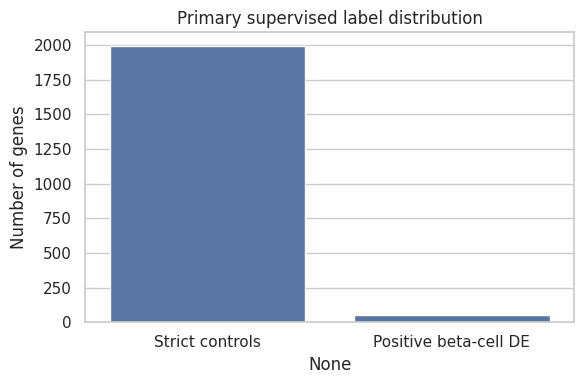

In [16]:
#@title 15. Figure helper
def savefig(name, dpi=300):
    plt.tight_layout()
    plt.savefig(FIG/f"{name}.png", dpi=dpi, bbox_inches="tight")
    plt.savefig(FIG/f"{name}.svg", bbox_inches="tight")
    plt.show()

# Class balance
plt.figure(figsize=(6,4))
counts = pd.Series({"Strict controls": int((y==0).sum()), "Positive beta-cell DE": int((y==1).sum())})
sns.barplot(x=counts.index, y=counts.values)
plt.ylabel("Number of genes")
plt.title("Primary supervised label distribution")
savefig("01_label_distribution")


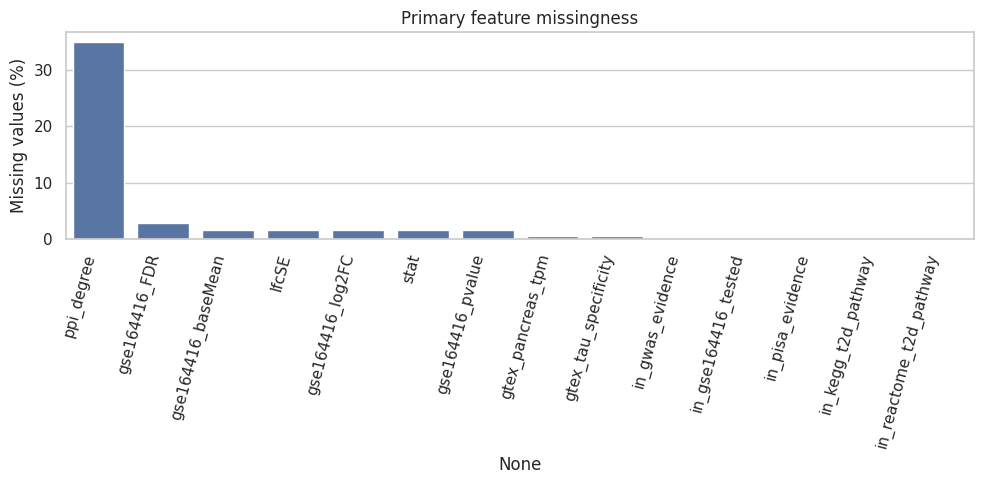

In [17]:
#@title 16. Missingness visualization
missing_pct = X.isna().mean().sort_values(ascending=False)
plt.figure(figsize=(10,5))
sns.barplot(x=missing_pct.index, y=100*missing_pct.values)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Missing values (%)")
plt.title("Primary feature missingness")
savefig("02_feature_missingness")

missing_pct.rename("missing_fraction").to_csv(TAB/"feature_missingness.csv")


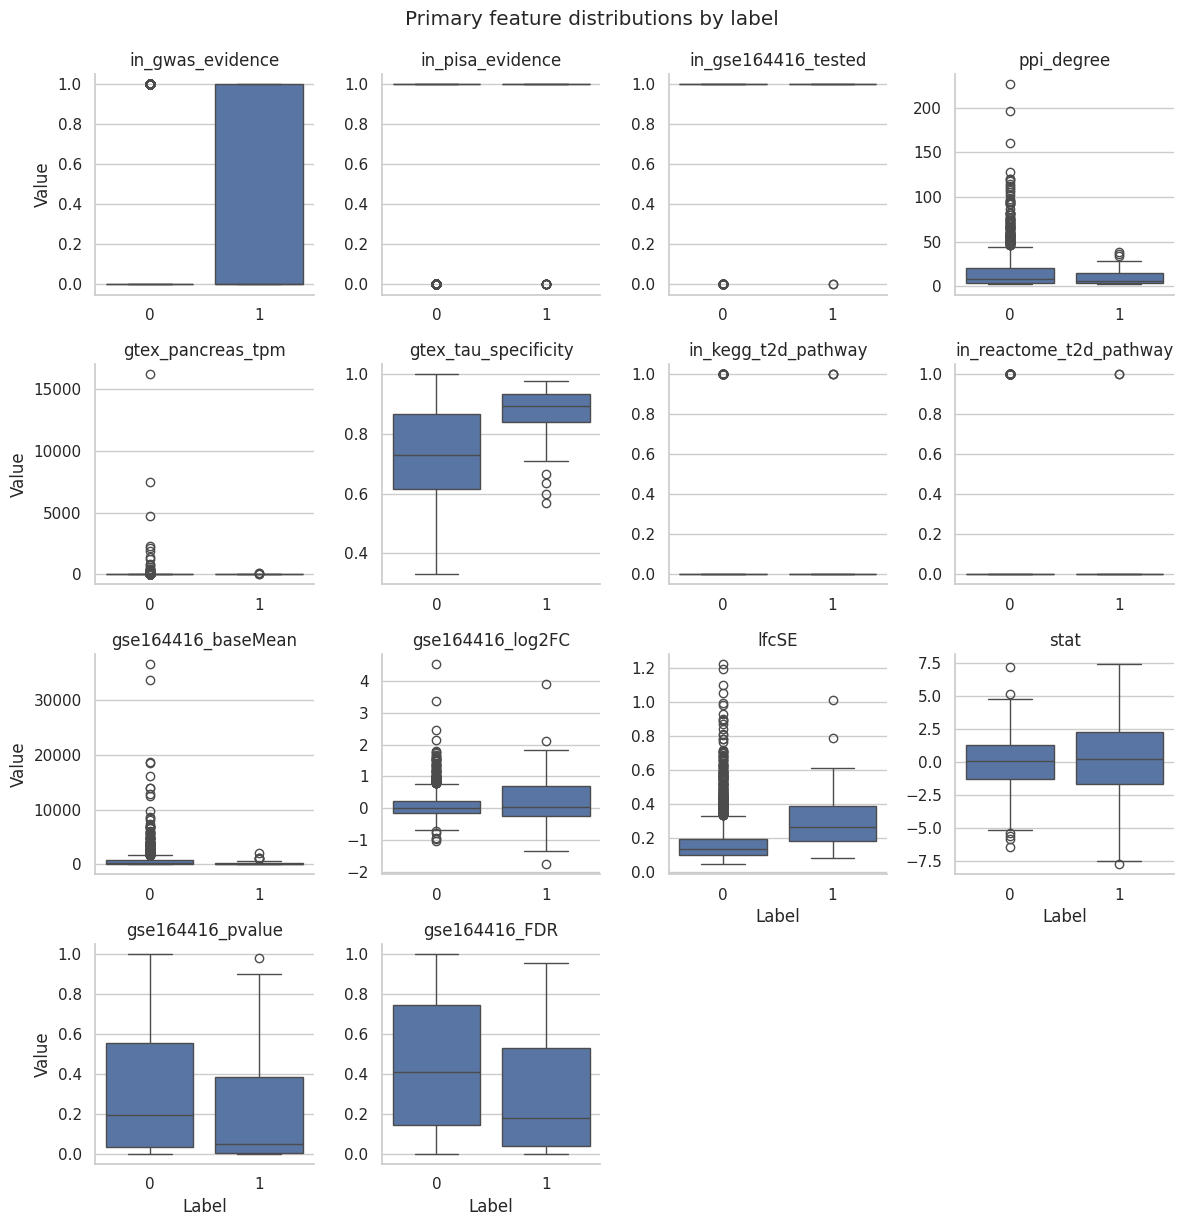

In [18]:
#@title 17. Feature distributions by class
long_parts = []
for f in PRIMARY_FEATURES:
    z = pd.DataFrame({"value": pd.to_numeric(X[f], errors="coerce"), "label": y.values})
    z["feature"] = f
    long_parts.append(z)
dist_df = pd.concat(long_parts, ignore_index=True)

# Robustly cap only for visualization, never for training.
g = sns.FacetGrid(dist_df, col="feature", col_wrap=4, sharex=False, sharey=False, height=3)
g.map_dataframe(sns.boxplot, x="label", y="value")
g.set_titles("{col_name}")
g.set_xlabels("Label")
g.set_ylabels("Value")
plt.suptitle("Primary feature distributions by label", y=1.02)
plt.savefig(FIG/"03_feature_distributions.png", dpi=300, bbox_inches="tight")
plt.savefig(FIG/"03_feature_distributions.svg", bbox_inches="tight")
plt.show()


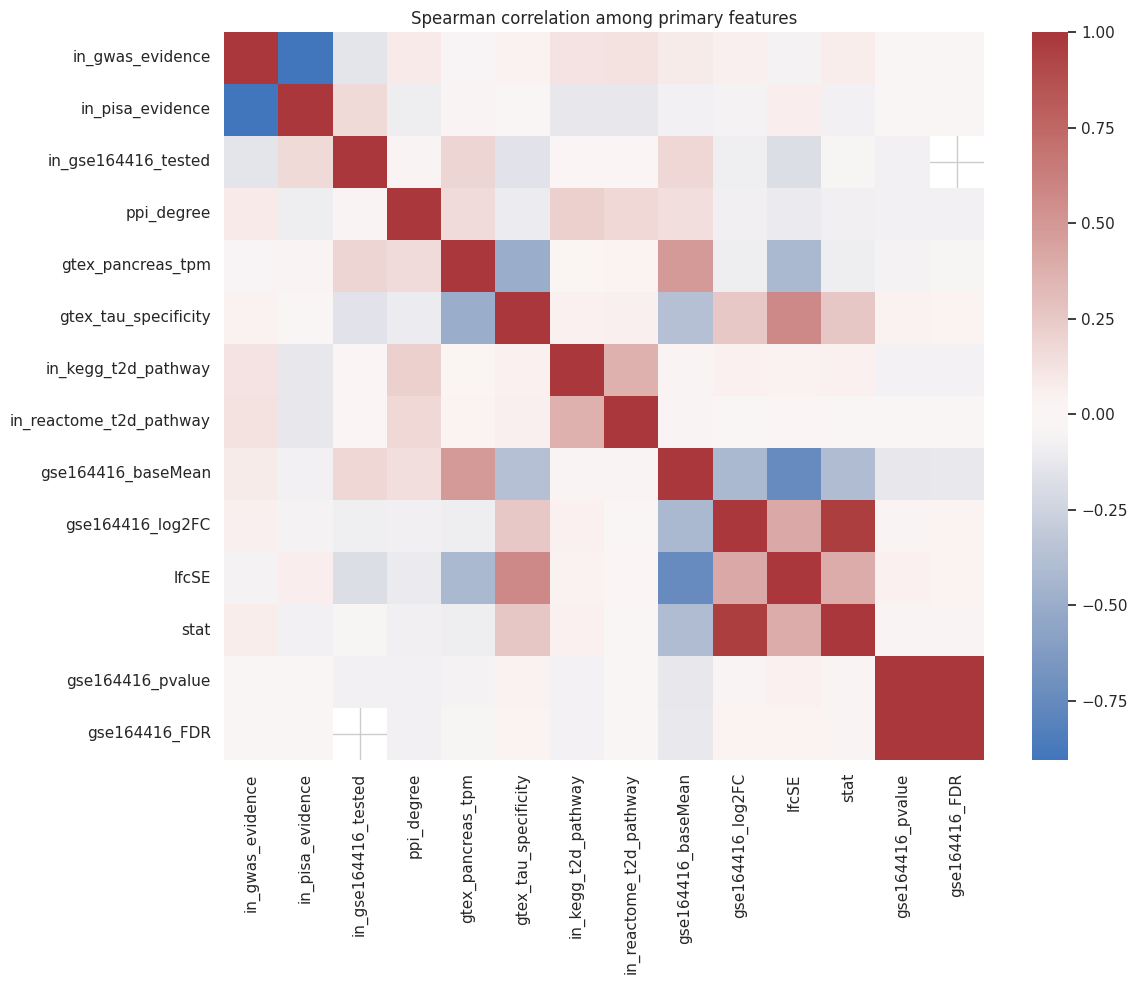

In [19]:
#@title 18. Correlation heatmap
corr = X.apply(pd.to_numeric, errors="coerce").corr(method="spearman")
plt.figure(figsize=(12,10))
sns.heatmap(corr, cmap="vlag", center=0, square=False)
plt.title("Spearman correlation among primary features")
savefig("04_feature_correlation")
corr.to_csv(TAB/"primary_feature_spearman_correlation.csv")


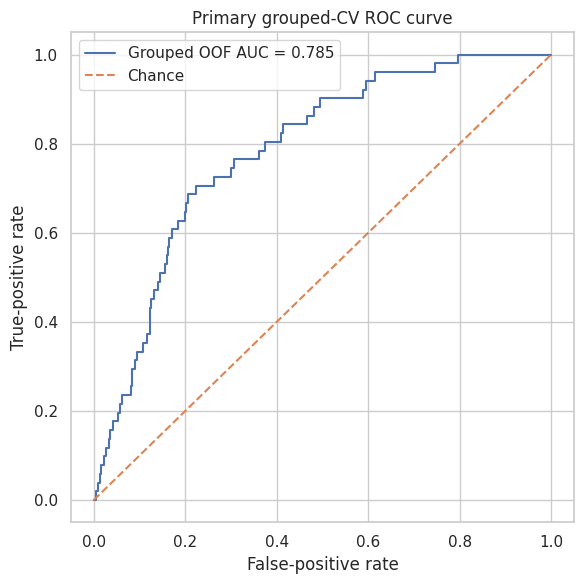

In [20]:
#@title 19. ROC curve
fpr, tpr, _ = roc_curve(y, oof)
plt.figure(figsize=(6,6))
plt.plot(fpr, tpr, label=f"Grouped OOF AUC = {roc_auc_score(y,oof):.3f}")
plt.plot([0,1],[0,1],"--", label="Chance")
plt.xlabel("False-positive rate")
plt.ylabel("True-positive rate")
plt.title("Primary grouped-CV ROC curve")
plt.legend()
savefig("05_primary_roc")


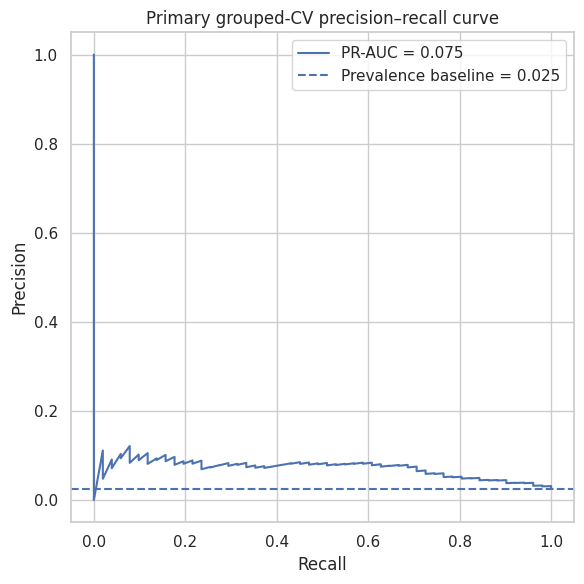

In [21]:
#@title 20. Precision–recall curve
precision, recall, _ = precision_recall_curve(y, oof)
baseline = y.mean()
plt.figure(figsize=(6,6))
plt.plot(recall, precision, label=f"PR-AUC = {average_precision_score(y,oof):.3f}")
plt.axhline(baseline, linestyle="--", label=f"Prevalence baseline = {baseline:.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Primary grouped-CV precision–recall curve")
plt.legend()
savefig("06_primary_pr")


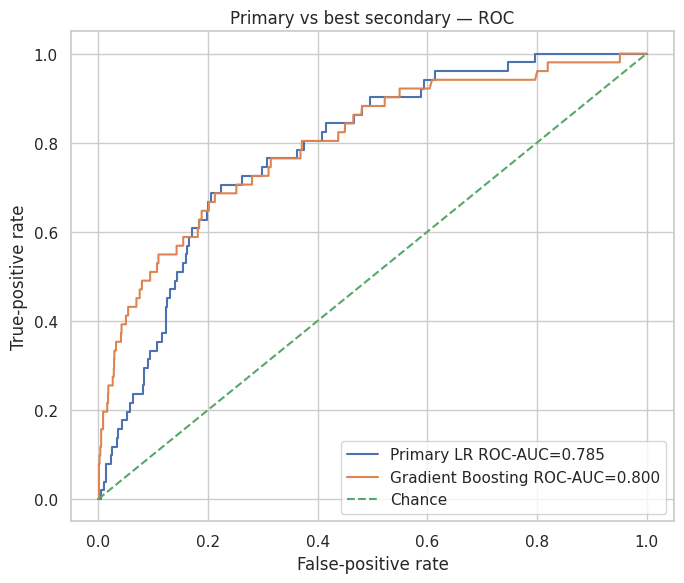

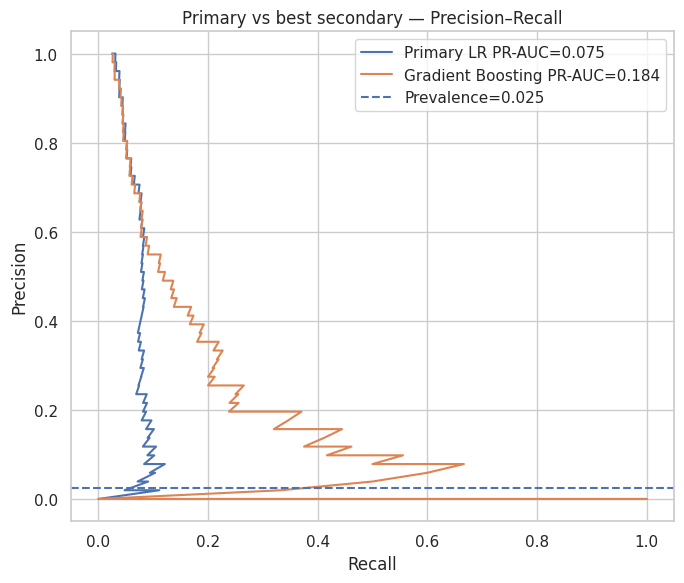

In [22]:
#@title 20B. Primary vs best-secondary ROC and PR curves
secondary_p=benchmark_oof[secondary_name]
fig,ax=plt.subplots(figsize=(7,6))
# ROC
fpr1,tpr1,_=roc_curve(y,oof)
fpr2,tpr2,_=roc_curve(y,secondary_p)
ax.plot(fpr1,tpr1,label=f"Primary LR ROC-AUC={roc_auc_score(y,oof):.3f}")
ax.plot(fpr2,tpr2,label=f"{secondary_name} ROC-AUC={roc_auc_score(y,secondary_p):.3f}")
ax.plot([0,1],[0,1],"--",label="Chance")
ax.set_xlabel("False-positive rate"); ax.set_ylabel("True-positive rate")
ax.set_title("Primary vs best secondary — ROC")
ax.legend(); plt.tight_layout(); savefig("06B_primary_vs_secondary_roc")

fig,ax=plt.subplots(figsize=(7,6))
r1,p1,_=precision_recall_curve(y,oof)
r2,p2,_=precision_recall_curve(y,secondary_p)
ax.plot(r1,p1,label=f"Primary LR PR-AUC={average_precision_score(y,oof):.3f}")
ax.plot(r2,p2,label=f"{secondary_name} PR-AUC={average_precision_score(y,secondary_p):.3f}")
ax.axhline(y.mean(),ls="--",label=f"Prevalence={y.mean():.3f}")
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.set_title("Primary vs best secondary — Precision–Recall")
ax.legend(); plt.tight_layout(); savefig("06B_primary_vs_secondary_pr")


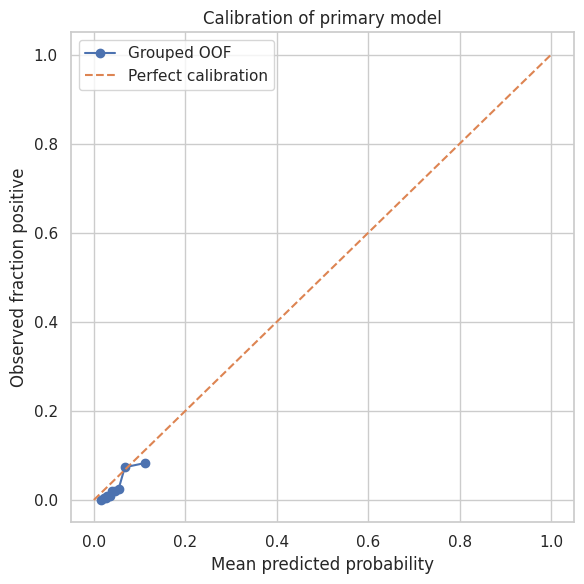

In [23]:
#@title 21. Calibration curve
prob_true, prob_pred = calibration_curve(y, oof, n_bins=10, strategy="quantile")
plt.figure(figsize=(6,6))
plt.plot(prob_pred, prob_true, marker="o", label="Grouped OOF")
plt.plot([0,1],[0,1],"--", label="Perfect calibration")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed fraction positive")
plt.title("Calibration of primary model")
plt.legend()
savefig("07_calibration")


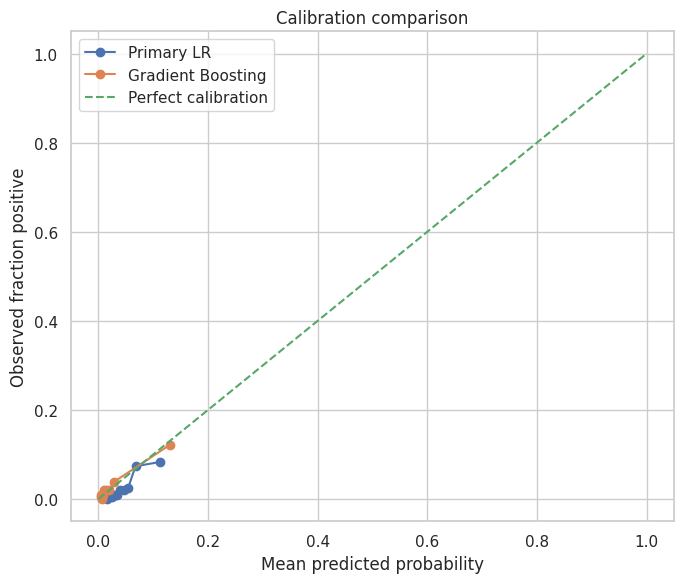

In [24]:
#@title 21B. Calibration comparison — primary vs best secondary
fig,ax=plt.subplots(figsize=(7,6))
for name,p in [("Primary LR",oof),(secondary_name,secondary_p)]:
    pt,pp=calibration_curve(y,p,n_bins=10,strategy="quantile")
    ax.plot(pp,pt,marker="o",label=name)
ax.plot([0,1],[0,1],"--",label="Perfect calibration")
ax.set_xlabel("Mean predicted probability"); ax.set_ylabel("Observed fraction positive")
ax.set_title("Calibration comparison")
ax.legend(); plt.tight_layout(); savefig("07B_calibration_comparison")


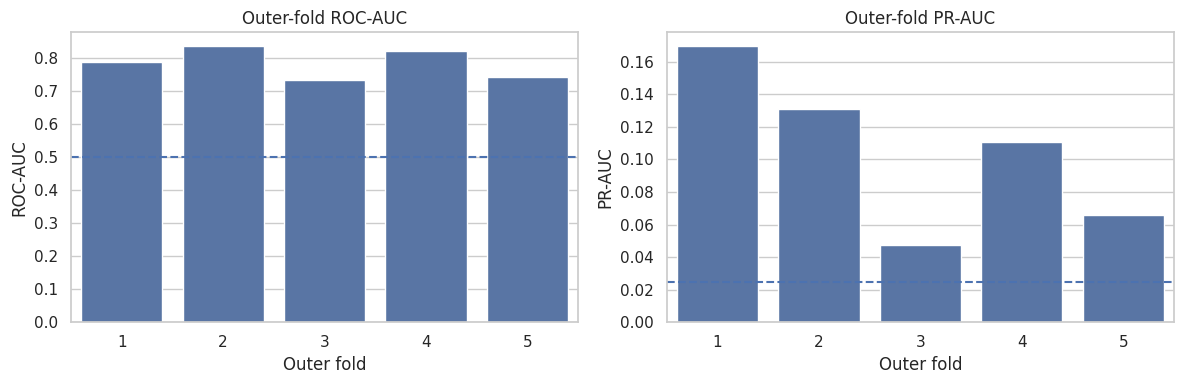

In [25]:
#@title 22. Fold-wise ROC / PR performance
fig, ax = plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=primary_folds, x="fold", y="roc_auc", ax=ax[0])
ax[0].axhline(0.5, ls="--")
ax[0].set_title("Outer-fold ROC-AUC")
ax[0].set_xlabel("Outer fold")
ax[0].set_ylabel("ROC-AUC")

sns.barplot(data=primary_folds, x="fold", y="pr_auc", ax=ax[1])
ax[1].axhline(y.mean(), ls="--")
ax[1].set_title("Outer-fold PR-AUC")
ax[1].set_xlabel("Outer fold")
ax[1].set_ylabel("PR-AUC")
plt.tight_layout()
plt.savefig(FIG/"08_fold_performance.png",dpi=300,bbox_inches="tight")
plt.savefig(FIG/"08_fold_performance.svg",bbox_inches="tight")
plt.show()


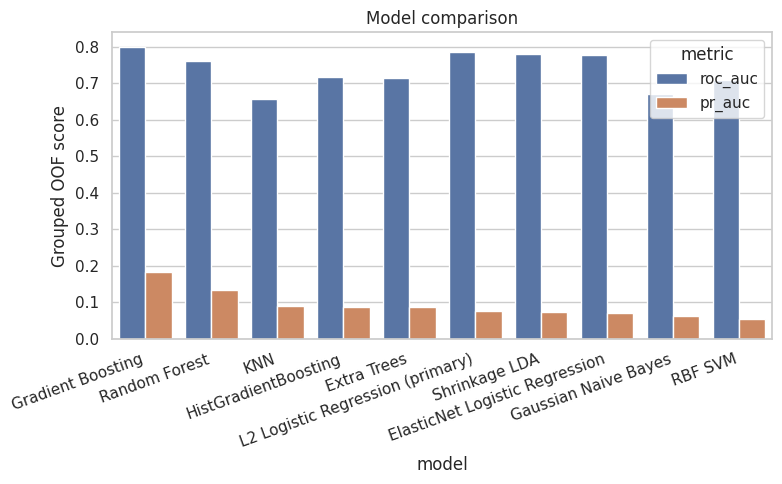

In [26]:
#@title 23. Model comparison figure
plt.figure(figsize=(8,5))
mc = model_comparison.melt(id_vars="model", value_vars=["roc_auc","pr_auc"], var_name="metric", value_name="score")
sns.barplot(data=mc, x="model", y="score", hue="metric")
plt.xticks(rotation=20, ha="right")
plt.ylabel("Grouped OOF score")
plt.title("Model comparison")
savefig("09_model_comparison")


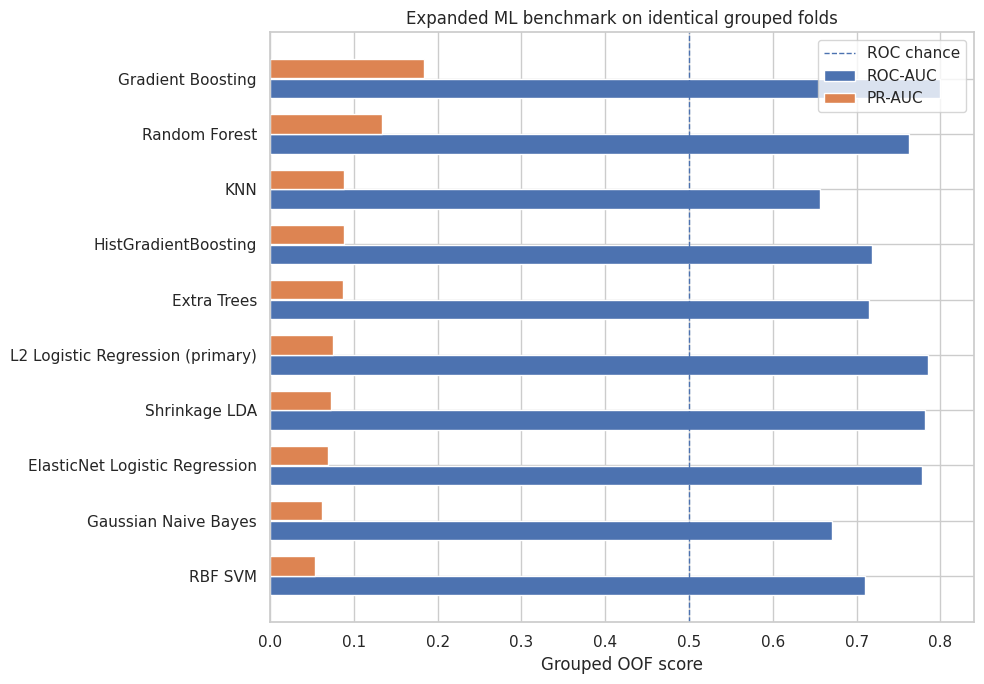

In [27]:
#@title 23B. Expanded model benchmark figure
plot_df=model_comparison.sort_values("pr_auc",ascending=True).copy()
fig,ax=plt.subplots(figsize=(10,7))
ypos=np.arange(len(plot_df))
ax.barh(ypos-0.18,plot_df["roc_auc"],height=0.35,label="ROC-AUC")
ax.barh(ypos+0.18,plot_df["pr_auc"],height=0.35,label="PR-AUC")
ax.set_yticks(ypos)
ax.set_yticklabels(plot_df["model"])
ax.axvline(0.5,ls="--",linewidth=1,label="ROC chance")
ax.set_xlabel("Grouped OOF score")
ax.set_title("Expanded ML benchmark on identical grouped folds")
ax.legend()
plt.tight_layout()
savefig("09B_expanded_model_benchmark")


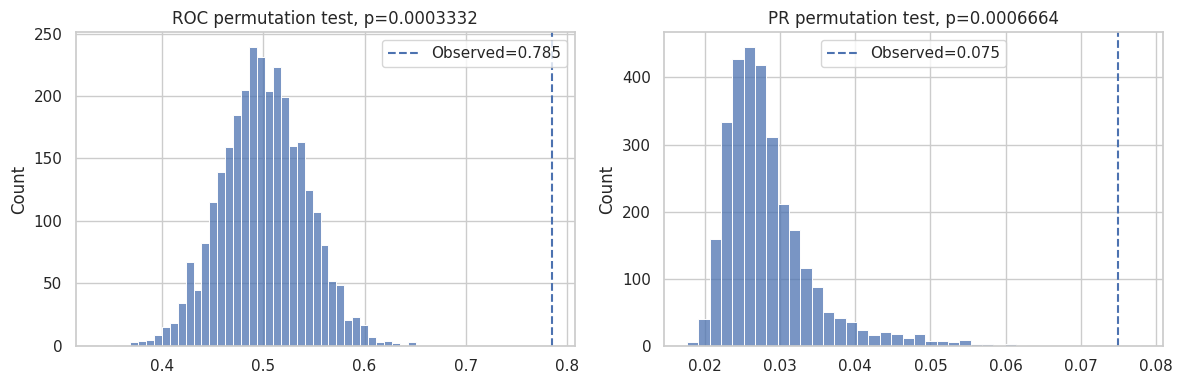

In [28]:
#@title 24. Permutation null distributions
fig, ax = plt.subplots(1,2,figsize=(12,4))
sns.histplot(roc_null, bins=40, ax=ax[0])
ax[0].axvline(roc_obs, ls="--", label=f"Observed={roc_obs:.3f}")
ax[0].set_title(f"ROC permutation test, p={roc_p:.4g}")
ax[0].legend()

sns.histplot(pr_null, bins=40, ax=ax[1])
ax[1].axvline(pr_obs, ls="--", label=f"Observed={pr_obs:.3f}")
ax[1].set_title(f"PR permutation test, p={pr_p:.4g}")
ax[1].legend()
plt.tight_layout()
plt.savefig(FIG/"10_permutation_tests.png",dpi=300,bbox_inches="tight")
plt.savefig(FIG/"10_permutation_tests.svg",bbox_inches="tight")
plt.show()


,rank,feature,coefficient,abs_coefficient,direction
0,1,gtex_tau_specificity,0.387297,0.387297,positive
1,2,gse164416_FDR,-0.289886,0.289886,negative
2,3,lfcSE,0.252946,0.252946,positive
3,4,in_gwas_evidence,0.225626,0.225626,positive
4,5,stat,-0.174451,0.174451,negative
5,6,gse164416_baseMean,-0.150327,0.150327,negative
6,7,ppi_degree,-0.141303,0.141303,negative
7,8,in_gse164416_tested,0.113786,0.113786,positive
8,9,in_pisa_evidence,0.110493,0.110493,positive
9,10,in_kegg_t2d_pathway,0.109552,0.109552,positive


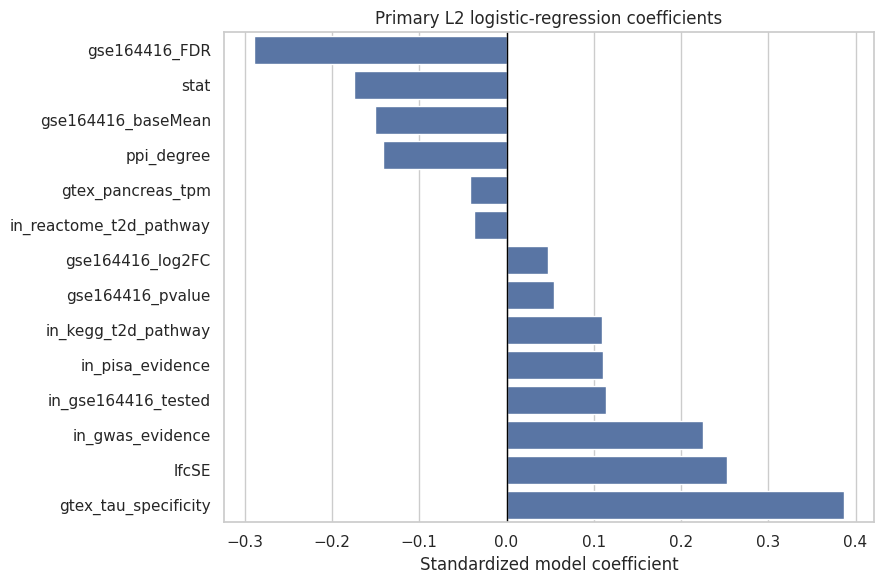

Coefficient count: 14
Feature count: 14
CELL 25: PASS


In [29]:
#@title 25. Fit primary full labeled model for interpretation / prioritization
# The final gene-level prioritization score remains the prespecified LR, C=0.1.
# Imputation does NOT add indicator columns: exactly 14 model coefficients correspond
# to exactly the 14 biological/statistical predictors.

final_model = make_lr(C=PRIMARY_C)
final_model.fit(X, y)

lr_core = final_model.named_steps["model"]
coef = np.asarray(lr_core.coef_).reshape(-1)

assert len(coef) == len(PRIMARY_FEATURES), (
    f"Coefficient mismatch: {len(coef)} coefficients for {len(PRIMARY_FEATURES)} features."
)

feature_importance = pd.DataFrame({
    "feature": PRIMARY_FEATURES,
    "coefficient": coef,
    "abs_coefficient": np.abs(coef),
})
feature_importance["direction"] = np.where(
    feature_importance["coefficient"] > 0, "positive",
    np.where(feature_importance["coefficient"] < 0, "negative", "zero")
)
feature_importance = feature_importance.sort_values(
    "abs_coefficient", ascending=False
).reset_index(drop=True)
feature_importance.insert(0, "rank", np.arange(1, len(feature_importance)+1))

display(feature_importance)
feature_importance.to_csv(TAB/"locked_lr_coefficients.csv", index=False)

plt.figure(figsize=(9,6))
tmp = feature_importance.sort_values("coefficient")
sns.barplot(data=tmp, y="feature", x="coefficient")
plt.axvline(0, color="black", lw=1)
plt.title("Primary L2 logistic-regression coefficients")
plt.xlabel("Standardized model coefficient")
plt.ylabel("")
savefig("11_feature_coefficients")

print("Coefficient count:", len(coef))
print("Feature count:", len(PRIMARY_FEATURES))
print("CELL 25: PASS")


,feature,mean_delta_pr,median_delta_pr,sd_delta_pr,mean_delta_roc
11,lfcSE,0.034796,0.029549,0.036720,0.065919
5,gtex_tau_specificity,0.025449,0.020044,0.023075,0.129422
0,gse164416_FDR,0.016478,0.010828,0.025477,0.042187
9,in_pisa_evidence,0.011130,0.002248,0.022318,-0.002288
6,in_gse164416_tested,0.008864,0.004898,0.010491,-0.000430
1,gse164416_baseMean,0.004813,0.003102,0.006398,0.006508
12,ppi_degree,0.004352,0.003952,0.009731,0.007047
13,stat,0.001603,0.001942,0.003267,0.032096
4,gtex_pancreas_tpm,0.000583,0.000027,0.001258,0.000733
3,gse164416_pvalue,-0.000397,-0.000221,0.001774,0.002986


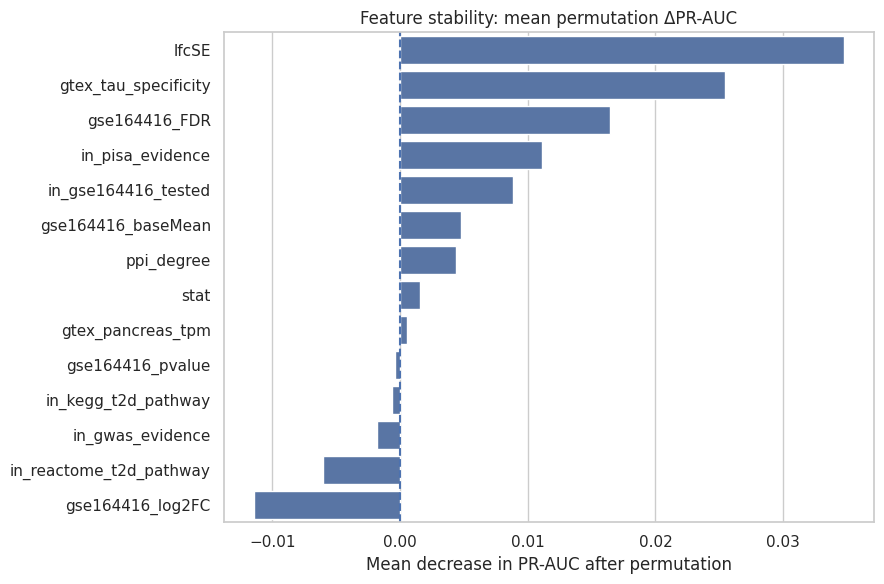

In [30]:
#@title 26. Fold-wise permutation feature stability (20 shuffles per feature per fold)
# Each outer fold computes permutation delta ROC/PR on held-out data. A single shuffle is very noisy with ~10
# positives per fold, so each feature is shuffled N_PERM_REPEATS times and the deltas are averaged.
N_PERM_REPEATS = 20
stab_rows = []
outer = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)

for fold, (tr, te) in enumerate(outer.split(X, y, groups), 1):
    m = make_lr(C=0.1)
    m.fit(X.iloc[tr], y.iloc[tr])
    base_p = m.predict_proba(X.iloc[te])[:,1]
    base_pr = average_precision_score(y.iloc[te], base_p)
    base_roc = roc_auc_score(y.iloc[te], base_p)

    rng = np.random.default_rng(SEED + fold)
    for j, f in enumerate(PRIMARY_FEATURES):
        d_pr, d_roc = [], []
        for _ in range(N_PERM_REPEATS):
            Xp = X.iloc[te].copy()
            vals = Xp[f].to_numpy().copy()
            rng.shuffle(vals)
            Xp[f] = vals
            pp = m.predict_proba(Xp)[:,1]
            d_pr.append(base_pr - average_precision_score(y.iloc[te], pp))
            d_roc.append(base_roc - roc_auc_score(y.iloc[te], pp))
        stab_rows.append({
            "fold":fold,
            "feature":f,
            "delta_pr_auc":float(np.mean(d_pr)),
            "delta_roc_auc":float(np.mean(d_roc)),
            "n_repeats":N_PERM_REPEATS
        })

stability = pd.DataFrame(stab_rows)
stability_summary = stability.groupby("feature").agg(
    mean_delta_pr=("delta_pr_auc","mean"),
    median_delta_pr=("delta_pr_auc","median"),
    sd_delta_pr=("delta_pr_auc","std"),
    mean_delta_roc=("delta_roc_auc","mean")
).reset_index().sort_values("mean_delta_pr",ascending=False)

display(stability_summary)
stability.to_csv(TAB/"feature_stability_by_fold.csv",index=False)
stability_summary.to_csv(TAB/"feature_stability_summary.csv",index=False)

plt.figure(figsize=(9,6))
sns.barplot(data=stability_summary.head(14), y="feature", x="mean_delta_pr")
plt.axvline(0,ls="--")
plt.title("Feature stability: mean permutation ΔPR-AUC")
plt.xlabel("Mean decrease in PR-AUC after permutation")
plt.ylabel("")
savefig("12_feature_stability")


,PISA_gene_id,gene_symbol,primary_LR_score,primary_LR_rank,label
1197,NaN,ENSG00000256417,0.499814,1,NaN
853,NaN,ENSG00000225028,0.344177,2,NaN
2112,NaN,LEP,0.340238,3,NaN
3743,NaN,ZAN,0.325643,4,NaN
2652,NaN,PIP,0.294408,5,NaN
421,NaN,CD177,0.282247,6,NaN
1698,NaN,FCRLA,0.277079,7,NaN
435,NaN,CDH7,0.264870,8,NaN
3644,NaN,UGT2B11,0.261905,9,0.0
3207,NaN,SLC6A14,0.256948,10,0.0


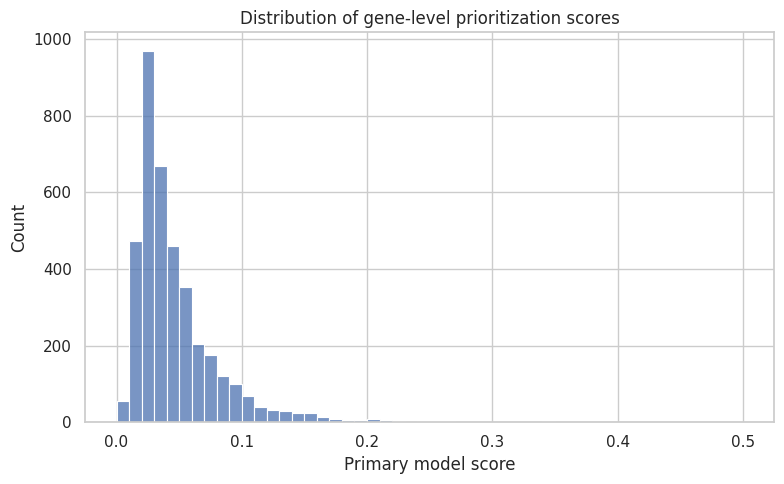

In [31]:
#@title 27. Gene-level score and ranking
all_X = df[PRIMARY_FEATURES].copy()
df_scores = df.copy()
df_scores["primary_LR_score"] = final_model.predict_proba(all_X)[:,1]
df_scores["primary_LR_rank"] = (
    df_scores["primary_LR_score"].rank(method="min", ascending=False).astype(int)
)

score_cols = [c for c in [
    "PISA_gene_id","gene_id","gene_symbol","symbol","gene",
    "primary_LR_score","primary_LR_rank",target_col
] if c in df_scores.columns]

top_genes = df_scores.sort_values("primary_LR_score",ascending=False).head(100)[score_cols]
display(top_genes.head(30))

top_genes.to_csv(TAB/"top100_gene_prioritization.csv",index=False)
df_scores[score_cols].to_csv(TAB/"all_gene_scores.csv",index=False)

plt.figure(figsize=(8,5))
sns.histplot(df_scores["primary_LR_score"], bins=50)
plt.xlabel("Primary model score")
plt.title("Distribution of gene-level prioritization scores")
savefig("13_gene_score_distribution")


In [32]:
#@title 27B. Secondary-model gene ranking (exploratory)
# Fit the best secondary model on all labeled genes only after its benchmark is complete.
# This ranking is exploratory and is never used to define the primary target or performance.
secondary_full_model=clone(BENCHMARK_MODELS[secondary_name])
secondary_full_model.fit(X,y)
df_scores["secondary_model_score"]=secondary_full_model.predict_proba(all_X)[:,1]
df_scores["secondary_model_rank"]=df_scores["secondary_model_score"].rank(method="min",ascending=False).astype(int)
secondary_top=df_scores.sort_values("secondary_model_score",ascending=False).head(100)[score_cols+["secondary_model_score","secondary_model_rank"]]
secondary_top.to_csv(TAB/"top100_best_secondary_model_prioritization.csv",index=False)
print("Exploratory secondary ranking model:",secondary_name)
display(secondary_top.head(30))


Exploratory secondary ranking model: Gradient Boosting


,PISA_gene_id,gene_symbol,primary_LR_score,primary_LR_rank,label,secondary_model_score,secondary_model_rank
2585,NaN,PCOLCE2,0.105393,253,1.0,0.801219,1
1640,NaN,FAIM2,0.116472,192,1.0,0.762526,2
2614,NaN,PENK,0.252111,11,NaN,0.716239,3
3179,NaN,SLC2A2,0.228725,17,1.0,0.703861,4
3601,NaN,TTBK1,0.075822,576,1.0,0.689186,5
2851,NaN,RASGRP1,0.147926,100,NaN,0.687356,6
1769,NaN,GAD1,0.167673,59,1.0,0.665214,7
2610,NaN,PDZRN4,0.090351,386,NaN,0.659839,8
339,NaN,C6orf58,0.160716,67,NaN,0.659797,9
71,NaN,ADGRB3,0.076749,561,1.0,0.649698,10


HELD-OUT Precision@K (headline):


,scores,k,hits,precision,baseline,enrichment,recall_at_k,basis
0,L2 LR - single grouped split (seed 20260910),10,1,0.100,0.024976,4.003922,0.019608,held-out (out-of-fold)
1,L2 LR - single grouped split (seed 20260910),20,1,0.050,0.024976,2.001961,0.019608,held-out (out-of-fold)
2,L2 LR - single grouped split (seed 20260910),40,4,0.100,0.024976,4.003922,0.078431,held-out (out-of-fold)
3,L2 LR - single grouped split (seed 20260910),50,5,0.100,0.024976,4.003922,0.098039,held-out (out-of-fold)
4,L2 LR - single grouped split (seed 20260910),100,9,0.090,0.024976,3.603529,0.176471,held-out (out-of-fold)
5,L2 LR - single grouped split (seed 20260910),200,16,0.080,0.024976,3.203137,0.313725,held-out (out-of-fold)
6,L2 LR - single grouped split (seed 20260910),500,36,0.072,0.024976,2.882824,0.705882,held-out (out-of-fold)


APPARENT in-sample Precision@K (do not report as performance):


,scores,k,hits,precision,baseline,enrichment,recall_at_k,basis
0,L2 LR - final model fitted on all labeled gene...,10,2,0.200,0.024976,8.007843,0.039216,"in-sample (apparent, not held-out)"
1,L2 LR - final model fitted on all labeled gene...,20,4,0.200,0.024976,8.007843,0.078431,"in-sample (apparent, not held-out)"
2,L2 LR - final model fitted on all labeled gene...,40,5,0.125,0.024976,5.004902,0.098039,"in-sample (apparent, not held-out)"
3,L2 LR - final model fitted on all labeled gene...,50,8,0.160,0.024976,6.406275,0.156863,"in-sample (apparent, not held-out)"
4,L2 LR - final model fitted on all labeled gene...,100,14,0.140,0.024976,5.605490,0.274510,"in-sample (apparent, not held-out)"
5,L2 LR - final model fitted on all labeled gene...,200,22,0.110,0.024976,4.404314,0.431373,"in-sample (apparent, not held-out)"
6,L2 LR - final model fitted on all labeled gene...,500,38,0.076,0.024976,3.042980,0.745098,"in-sample (apparent, not held-out)"


,k,heldout_hits,heldout_precision,heldout_enrichment,apparent_hits,apparent_precision,apparent_enrichment,prevalence
0,10,1,0.10,4.003922,2,0.200,8.007843,0.024976
1,20,1,0.05,2.001961,4,0.200,8.007843,0.024976
2,40,4,0.10,4.003922,5,0.125,5.004902,0.024976
3,100,9,0.09,3.603529,14,0.140,5.605490,0.024976


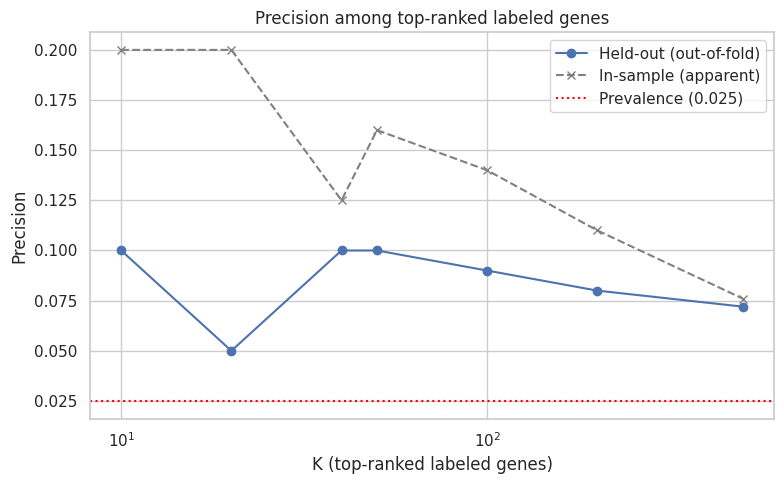

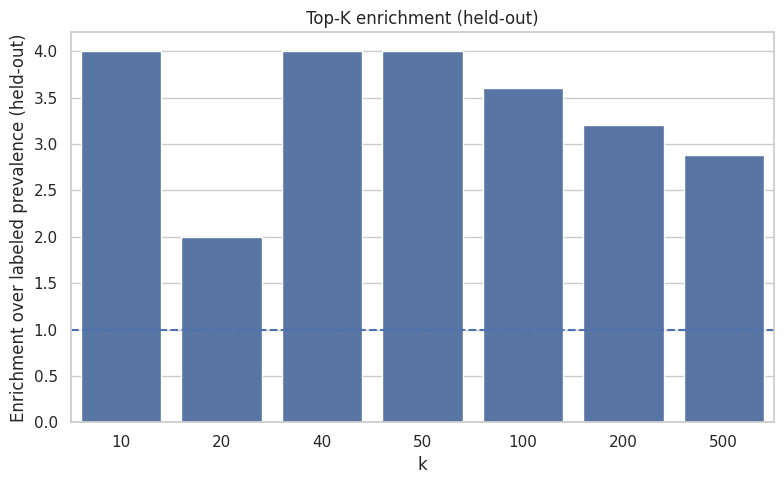

In [33]:
#@title 28. Precision@K and enrichment — HELD-OUT (headline) and in-sample (apparent, comparison only)
# Headline Precision@K uses the out-of-fold predictions of the primary model. The final model fitted on all
# labeled genes scores its own training genes, so those values are APPARENT (optimistic) and are kept only to
# show the size of the optimism.
ks = [10,20,40,50,100,200,500]
baseline = float(y.mean())

def precision_at_k_table(y_arr, score, label, basis):
    y_arr = np.asarray(y_arr); score = np.asarray(score, dtype=float)
    order = np.argsort(-score, kind="mergesort")
    ys = y_arr[order]
    rows = []
    for k in ks:
        kk = min(k, len(ys)); hit = int(ys[:kk].sum()); prec = hit / kk
        rows.append({"scores": label, "k": k, "hits": hit, "precision": prec, "baseline": baseline,
                     "enrichment": prec / baseline if baseline > 0 else np.nan,
                     "recall_at_k": hit / int(y_arr.sum()), "basis": basis})
    return pd.DataFrame(rows)

p_at_k_heldout = precision_at_k_table(
    y, oof, f"L2 LR - single grouped split (seed {SEED})", "held-out (out-of-fold)")
apparent_scores = df_scores.loc[X.index, "primary_LR_score"].to_numpy()
p_at_k_apparent = precision_at_k_table(
    y, apparent_scores, "L2 LR - final model fitted on all labeled genes (APPARENT, in-sample)",
    "in-sample (apparent, not held-out)")

print("HELD-OUT Precision@K (headline):")
display(p_at_k_heldout)
print("APPARENT in-sample Precision@K (do not report as performance):")
display(p_at_k_apparent)

p_at_k_heldout.to_csv(TAB/"precision_at_k.csv", index=False)
p_at_k_apparent.to_csv(TAB/"precision_at_k_apparent_insample.csv", index=False)

# Table 4 layout: held-out next to apparent for K = 10, 20, 40, 100
t4 = p_at_k_heldout[p_at_k_heldout.k.isin([10,20,40,100])][["k","hits","precision","enrichment"]].rename(
    columns={"hits":"heldout_hits","precision":"heldout_precision","enrichment":"heldout_enrichment"})
t4 = t4.merge(p_at_k_apparent[p_at_k_apparent.k.isin([10,20,40,100])][["k","hits","precision","enrichment"]].rename(
    columns={"hits":"apparent_hits","precision":"apparent_precision","enrichment":"apparent_enrichment"}), on="k")
t4["prevalence"] = baseline
display(t4)
t4.to_csv(TAB/"table4_topk_heldout_vs_apparent.csv", index=False)

plt.figure(figsize=(8,5))
plt.plot(p_at_k_heldout.k, p_at_k_heldout.precision, marker="o", label="Held-out (out-of-fold)")
plt.plot(p_at_k_apparent.k, p_at_k_apparent.precision, marker="x", ls="--", color="gray", label="In-sample (apparent)")
plt.axhline(baseline, ls=":", color="red", label=f"Prevalence ({baseline:.3f})")
plt.xscale("log"); plt.xlabel("K (top-ranked labeled genes)"); plt.ylabel("Precision")
plt.title("Precision among top-ranked labeled genes"); plt.legend()
savefig("14_precision_at_k")

plt.figure(figsize=(8,5))
sns.barplot(data=p_at_k_heldout,x="k",y="enrichment")
plt.axhline(1,ls="--")
plt.ylabel("Enrichment over labeled prevalence (held-out)")
plt.title("Top-K enrichment (held-out)")
savefig("15_topk_enrichment")


# 29. Supplementary GSE164416 stress test

This is a **supplementary stress test, not an independent external validation**.

* **Labels** are computed from the workbook using GSE164416 differential-expression results: positives = `gse164416_FDR < 0.05`; controls = `gse164416_FDR >= 0.05` and `|gse164416_log2FC| < log2(1.2)`.
* **Predictors:** every GSE164416-derived feature is removed, including `lfcSE` and `stat` (which come from the same GSE164416 DESeq2 output). The model is trained on the primary GSE221156 labels using the remaining 7 non-GSE164416 features (C = 0.1).
* Many evaluation genes also appear in the training set, and the evaluation labels come from the same GSE164416 source that supplies several primary predictors, so results must be read as a stress test only.


In [34]:
#@title 30. Supplementary GSE164416 stress test (computed from the workbook)
# Labels: GSE164416 FDR / log2FC. Predictors: ONLY features with no GSE164416 origin.
GSE164416_DERIVED = {"lfcSE", "stat"}   # DESeq2 outputs from GSE164416 whose names carry no prefix

fdr_e = pd.to_numeric(df["gse164416_FDR"], errors="coerce")
lfc_e = pd.to_numeric(df["gse164416_log2FC"], errors="coerce")

ext_pos = fdr_e < 0.05
ext_ctl = (fdr_e >= 0.05) & (lfc_e.abs() < np.log2(1.2))
ext_mask = (ext_pos | ext_ctl)
ye = ext_pos[ext_mask].astype(int)

external_feature_cols = [
    c for c in PRIMARY_FEATURES
    if "gse164416" not in c.lower() and c not in GSE164416_DERIVED
]
print("Features used in stress test:", len(external_feature_cols))
print(external_feature_cols)
assert not any("gse164416" in c.lower() or c in GSE164416_DERIVED for c in external_feature_cols)

overlap = int((ext_mask & labeled).sum())
print(f"Evaluation genes: {len(ye)} | positives: {int(ye.sum())} | controls: {int((ye==0).sum())}")
print(f"Evaluation genes that are also in the primary training set: {overlap}")

ext_model = make_lr(C=PRIMARY_C)
ext_model.fit(X.loc[:, external_feature_cols], y)
Xe = df.loc[ext_mask, external_feature_cols].apply(pd.to_numeric, errors="coerce")
pe = ext_model.predict_proba(Xe)[:, 1]

external_result = {
    "status": "computed_from_workbook",
    "roc_auc": float(roc_auc_score(ye, pe)),
    "pr_auc": float(average_precision_score(ye, pe)),
    "brier": float(safe_brier(ye, pe)),
    "n_genes": int(len(ye)),
    "positives": int(ye.sum()),
    "controls": int((ye == 0).sum()),
    "n_features": len(external_feature_cols),
    "n_eval_genes_in_training_set": overlap,
}
display(pd.DataFrame([external_result]))
pd.DataFrame([external_result]).to_csv(TAB/"external_gse164416_summary.csv", index=False)


Features used in stress test: 7
['in_gwas_evidence', 'in_pisa_evidence', 'ppi_degree', 'gtex_pancreas_tpm', 'gtex_tau_specificity', 'in_kegg_t2d_pathway', 'in_reactome_t2d_pathway']
Evaluation genes: 2224 | positives: 363 | controls: 1861
Evaluation genes that are also in the primary training set: 1517


,status,roc_auc,pr_auc,brier,n_genes,positives,controls,n_features,n_eval_genes_in_training_set
0,computed_from_workbook,0.579577,0.225339,0.150245,2224,363,1861,7,1517


In [35]:
#@title 31. Reproducibility manifest
manifest = {
    "timestamp_utc": datetime.now(timezone.utc).isoformat(),
    "python": sys.version,
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": __import__("sklearn").__version__,
    "dataset_filename": XLSX.name,
    "dataset_sha256": hashlib.sha256(XLSX.read_bytes()).hexdigest(),
    "gene_sheet": "FINAL_3868_GENE_DATASET",
    "gene_sheet_runtime": gene_sheet,
    "n_rows_gene_table": int(len(df)),
    "n_labeled": int(len(y)),
    "n_positive": int(y.sum()),
    "n_control": int((y==0).sum()),
    "primary_features": PRIMARY_FEATURES,
    "forbidden_prefixes": FORBIDDEN_PREFIXES,
    "grouping_method": group_method,
    "n_groups": int(len(np.unique(groups))),
    "primary_metrics": primary_metrics,
    "primary_C": 0.1,
    "primary_model": "L2 Logistic Regression",
    "primary_imputer_add_indicator": False,
    "best_secondary_model_by_grouped_pr_auc": secondary_name,
    "expanded_model_benchmark": model_comparison.to_dict(orient="records"),
    "bootstrap_roc_ci": [roc_ci[0], roc_ci[1]],
    "bootstrap_pr_ci": [pr_ci[0], pr_ci[1]],
    "permutation_roc_p": float(roc_p),
    "permutation_pr_p": float(pr_p),
    "external_locked": external_result,
    "id_mapping": ID_MAPPING_INFO,
    "seed": SEED,
}
with open(OUT/"run_manifest.json","w") as f:
    json.dump(manifest,f,indent=2,default=str)

print(json.dumps(manifest, indent=2, default=str))


{
  "timestamp_utc": "2026-10-22T05:04:54.634453+00:00",
  "python": "3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]",
  "platform": "Linux-6.6.122+-x86_64-with-glibc2.39",
  "numpy": "2.1.3",
  "pandas": "2.2.3",
  "sklearn": "1.6.1",
  "dataset_filename": "T2D_Final_Dataset_with_HGNC_Ensembl.xlsx",
  "dataset_sha256": "13d8ac5c3088c385414983cf1bc4ff8f18c201c3aa7b5daf22c0ab6cd008ea66",
  "gene_sheet": "FINAL_3868_GENE_DATASET",
  "gene_sheet_runtime": "FINAL_3868_GENE_DATASET",
  "n_rows_gene_table": 3868,
  "n_labeled": 2042,
  "n_positive": 51,
  "n_control": 1991,
  "primary_features": [
    "in_gwas_evidence",
    "in_pisa_evidence",
    "in_gse164416_tested",
    "ppi_degree",
    "gtex_pancreas_tpm",
    "gtex_tau_specificity",
    "in_kegg_t2d_pathway",
    "in_reactome_t2d_pathway",
    "gse164416_baseMean",
    "gse164416_log2FC",
    "lfcSE",
    "stat",
    "gse164416_pvalue",
    "gse164416_FDR"
  ],
  "forbidden_prefixes": [
    "gse221156_",
    "emtab5061_"
  ],
  "

In [36]:
#@title 32. Save final ML benchmark results workbook
results_xlsx=OUT/"T2D_v10_FULL_ML_FINAL_MODEL_BENCHMARK_RESULTS.xlsx"
with pd.ExcelWriter(results_xlsx,engine="openpyxl") as writer:
    pd.DataFrame([primary_metrics]).to_excel(writer,index=False,sheet_name="Locked_Primary_Summary")
    primary_folds.to_excel(writer,index=False,sheet_name="Locked_Primary_Folds")
    repeated_metrics.to_excel(writer,index=False,sheet_name="Repeated_LR")
    model_comparison.to_excel(writer,index=False,sheet_name="Expanded_Model_Benchmark")
    repeated_benchmark.to_excel(writer,index=False,sheet_name="Repeated_Benchmark")
    ci_df.to_excel(writer,index=False,sheet_name="Bootstrap_CI")
    perm_summary.to_excel(writer,index=False,sheet_name="Permutation")
    feature_importance.to_excel(writer,index=False,sheet_name="LR_Coefficients")
    stability_summary.to_excel(writer,index=False,sheet_name="Feature_Stability")
    p_at_k_heldout.to_excel(writer,index=False,sheet_name="Precision_at_K_heldout")
    p_at_k_apparent.to_excel(writer,index=False,sheet_name="Precision_at_K_apparent")
    nested_audit.to_excel(writer,index=False,sheet_name="Nested_fixed_config_audit")
    top_genes.to_excel(writer,index=False,sheet_name="Top100_LR_Genes")
    secondary_top.to_excel(writer,index=False,sheet_name="Top100_Secondary_Genes")
    pd.DataFrame([external_result]).to_excel(writer,index=False,sheet_name="External_GSE164416")
print("Saved:",results_xlsx)


Saved: /content/T2D_v10_ML_Results/T2D_v10_FULL_ML_FINAL_MODEL_BENCHMARK_RESULTS.xlsx


# 33. Final scientific QA

Before using any result in the manuscript, confirm:

- **No GSE221156-derived variable is a primary predictor.**
- **No E-MTAB-5061 variable is a primary predictor.**
- **No 2026 same-cohort beta-cell field is a primary predictor.**
- Imputation/scaling occur inside model pipelines.
- Outer-fold predictions are generated on held-out data.
- Grouping is performed before model fitting.
- Primary metrics are ROC-AUC, PR-AUC, Brier/calibration and enrichment—not raw accuracy.
- External GSE164416 results are retained transparently and not selectively deleted.
- The model predicts the defined beta-cell T2D differential-expression phenotype; it does **not** establish causality.

The workbook itself records the 14-feature allow-list, leakage status, and reporting restrictions.
- **Headline Precision@K is held-out (out-of-fold); in-sample values are labelled 'apparent'.**
- **Single-split secondary-model numbers are accompanied by the 10-seed mean ± SD.**
- **The confound diagnostic (36I) is reported alongside the primary metrics.**


In [37]:
#@title 34. Final scientific QA assertions
assert gene_sheet == "FINAL_3868_GENE_DATASET"
assert len(df) == 3868
assert len(PRIMARY_FEATURES)==14
assert forbidden_predictors==[]
assert not any("gse221156" in f.lower() for f in PRIMARY_FEATURES)
assert not any("emtab5061" in f.lower() for f in PRIMARY_FEATURES)
assert PRIMARY_C==0.1
assert set(primary_folds["C"].unique())=={0.1}
assert len(model_comparison)>=8
assert primary_metrics["roc_auc"]>=0.5
assert np.isfinite(primary_metrics["roc_auc"])
assert np.isfinite(primary_metrics["pr_auc"])
assert secondary_name in BENCHMARK_MODELS
assert "coef" in globals() and len(coef) == len(PRIMARY_FEATURES)

# Every row below is COMPUTED from the objects created in this run (nothing is hard-coded True).
_cv_chk = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
group_overlap = 0
for _tr, _te in _cv_chk.split(X, y, groups):
    group_overlap += len(set(groups[_tr]) & set(groups[_te]))

checks = [
    ("Canonical gene sheet is FINAL_3868_GENE_DATASET", gene_sheet == "FINAL_3868_GENE_DATASET"),
    ("Exactly 14 predictors, in the declared order", list(X.columns) == PRIMARY_FEATURES and len(PRIMARY_FEATURES) == 14),
    ("No GSE221156 / E-MTAB-5061 / 2026 field among predictors",
     not any(k in f.lower() for f in PRIMARY_FEATURES for k in ("gse221156", "emtab5061", "2026"))),
    ("Label counts are 51 / 1991 / 1826", (int((y == 1).sum()), int((y == 0).sum()), int((~labeled).sum())) == (51, 1991, 1826)),
    ("C = 0.1 in every outer fold", set(primary_folds["C"].unique()) == {0.1}),
    ("Out-of-fold predictions complete (no NaN)", not np.isnan(oof).any()),
    ("No group shared between train and test in any outer fold", group_overlap == 0),
    ("Imputer adds no indicator columns", not make_lr().named_steps["imputer"].add_indicator),
    ("One coefficient per predictor", len(coef) == len(PRIMARY_FEATURES)),
    ("Primary metrics finite", all(np.isfinite(v) for v in primary_metrics.values())),
    ("Headline Precision@K is computed from held-out OOF predictions",
     bool((p_at_k_heldout["basis"] == "held-out (out-of-fold)").all()) and not p_at_k_heldout["precision"].isna().any()),
    ("Fixed-configuration nested audit reproduces the primary OOF predictions", bool(nested_matches_primary)),
    ("Group audit computed", "group_audit" in globals()),
    ("Identifier mapping present (HGNC / Ensembl columns)", all(c in df.columns for c in ID_NEW_COLS)),
    ("No labeled gene is flagged as a redundant duplicate row",
     not (df["duplicate_resolution"].eq("exclude_duplicate_row") & labeled).any()),
    ("No duplicate Ensembl IDs among retained rows",
     not df.loc[df["duplicate_resolution"].ne("exclude_duplicate_row"), "ensembl_gene_id_grch38"].dropna().duplicated().any()),
]
qa = pd.DataFrame(checks, columns=["check", "pass"])
assert qa["pass"].all(), qa[~qa["pass"]]
display(qa)
qa.to_csv(TAB/"final_qa.csv",index=False)
print("FINAL QA: PASS")
print("Primary:",primary_metrics)
print("Best secondary by grouped PR-AUC:",secondary_name)


,check,pass
0,Canonical gene sheet is FINAL_3868_GENE_DATASET,True
1,"Exactly 14 predictors, in the declared order",True
2,No GSE221156 / E-MTAB-5061 / 2026 field among ...,True
3,Label counts are 51 / 1991 / 1826,True
4,C = 0.1 in every outer fold,True
5,Out-of-fold predictions complete (no NaN),True
6,No group shared between train and test in any ...,True
7,Imputer adds no indicator columns,True
8,One coefficient per predictor,True
9,Primary metrics finite,True


FINAL QA: PASS
Primary: {'roc_auc': np.float64(0.784825833899607), 'pr_auc': np.float64(0.07488057916215082), 'brier': np.float64(0.024210396525195032), 'log_loss': 0.11240753890257829}
Best secondary by grouped PR-AUC: Gradient Boosting


In [38]:
#@title 33B. Table 6 - built from the computed results (no hardcoded numbers)
table6 = pd.DataFrame([
    ["Primary model performance", "ROC-AUC", f"{primary_metrics['roc_auc']:.4f}"],
    ["", "PR-AUC", f"{primary_metrics['pr_auc']:.4f}"],
    ["", "Brier score", f"{primary_metrics['brier']:.4f}"],
    ["", "Log loss", f"{primary_metrics['log_loss']:.4f}"],
    ["95% bootstrap CI (5,000 replicates)", "ROC-AUC", f"{roc_ci[0]:.4f}-{roc_ci[1]:.4f}"],
    ["", "PR-AUC", f"{pr_ci[0]:.4f}-{pr_ci[1]:.4f}"],
    ["Permutation test (empirical p-value)", "ROC-AUC", f"{roc_p:.5f}"],
    ["", "PR-AUC", f"{pr_p:.5f}"],
    ["Supplementary evaluation (GSE164416)", "ROC-AUC", f"{external_result['roc_auc']:.4f}"],
    ["", "PR-AUC", f"{external_result['pr_auc']:.4f}"],
    ["", "Brier score", f"{external_result['brier']:.4f}"],
    ["", "Validation status", "Not an independent external validation"],
], columns=["Evaluation Category", "Metric", "Value"])
display(table6)
table6.to_csv(TAB/"table6_model_evaluation.csv", index=False)


,Evaluation Category,Metric,Value
0,Primary model performance,ROC-AUC,0.7848
1,,PR-AUC,0.0749
2,,Brier score,0.0242
3,,Log loss,0.1124
4,"95% bootstrap CI (5,000 replicates)",ROC-AUC,0.7275-0.8387
5,,PR-AUC,0.0507-0.1198
6,Permutation test (empirical p-value),ROC-AUC,0.00033
7,,PR-AUC,0.00067
8,Supplementary evaluation (GSE164416),ROC-AUC,0.5796
9,,PR-AUC,0.2253


### Note on the supplementary GSE164416 evaluation

The supplementary evaluation on GSE164416 **does not represent a true independent external validation**.

Several primary predictors (`gse164416_baseMean`, `gse164416_log2FC`, `lfcSE`, `stat`, `gse164416_pvalue`, `gse164416_FDR`, `in_gse164416_tested`) are derived from this same GSE164416 cohort, and the stress-test labels are themselves defined from GSE164416 FDR and log2FC. In the stress test, **all** GSE164416-derived predictors (including `lfcSE` and `stat`) are removed and the model uses the remaining 7 predictors, but the labels, many of the evaluated genes, and the cohort overlap with the primary analysis. True independent validation needs a cohort never accessed during feature construction or model design.


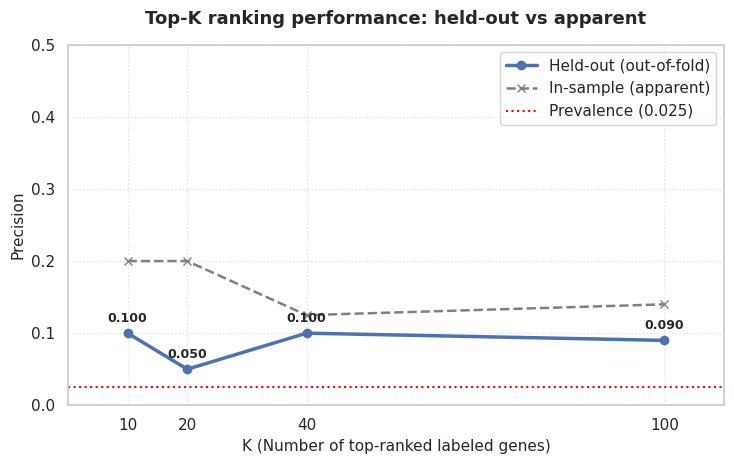

Figure saved to: /content/T2D_v10_ML_Results/figures/Figure_4_topk_heldout_vs_apparent.png
  k  hits  precision
 10     1       0.10
 20     1       0.05
 40     4       0.10
100     9       0.09


In [39]:
#@title Figure 4. Top-K ranking: held-out (headline) vs in-sample (apparent)
ks_plot = [10, 20, 40, 100]
ho = p_at_k_heldout[p_at_k_heldout.k.isin(ks_plot)].sort_values("k")
ap = p_at_k_apparent[p_at_k_apparent.k.isin(ks_plot)].sort_values("k")
if set(ho["k"]) != set(ks_plot) or set(ap["k"]) != set(ks_plot):
    raise ValueError("Some requested K values are missing from the Precision@K tables")

plt.figure(figsize=(7.5, 4.8))
plt.plot(ho["k"], ho["precision"], marker="o", linewidth=2.5, label="Held-out (out-of-fold)")
plt.plot(ap["k"], ap["precision"], marker="x", linewidth=1.8, linestyle="--", color="gray", label="In-sample (apparent)")
plt.axhline(baseline, linestyle=":", color="red", label=f"Prevalence ({baseline:.3f})")
for _, row in ho.iterrows():
    plt.annotate(f"{row['precision']:.3f}", (row["k"], row["precision"]), xytext=(0, 8),
                 textcoords="offset points", ha="center", fontweight="semibold", fontsize=9)
plt.xlim(0, 110); plt.ylim(0, 0.5)
plt.xlabel("K (Number of top-ranked labeled genes)", fontsize=11)
plt.ylabel("Precision", fontsize=11)
plt.title("Top-K ranking performance: held-out vs apparent", fontsize=13, fontweight="bold", pad=15)
plt.xticks(ks_plot); plt.grid(True, linestyle=":", alpha=0.6); plt.legend(loc="upper right")
plt.tight_layout()
fig_path = FIG / "Figure_4_topk_heldout_vs_apparent.png"
plt.savefig(fig_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Figure saved to: {fig_path}")
print(ho[["k","hits","precision"]].to_string(index=False))


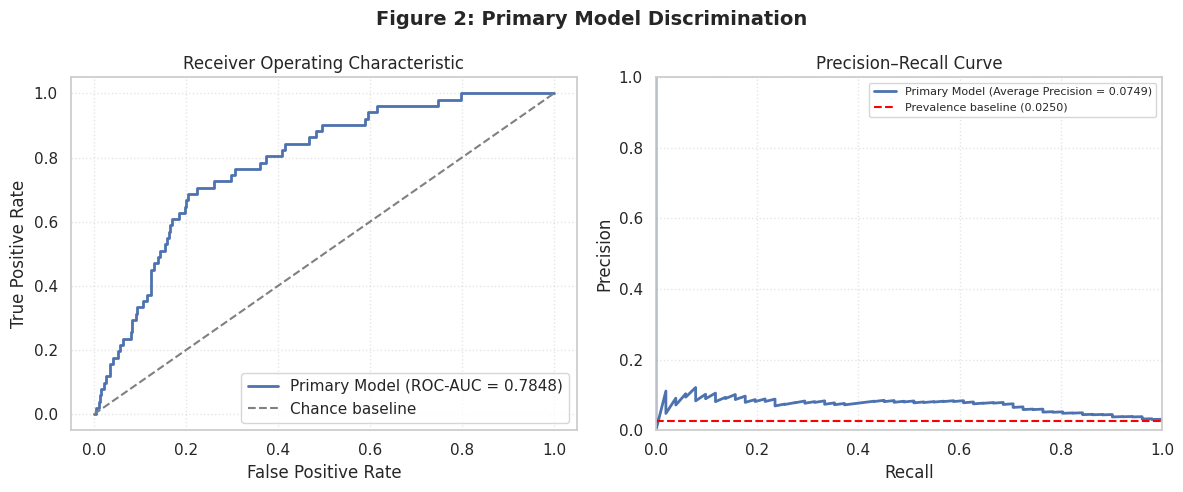

ROC-AUC: 0.784826
Average precision: 0.074881
Positive prevalence: 0.024976
Saved: /content/T2D_v10_ML_Results/figures/Figure_2_primary_model_discrimination.png


In [40]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import (
    roc_curve,
    precision_recall_curve,
    roc_auc_score,
    average_precision_score
)

# Paths
BASE_DIR = OUT
FIG_DIR = BASE_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

OOF_PATH = BASE_DIR / 'tables' / \
    'oof_l2_logistic_regression_primary.csv'

# Load actual out-of-fold predictions
oof_saved = pd.read_csv(OOF_PATH)

required_cols = {'y_true', 'prediction'}
if not required_cols.issubset(oof_saved.columns):
    raise ValueError(f"Expected columns: {required_cols}")

y_true = oof_saved['y_true'].astype(int)
y_score = oof_saved['prediction'].astype(float)

# Calculate metrics from predictions
roc_auc = roc_auc_score(y_true, y_score)
pr_auc = average_precision_score(y_true, y_score)
prevalence = y_true.mean()

fpr, tpr, _ = roc_curve(y_true, y_score)
precision, recall, _ = precision_recall_curve(y_true, y_score)

# Plot
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].plot(
    fpr, tpr, linewidth=2,
    label=f'Primary Model (ROC-AUC = {roc_auc:.4f})'
)
axes[0].plot(
    [0, 1], [0, 1], linestyle='--',
    color='gray', label='Chance baseline'
)
axes[0].set_title('Receiver Operating Characteristic')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(loc='lower right')
axes[0].grid(True, linestyle=':', alpha=0.5)

axes[1].plot(
    recall, precision, linewidth=2,
    label=f'Primary Model (Average Precision = {pr_auc:.4f})'
)
axes[1].axhline(
    prevalence, linestyle='--', color='red',
    label=f'Prevalence baseline ({prevalence:.4f})'
)
axes[1].set_title('Precision–Recall Curve')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precision')
axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1)
axes[1].legend(loc='upper right', fontsize=8)
axes[1].grid(True, linestyle=':', alpha=0.5)

fig.suptitle(
    'Figure 2: Primary Model Discrimination',
    fontsize=14, fontweight='bold'
)
fig.tight_layout()

save_path = FIG_DIR / 'Figure_2_primary_model_discrimination.png'
fig.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'ROC-AUC: {roc_auc:.6f}')
print(f'Average precision: {pr_auc:.6f}')
print(f'Positive prevalence: {prevalence:.6f}')
print(f'Saved: {save_path}')

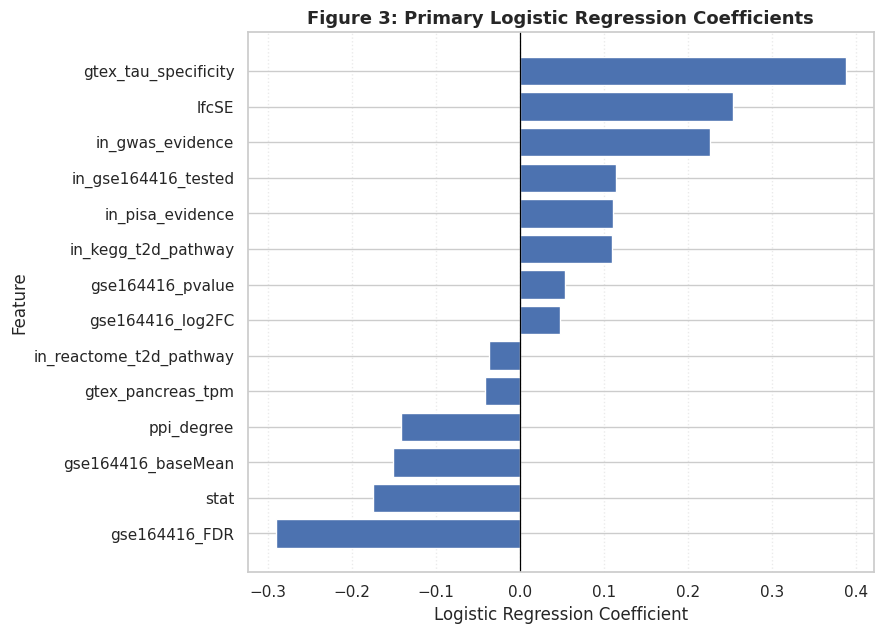

Saved: /content/T2D_v10_ML_Results/figures/Figure_3_logistic_regression_coefficients.png
                feature  coefficient
          gse164416_FDR    -0.289886
                   stat    -0.174451
     gse164416_baseMean    -0.150327
             ppi_degree    -0.141303
      gtex_pancreas_tpm    -0.041360
in_reactome_t2d_pathway    -0.037124
       gse164416_log2FC     0.047409
       gse164416_pvalue     0.053868
    in_kegg_t2d_pathway     0.109552
       in_pisa_evidence     0.110493
    in_gse164416_tested     0.113786
       in_gwas_evidence     0.225626
                  lfcSE     0.252946
   gtex_tau_specificity     0.387297


In [41]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Paths (aligned to workspace results directory)
BASE_DIR = OUT
FIG_DIR = BASE_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

COEF_PATH = BASE_DIR / 'tables' / 'locked_lr_coefficients.csv'

# Load coefficients from the fitted primary model
coef_df = pd.read_csv(COEF_PATH)

required_cols = {'feature', 'coefficient'}
if not required_cols.issubset(coef_df.columns):
    raise ValueError(f"Expected columns: {required_cols}")

coef_df = coef_df.dropna(subset=['feature', 'coefficient']).copy()
coef_df = coef_df.sort_values('coefficient')

# Plot signed logistic-regression coefficients
fig, ax = plt.subplots(figsize=(9, 6.5))

ax.barh(
    coef_df['feature'],
    coef_df['coefficient']
)
ax.axvline(0, color='black', linewidth=0.9)

ax.set_title(
    'Figure 3: Primary Logistic Regression Coefficients',
    fontsize=13, fontweight='bold'
)
ax.set_xlabel('Logistic Regression Coefficient')
ax.set_ylabel('Feature')
ax.grid(axis='x', linestyle=':', alpha=0.4)

fig.tight_layout()

save_path = FIG_DIR / 'Figure_3_logistic_regression_coefficients.png'
fig.savefig(save_path, dpi=300, bbox_inches='tight')
plt.show()

print(f'Saved: {save_path}')
print(coef_df[['feature', 'coefficient']].to_string(index=False))

# 36. Additional analyses

its folds, or any number produced above. These cells address reviewer-facing gaps:

1. Label reproduction and universe audit (what "unlabeled" means; identifier problems)
2. Held-out Precision@K (computed from out-of-fold predictions, not from the final fitted model)
3. Ten-seed repeated grouped CV and a paired comparison of the primary model vs the best secondary model
4. Feature-set ablation and single-feature baselines (how much signal comes from GSE164416-derived predictors)
5. Label-definition sensitivity (positives with a fold-change requirement)
6. Candidate gene table including unlabeled genes
7. Additional-analyses workbook
8. Candidate lists restricted to well-observed genes (36H) and the expression/detectability confound diagnostic (36I)

The packaging cell at the very end of the notebook runs last so that every output (including 36H and 36I) is in the download.


In [42]:
#@title 36A. Label reproduction audit, universe description and identifier audit
# Descriptive audit only. GSE221156 columns are read here to RE-DERIVE the labels and to describe the
# analysis universe; they are never used as predictors.

ADDL = {}   # tables collected for the additional-analyses workbook

status = pd.Series(
    np.where(y_raw == 1, "positive", np.where(y_raw == 0, "strict_control", "unlabeled")),
    index=df.index, name="label_status"
)

raw_cols_ok = {"gse221156_beta_FDR", "gse221156_beta_log2FC"} <= set(df.columns)
FC_THR = np.log2(1.2)

if raw_cols_ok:
    fdr221 = pd.to_numeric(df["gse221156_beta_FDR"], errors="coerce")
    lfc221 = pd.to_numeric(df["gse221156_beta_log2FC"], errors="coerce")

    recon = pd.Series(np.nan, index=df.index)
    recon[fdr221 < 0.05] = 1
    recon[(fdr221 >= 0.05) & (lfc221.abs() < FC_THR)] = 0

    mismatch = recon.fillna(-1) != y_raw.fillna(-1)
    print(f"Label re-derivation from raw GSE221156 FDR / log2FC: {int(mismatch.sum())} mismatching genes "
          f"out of {len(df)}")
    if mismatch.sum() > 0:
        print("WARNING: stored `label` column does not exactly match the rule in the manuscript.")
        display(df.loc[mismatch, ["gene_symbol"]].assign(
            stored_label=y_raw[mismatch], rederived=recon[mismatch],
            fdr=fdr221[mismatch], log2fc=lfc221[mismatch]).head(30))

    pos_abs_lfc = lfc221[status == "positive"].abs()
    pos_summary = pd.DataFrame([{
        "n_positive": int(len(pos_abs_lfc)),
        "n_positive_abs_log2FC_below_log2(1.2)": int((pos_abs_lfc < FC_THR).sum()),
        "frac_positive_below_threshold": float((pos_abs_lfc < FC_THR).mean()),
        "median_abs_log2FC_positive": float(pos_abs_lfc.median()),
        "min_abs_log2FC_positive": float(pos_abs_lfc.min()),
        "max_abs_log2FC_positive": float(pos_abs_lfc.max()),
    }])
    print("\nPositives: effect-size summary (FDR<0.05 only, no fold-change requirement)")
    display(pos_summary.T)
    ADDL["Label_audit_positives"] = pos_summary

    unl = status == "unlabeled"
    unl_breakdown = pd.DataFrame([
        {"unlabeled_subtype": "not tested in GSE221156 (FDR missing)", "n": int((unl & fdr221.isna()).sum())},
        {"unlabeled_subtype": "FDR>=0.05 but |log2FC|>=log2(1.2)", "n": int((unl & (fdr221 >= 0.05) & (lfc221.abs() >= FC_THR)).sum())},
        {"unlabeled_subtype": "other", "n": int((unl & ~fdr221.isna() & ~((fdr221 >= 0.05) & (lfc221.abs() >= FC_THR))).sum())},
    ])
    print("\nWhat 'unlabeled' means in this dataset:")
    display(unl_breakdown)
    ADDL["Label_audit_unlabeled"] = unl_breakdown
else:
    print("Raw GSE221156 FDR/log2FC columns not found; label re-derivation skipped.")

# Universe description by label status: missingness and prevalence of binary evidence flags
rows = []
for s_name in ["positive", "strict_control", "unlabeled"]:
    sub = df.loc[status == s_name]
    r = {"label_status": s_name, "n_genes": len(sub)}
    for f in PRIMARY_FEATURES:
        v = pd.to_numeric(sub[f], errors="coerce")
        r[f"missing__{f}"] = float(v.isna().mean())
        if f.startswith("in_"):
            r[f"mean__{f}"] = float(v.mean())
    rows.append(r)
universe_desc = pd.DataFrame(rows).set_index("label_status").T
print("\nUniverse description by label status (missing__ = fraction missing; mean__ = prevalence of flag):")
display(universe_desc)
ADDL["Universe_by_label_status"] = universe_desc.reset_index().rename(columns={"index": "quantity"})

# Identifier audit
sym = df["gene_symbol"].astype(str)
is_ensg = sym.str.upper().str.startswith("ENSG")
id_audit = pd.DataFrame([
    {"item": "genes with ENSG-prefixed value in gene_symbol", "n": int(is_ensg.sum())},
    {"item": "  ... among labeled genes", "n": int((is_ensg & (status != "unlabeled")).sum())},
    {"item": "  ... among unlabeled genes", "n": int((is_ensg & (status == "unlabeled")).sum())},
    {"item": "duplicated gene_symbol values", "n": int(sym.duplicated(keep=False).sum())},
    {"item": "non-missing PISA_gene_id", "n": int(df["PISA_gene_id"].notna().sum()) if "PISA_gene_id" in df.columns else -1},
])
print("\nIdentifier audit:")
display(id_audit)
ADDL["Identifier_audit"] = id_audit
if "Ensembl_mapping_status" in df.columns:
    ms = df["Ensembl_mapping_status"].value_counts(dropna=False).rename_axis("Ensembl_mapping_status").reset_index(name="n")
    display(ms)
    ADDL["Ensembl_mapping_status"] = ms
    print("(Ensembl_mapping_status is a legacy column that predates the HGNC / Ensembl mapping of cell 4B; kept for traceability.)")


# Authoritative identifier mapping (columns added in cell 4B)
ADDL["Identifier_mapping"] = pd.DataFrame([ID_MAPPING_INFO["counts"]])
ADDL["Identifier_mapping_methods"] = df["id_mapping_method"].value_counts(dropna=False).rename_axis("id_mapping_method").reset_index(name="n")
print("\nIdentifier mapping (HGNC / Ensembl GRCh38; cell 4B):")
display(ADDL["Identifier_mapping"])
display(ADDL["Identifier_mapping_methods"])


Label re-derivation from raw GSE221156 FDR / log2FC: 0 mismatching genes out of 3868

Positives: effect-size summary (FDR<0.05 only, no fold-change requirement)


,0
n_positive,51.000000
n_positive_abs_log2FC_below_log2(1.2),1.000000
frac_positive_below_threshold,0.019608
median_abs_log2FC_positive,0.925683
min_abs_log2FC_positive,0.193981
max_abs_log2FC_positive,2.700568



What 'unlabeled' means in this dataset:


,unlabeled_subtype,n
0,not tested in GSE221156 (FDR missing),1112
1,FDR>=0.05 but |log2FC|>=log2(1.2),714
2,other,0



Universe description by label status (missing__ = fraction missing; mean__ = prevalence of flag):


...

,item,n
0,genes with ENSG-prefixed value in gene_symbol,823
1,... among labeled genes,0
2,... among unlabeled genes,823
3,duplicated gene_symbol values,0
4,non-missing PISA_gene_id,3


,Ensembl_mapping_status,n
0,unmapped_in_available_local_master,3865
1,validated_local_master_mapping,3


(Ensembl_mapping_status is a legacy column that predates the HGNC / Ensembl mapping of cell 4B; kept for traceability.)

Identifier mapping (HGNC / Ensembl GRCh38; cell 4B):


,n_genes,n_hgnc,n_ensembl,n_no_hgnc_symbol,n_ensg_symbol_resolved_to_hgnc,n_duplicate_rows_excluded
0,3868,3339,3745,529,419,14


,id_mapping_method,n
0,approved_symbol,2872
1,ensembl_id_to_hgnc,419
2,ensembl_only,355
3,unmapped,123
4,ensembl_id_not_in_grch38_release,49
5,previous_symbol,46
6,alias_symbol,2
7,ensembl_gene_name,2


Precision@K by score source (held-out rows are the ones to report):


k,10,20,40,100
scores,,,,
L2 LR - single grouped split (seed 20260910),0.1,0.05,0.100,0.09
L2 LR - mean of 5 repeated grouped splits,0.1,0.05,0.050,0.08
Gradient Boosting - single grouped split (seed 20260910),0.5,0.40,0.250,0.18
Gradient Boosting - mean of 5 repeated grouped splits,0.2,0.20,0.250,0.16
"L2 LR - final model fitted on all labeled genes (APPARENT, in-sample)",0.2,0.20,0.125,0.14



Hits among top-K (held-out, single grouped split):


,scores,k,hits,precision,enrichment,boot_ci_low,boot_ci_high
0,L2 LR - single grouped split (seed 20260910),10,1,0.100,4.003922,0.000,0.30000
1,L2 LR - single grouped split (seed 20260910),20,1,0.050,2.001961,0.000,0.20000
2,L2 LR - single grouped split (seed 20260910),40,4,0.100,4.003922,0.025,0.20000
3,L2 LR - single grouped split (seed 20260910),50,5,0.100,4.003922,0.020,0.18000
4,L2 LR - single grouped split (seed 20260910),100,9,0.090,3.603529,0.040,0.15000
5,L2 LR - single grouped split (seed 20260910),200,16,0.080,3.203137,0.045,0.12000
6,L2 LR - single grouped split (seed 20260910),500,36,0.072,2.882824,0.050,0.09605
14,Gradient Boosting - single grouped split (seed...,10,5,0.500,20.019608,0.200,0.80000
15,Gradient Boosting - single grouped split (seed...,20,8,0.400,16.015686,0.150,0.60000
16,Gradient Boosting - single grouped split (seed...,40,10,0.250,10.009804,0.125,0.42500


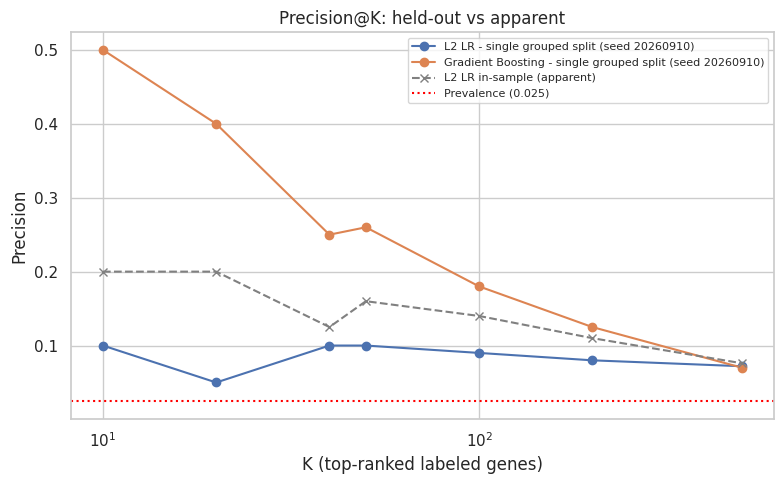

In [43]:
#@title 36B. Held-out Precision@K (out-of-fold) with bootstrap CIs
# Precision@K computed from HELD-OUT predictions only. These replace the in-sample (apparent) values
# produced in cell 28 as the apparent (comparison-only) values. Cell 28 now also reports the held-out single-split
# table; this cell adds bootstrap CIs and the repeated-split versions.

KS = [10, 20, 40, 50, 100, 200, 500]

def prec_at_k(y_true, score, k):
    y_true = np.asarray(y_true); score = np.asarray(score, float)
    order = np.argsort(-score, kind="mergesort")
    k = min(k, len(y_true))
    return float(y_true[order[:k]].sum()), k

def pk_table(name, y_true, score, n_boot=2000, seed=SEED):
    y_arr = np.asarray(y_true); s_arr = np.asarray(score, float)
    n = len(y_arr); prev = y_arr.mean()
    rng = np.random.default_rng(seed)
    cums = np.empty((n_boot, n))
    for b in range(n_boot):
        idx = rng.integers(0, n, n)
        order = np.argsort(-s_arr[idx], kind="mergesort")
        cums[b] = np.cumsum(y_arr[idx][order])
    rows = []
    for k in KS:
        hits, kk = prec_at_k(y_arr, s_arr, k)
        boot = cums[:, kk - 1] / kk
        rows.append({
            "scores": name, "k": k, "hits": int(hits), "precision": hits / kk,
            "baseline_prevalence": prev, "enrichment": (hits / kk) / prev,
            "recall_at_k": hits / y_arr.sum(),
            "boot_ci_low": float(np.quantile(boot, .025)), "boot_ci_high": float(np.quantile(boot, .975)),
            "basis": "held-out (out-of-fold)",
        })
    return pd.DataFrame(rows)

heldout_scores = {
    "L2 LR - single grouped split (seed 20260910)": oof,
    "L2 LR - mean of 5 repeated grouped splits": lr_rep_oof,
    f"{secondary_name} - single grouped split (seed 20260910)": benchmark_oof[secondary_name],
    f"{secondary_name} - mean of 5 repeated grouped splits": sec_rep_oof,
}
pk_heldout = pd.concat([pk_table(n, y.to_numpy(), s) for n, s in heldout_scores.items()], ignore_index=True)

# In-sample (apparent) values come from cell 28 (kept in memory; also saved as precision_at_k_apparent_insample.csv).
pk_insample = p_at_k_apparent.rename(columns={"baseline": "baseline_prevalence"}).copy()

pk_all = pd.concat([pk_heldout, pk_insample], ignore_index=True, sort=False)
pk_all.to_csv(TAB / "precision_at_k_heldout_and_insample.csv", index=False)
ADDL["PrecisionAtK_heldout"] = pk_all

show = pk_all[pk_all.k.isin([10, 20, 40, 100])].pivot_table(
    index="scores", columns="k", values="precision", sort=False)
print("Precision@K by score source (held-out rows are the ones to report):")
display(show.round(3))
print("\nHits among top-K (held-out, single grouped split):")
display(pk_heldout[pk_heldout.scores.str.contains("single")][["scores", "k", "hits", "precision", "enrichment", "boot_ci_low", "boot_ci_high"]])

# Figure: held-out vs apparent Precision@K
plt.figure(figsize=(8, 5))
for nm, g in pk_heldout[pk_heldout.scores.str.contains("single")].groupby("scores", sort=False):
    plt.plot(g.k, g.precision, marker="o", label=nm)
plt.plot(pk_insample.k, pk_insample.precision, marker="x", ls="--", color="gray", label="L2 LR in-sample (apparent)")
plt.axhline(y.mean(), ls=":", color="red", label=f"Prevalence ({y.mean():.3f})")
plt.xscale("log"); plt.xlabel("K (top-ranked labeled genes)"); plt.ylabel("Precision")
plt.title("Precision@K: held-out vs apparent"); plt.legend(fontsize=8)
savefig("16_precision_at_k_heldout")


In [44]:
#@title 36C. Ten-seed repeated grouped CV and paired comparison (primary vs best secondary)
SEEDS10 = (11, 22, 33, 44, 55, 66, 77, 88, 99, 110)

def repeated_summary(factory, cols, seeds=SEEDS10):
    """Repeated grouped 5-fold CV on the labeled genes using only `cols`. Returns per-seed metrics and mean OOF."""
    rows, oof_sum = [], np.zeros(len(y))
    Xc = X[cols]
    for sd in seeds:
        cvx = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=sd)
        ps = np.full(len(y), np.nan); fold_pr, fold_roc = [], []
        for tr, te in cvx.split(Xc, y, groups):
            m = factory(); m.fit(Xc.iloc[tr], y.iloc[tr])
            ps[te] = m.predict_proba(Xc.iloc[te])[:, 1]
            fold_pr.append(average_precision_score(y.iloc[te], ps[te]))
            fold_roc.append(roc_auc_score(y.iloc[te], ps[te]))
        oof_sum += ps
        r = evaluate_binary(y, ps)
        r.update(seed=sd, mean_fold_roc=float(np.mean(fold_roc)), mean_fold_pr=float(np.mean(fold_pr)),
                 p_at_20=prec_at_k(y.to_numpy(), ps, 20)[0] / 20, p_at_100=prec_at_k(y.to_numpy(), ps, 100)[0] / 100)
        rows.append(r)
    return pd.DataFrame(rows), oof_sum / len(seeds)

FACTORIES = {"L2 LR (primary)": lambda: make_lr(PRIMARY_C), secondary_name: secondary_factory}

rep10, rep10_oof = {}, {}
for nm, fac in FACTORIES.items():
    print("Running 10 seeds:", nm)
    rep10[nm], rep10_oof[nm] = repeated_summary(fac, PRIMARY_FEATURES)

def summ(df_, nm):
    return {"model": nm, "n_seeds": len(df_),
            "roc_auc_mean": df_.roc_auc.mean(), "roc_auc_sd": df_.roc_auc.std(ddof=1),
            "pr_auc_mean": df_.pr_auc.mean(), "pr_auc_sd": df_.pr_auc.std(ddof=1),
            "pr_auc_min": df_.pr_auc.min(), "pr_auc_max": df_.pr_auc.max(),
            "fold_mean_pr_mean": df_.mean_fold_pr.mean(),
            "heldout_p_at_20_mean": df_.p_at_20.mean(), "heldout_p_at_100_mean": df_.p_at_100.mean()}

rep10_summary = pd.DataFrame([summ(d, n) for n, d in rep10.items()])
print("\nTen-seed repeated grouped CV (all 14 predictors):")
display(rep10_summary.round(4))
ADDL["Repeated10_summary"] = rep10_summary
ADDL["Repeated10_per_seed"] = pd.concat([d.assign(model=n) for n, d in rep10.items()], ignore_index=True)

# Paired bootstrap: secondary minus primary, on the 10-seed-averaged held-out predictions
def paired_boot(p_a, p_b, metric, n_boot=2000, seed=SEED):
    rng = np.random.default_rng(seed); yy = y.to_numpy(); n = len(yy); d = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        if len(np.unique(yy[idx])) < 2: continue
        d.append(metric(yy[idx], p_a[idx]) - metric(yy[idx], p_b[idx]))
    d = np.asarray(d)
    return {"mean_diff": float(d.mean()), "ci_low": float(np.quantile(d, .025)),
            "ci_high": float(np.quantile(d, .975)), "frac_diff_le_0": float((d <= 0).mean())}

pb = pd.DataFrame([
    {"comparison": f"{secondary_name} minus L2 LR", "metric": "PR-AUC",
     **paired_boot(rep10_oof[secondary_name], rep10_oof["L2 LR (primary)"], average_precision_score)},
    {"comparison": f"{secondary_name} minus L2 LR", "metric": "ROC-AUC",
     **paired_boot(rep10_oof[secondary_name], rep10_oof["L2 LR (primary)"], roc_auc_score)},
])
print("\nPaired bootstrap of the difference (genes resampled; 10-seed-averaged held-out predictions):")
display(pb.round(4))
ADDL["Paired_bootstrap_diff"] = pb

# Bootstrap CIs for the secondary model's pooled OOF metrics (single grouped split) for Table 3
sec_p = benchmark_oof[secondary_name]
sec_roc_ci = bootstrap_metric_ci(y.to_numpy(), sec_p, roc_auc_score, 5000)
sec_pr_ci = bootstrap_metric_ci(y.to_numpy(), sec_p, average_precision_score, 5000)
sec_ci = pd.DataFrame([
    {"model": secondary_name, "metric": "ROC-AUC", "estimate": roc_auc_score(y, sec_p), "ci_low": sec_roc_ci[0], "ci_high": sec_roc_ci[1]},
    {"model": secondary_name, "metric": "PR-AUC", "estimate": average_precision_score(y, sec_p), "ci_low": sec_pr_ci[0], "ci_high": sec_pr_ci[1]},
])
display(sec_ci.round(4))
ADDL["Secondary_bootstrap_CI"] = sec_ci


Running 10 seeds: L2 LR (primary)
Running 10 seeds: Gradient Boosting

Ten-seed repeated grouped CV (all 14 predictors):


,model,n_seeds,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,pr_auc_min,pr_auc_max,fold_mean_pr_mean,heldout_p_at_20_mean,heldout_p_at_100_mean
0,L2 LR (primary),10,0.7714,0.0167,0.0722,0.0084,0.0593,0.0867,0.1041,0.05,0.081
1,Gradient Boosting,10,0.7732,0.0194,0.1265,0.0170,0.0966,0.1572,0.1820,0.23,0.166



Paired bootstrap of the difference (genes resampled; 10-seed-averaged held-out predictions):


,comparison,metric,mean_diff,ci_low,ci_high,frac_diff_le_0
0,Gradient Boosting minus L2 LR,PR-AUC,0.0678,0.0128,0.1436,0.0055
1,Gradient Boosting minus L2 LR,ROC-AUC,0.0030,-0.0410,0.0495,0.4520


,model,metric,estimate,ci_low,ci_high
0,Gradient Boosting,ROC-AUC,0.8001,0.7326,0.8628
1,Gradient Boosting,PR-AUC,0.1835,0.1034,0.3124


In [45]:
#@title 36C-2. Table 3 inputs: primary vs best secondary — single split AND 10-seed results
mc_idx = model_comparison.set_index("model")
r10_idx = rep10_summary.set_index("model")
t3_rows = []
for full_name, short_name in [("L2 Logistic Regression (primary)", "L2 LR (primary)"), (secondary_name, secondary_name)]:
    t3_rows.append({
        "model": full_name,
        "roc_auc_single_split": float(mc_idx.loc[full_name, "roc_auc"]),
        "pr_auc_single_split": float(mc_idx.loc[full_name, "pr_auc"]),
        "roc_auc_10seed_mean": float(r10_idx.loc[short_name, "roc_auc_mean"]),
        "roc_auc_10seed_sd": float(r10_idx.loc[short_name, "roc_auc_sd"]),
        "pr_auc_10seed_mean": float(r10_idx.loc[short_name, "pr_auc_mean"]),
        "pr_auc_10seed_sd": float(r10_idx.loc[short_name, "pr_auc_sd"]),
        "reporting_note": "Headline = 10-seed mean +/- SD. The single split (seed %d) is one draw and, for the secondary model, was also the split used to pick it." % SEED,
    })
table3_seeds = pd.DataFrame(t3_rows)
display(table3_seeds.round(4))
table3_seeds.to_csv(TAB / "table3_benchmark_single_split_and_10seed.csv", index=False)
ADDL["Table3_single_vs_10seed"] = table3_seeds

,model,roc_auc_single_split,pr_auc_single_split,roc_auc_10seed_mean,roc_auc_10seed_sd,pr_auc_10seed_mean,pr_auc_10seed_sd,reporting_note
0,L2 Logistic Regression (primary),0.7848,0.0749,0.7714,0.0167,0.0722,0.0084,Headline = 10-seed mean +/- SD. The single spl...
1,Gradient Boosting,0.8001,0.1835,0.7732,0.0194,0.1265,0.0170,Headline = 10-seed mean +/- SD. The single spl...


done: All 14 predictors (primary) | L2 LR (primary)
done: All 14 predictors (primary) | Gradient Boosting
done: No GSE164416-derived predictors (7) | L2 LR (primary)
done: No GSE164416-derived predictors (7) | Gradient Boosting
done: GSE164416-derived predictors only (7) | L2 LR (primary)
done: GSE164416-derived predictors only (7) | Gradient Boosting
done: All 14 minus lfcSE and stat | L2 LR (primary)
done: All 14 minus lfcSE and stat | Gradient Boosting
done: Genetic evidence only (GWAS, PISA) | L2 LR (primary)
done: Genetic evidence only (GWAS, PISA) | Gradient Boosting
done: Expression context only (GTEx TPM, tau) | L2 LR (primary)
done: Expression context only (GTEx TPM, tau) | Gradient Boosting
done: Network + pathway only (PPI, KEGG, Reactome) | L2 LR (primary)
done: Network + pathway only (PPI, KEGG, Reactome) | Gradient Boosting

Ablation (mean over 5 grouped-CV seeds; prevalence baseline PR-AUC = 0.0250):


,feature_set,n_features,model,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,heldout_p_at_20,heldout_p_at_100
0,All 14 predictors (primary),14,L2 LR (primary),0.7723,0.0171,0.0699,0.0066,0.04,0.080
1,All 14 predictors (primary),14,Gradient Boosting,0.7662,0.0247,0.1181,0.0152,0.21,0.154
2,No GSE164416-derived predictors (7),7,L2 LR (primary),0.7352,0.0206,0.0513,0.0060,0.01,0.048
3,No GSE164416-derived predictors (7),7,Gradient Boosting,0.7154,0.0247,0.0575,0.0089,0.02,0.070
4,GSE164416-derived predictors only (7),7,L2 LR (primary),0.7216,0.0110,0.0689,0.0019,0.06,0.092
5,GSE164416-derived predictors only (7),7,Gradient Boosting,0.7102,0.0292,0.0859,0.0155,0.19,0.106
6,All 14 minus lfcSE and stat,12,L2 LR (primary),0.7354,0.0201,0.0550,0.0040,0.06,0.050
7,All 14 minus lfcSE and stat,12,Gradient Boosting,0.7690,0.0187,0.1256,0.0074,0.25,0.164
8,"Genetic evidence only (GWAS, PISA)",2,L2 LR (primary),0.4692,0.0452,0.0269,0.0031,0.02,0.040
9,"Genetic evidence only (GWAS, PISA)",2,Gradient Boosting,0.4563,0.0531,0.0267,0.0034,0.01,0.044



Single-feature baselines (L2 LR, one predictor at a time):


,feature,is_GSE164416_derived,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd
0,lfcSE,True,0.7493,0.0195,0.0677,0.0040
1,gtex_tau_specificity,False,0.7418,0.0124,0.0493,0.0031
2,gse164416_FDR,True,0.5580,0.0263,0.0372,0.0114
3,gse164416_baseMean,True,0.5470,0.0555,0.0307,0.0066
4,gse164416_log2FC,True,0.5115,0.0216,0.0660,0.0120
5,gse164416_pvalue,True,0.5092,0.0382,0.0370,0.0157
6,in_gwas_evidence,False,0.4779,0.0313,0.0252,0.0009
7,gtex_pancreas_tpm,False,0.4584,0.0409,0.0301,0.0096
8,ppi_degree,False,0.4522,0.0419,0.0227,0.0021
9,stat,True,0.4510,0.0524,0.0315,0.0099


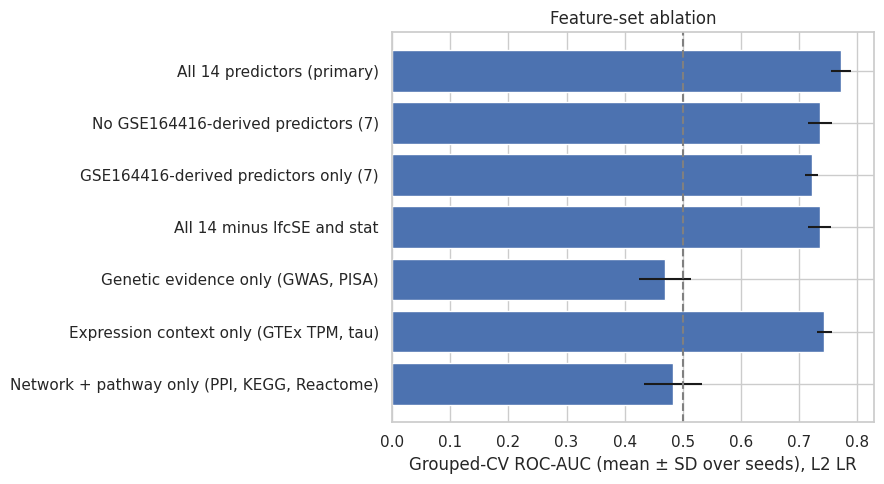

In [46]:
#@title 36D. Feature-set ablation and single-feature baselines (grouped CV, 5 seeds)
SEEDS5 = SEEDS10[:5]

GSE164416_FEATS = ["in_gse164416_tested", "gse164416_baseMean", "gse164416_log2FC", "lfcSE", "stat",
                   "gse164416_pvalue", "gse164416_FDR"]
NON_164416 = [f for f in PRIMARY_FEATURES if f not in GSE164416_FEATS]

FEATURE_SETS = {
    "All 14 predictors (primary)": PRIMARY_FEATURES,
    "No GSE164416-derived predictors (7)": NON_164416,
    "GSE164416-derived predictors only (7)": GSE164416_FEATS,
    "All 14 minus lfcSE and stat": [f for f in PRIMARY_FEATURES if f not in ("lfcSE", "stat")],
    "Genetic evidence only (GWAS, PISA)": ["in_gwas_evidence", "in_pisa_evidence"],
    "Expression context only (GTEx TPM, tau)": ["gtex_pancreas_tpm", "gtex_tau_specificity"],
    "Network + pathway only (PPI, KEGG, Reactome)": ["ppi_degree", "in_kegg_t2d_pathway", "in_reactome_t2d_pathway"],
}

abl_rows = []
for set_name, cols in FEATURE_SETS.items():
    for mname, fac in FACTORIES.items():
        d_, _ = repeated_summary(fac, cols, seeds=SEEDS5)
        abl_rows.append({"feature_set": set_name, "n_features": len(cols), "model": mname,
                         "roc_auc_mean": d_.roc_auc.mean(), "roc_auc_sd": d_.roc_auc.std(ddof=1),
                         "pr_auc_mean": d_.pr_auc.mean(), "pr_auc_sd": d_.pr_auc.std(ddof=1),
                         "heldout_p_at_20": d_.p_at_20.mean(), "heldout_p_at_100": d_.p_at_100.mean()})
        print(f"done: {set_name} | {mname}")
ablation = pd.DataFrame(abl_rows)
print(f"\nAblation (mean over {len(SEEDS5)} grouped-CV seeds; prevalence baseline PR-AUC = {y.mean():.4f}):")
display(ablation.round(4))
ADDL["Ablation_feature_sets"] = ablation

# Single-feature baselines (L2 LR on one predictor)
single_rows = []
for f in PRIMARY_FEATURES:
    d_, _ = repeated_summary(lambda: make_lr(PRIMARY_C), [f], seeds=SEEDS5)
    single_rows.append({"feature": f, "is_GSE164416_derived": f in GSE164416_FEATS,
                        "roc_auc_mean": d_.roc_auc.mean(), "roc_auc_sd": d_.roc_auc.std(ddof=1),
                        "pr_auc_mean": d_.pr_auc.mean(), "pr_auc_sd": d_.pr_auc.std(ddof=1)})
single_feat = pd.DataFrame(single_rows).sort_values("roc_auc_mean", ascending=False).reset_index(drop=True)
print("\nSingle-feature baselines (L2 LR, one predictor at a time):")
display(single_feat.round(4))
ADDL["Single_feature_baselines"] = single_feat

# Figure
fig, ax = plt.subplots(figsize=(9, 5))
plot_ab = ablation[ablation.model == "L2 LR (primary)"].iloc[::-1]
ax.barh(plot_ab.feature_set, plot_ab.roc_auc_mean, xerr=plot_ab.roc_auc_sd)
ax.axvline(0.5, ls="--", color="gray")
ax.set_xlabel("Grouped-CV ROC-AUC (mean ± SD over seeds), L2 LR"); ax.set_title("Feature-set ablation")
savefig("17_feature_set_ablation")


In [47]:
#@title 36E. Label-definition sensitivity (positives that also require a fold-change)
# Primary labels: positive = FDR<0.05 (no fold-change rule); control = FDR>=0.05 & |log2FC|<log2(1.2).
# Sensitivity: positives must ALSO satisfy |log2FC| >= threshold. Positives failing the rule are EXCLUDED
# (not recoded as controls). Same predictors, same fixed C, same grouped CV procedure.

sens_rows = []
if raw_cols_ok:
    lfc_lab = lfc221.loc[X.index].abs()
    for thr_name, thr in [("|log2FC| >= log2(1.2)", np.log2(1.2)), ("|log2FC| >= log2(1.5)", np.log2(1.5))]:
        drop = (y == 1) & (lfc_lab < thr)
        keep = ~drop.to_numpy()
        Xs, ys, gs = X.loc[keep], y.loc[keep], groups[keep]
        for mname, fac in FACTORIES.items():
            rr = []
            for sd in SEEDS5:
                cvx = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=sd)
                ps = np.full(len(ys), np.nan)
                for tr, te in cvx.split(Xs, ys, gs):
                    m = fac(); m.fit(Xs.iloc[tr], ys.iloc[tr]); ps[te] = m.predict_proba(Xs.iloc[te])[:, 1]
                rr.append((roc_auc_score(ys, ps), average_precision_score(ys, ps)))
            rr = np.array(rr)
            sens_rows.append({"positive_definition": f"FDR<0.05 and {thr_name}", "model": mname,
                              "n_positive": int(ys.sum()), "n_control": int((ys == 0).sum()),
                              "prevalence": float(ys.mean()),
                              "roc_auc_mean": rr[:, 0].mean(), "roc_auc_sd": rr[:, 0].std(ddof=1),
                              "pr_auc_mean": rr[:, 1].mean(), "pr_auc_sd": rr[:, 1].std(ddof=1)})
    label_sens = pd.DataFrame(sens_rows)
    print("Label-definition sensitivity (reference: primary definition, 51 positives):")
    display(label_sens.round(4))
    ADDL["Label_sensitivity"] = label_sens
else:
    print("Raw GSE221156 columns not found; sensitivity analysis skipped.")


Label-definition sensitivity (reference: primary definition, 51 positives):


,positive_definition,model,n_positive,n_control,prevalence,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd
0,FDR<0.05 and |log2FC| >= log2(1.2),L2 LR (primary),50,1991,0.0245,0.7661,0.0147,0.0696,0.0071
1,FDR<0.05 and |log2FC| >= log2(1.2),Gradient Boosting,50,1991,0.0245,0.7764,0.0136,0.1272,0.0172
2,FDR<0.05 and |log2FC| >= log2(1.5),L2 LR (primary),42,1991,0.0207,0.7889,0.0161,0.0713,0.0072
3,FDR<0.05 and |log2FC| >= log2(1.5),Gradient Boosting,42,1991,0.0207,0.7979,0.0151,0.1202,0.0193


In [48]:
#@title 36F. Candidate gene tables (including unlabeled genes)
cand = df_scores.copy()
cand["label_status"] = status
cand["no_hgnc_symbol"] = cand["hgnc_symbol"].isna()
cand["duplicate_excluded"] = cand["duplicate_resolution"].eq("exclude_duplicate_row")
cand["primary_LR_score_heldout"] = np.nan
cand.loc[X.index, "primary_LR_score_heldout"] = rep10_oof["L2 LR (primary)"]       # labeled genes only
cand["note_labeled_scores"] = np.where(status != "unlabeled",
                                       "IN-SAMPLE: gene was used to fit the final model; compare genes with primary_LR_score_heldout instead", "out-of-sample: gene was not used in model fitting")

# Literature annotation (limited, hand-compiled literature check, not a systematic T2D Knowledge Portal query).
# Read from sheet LITERATURE_ANNOTATION of the dataset workbook; a separate literature_annotation.csv in BASE or
# BASE/reference is still accepted as a fallback.
_lit = None
if "LITERATURE_ANNOTATION" in pd.ExcelFile(XLSX).sheet_names:
    _lit = pd.read_excel(XLSX, sheet_name="LITERATURE_ANNOTATION")
    print("Literature annotation read from sheet LITERATURE_ANNOTATION of", XLSX.name)
else:
    LIT_FILE = next((p for p in (BASE / "literature_annotation.csv", BASE / "reference" / "literature_annotation.csv") if p.exists()), None)
    if LIT_FILE is not None:
        _lit = pd.read_csv(LIT_FILE)
        print("Literature annotation read from", LIT_FILE)
if _lit is not None:
    _lit = _lit.drop_duplicates("gene_label_clean").set_index("gene_label_clean")["known_T2D_or_beta_cell_link"]
    cand["known_T2D_or_beta_cell_link"] = cand["gene_label_clean"].map(_lit).fillna("—")
else:
    cand["known_T2D_or_beta_cell_link"] = "—"
    print("No literature annotation found (sheet or CSV); the annotation column is left blank (—).")

id_cols = [c for c in ["gene_label_clean", "gene_symbol", "hgnc_id", "ensembl_gene_id_grch38", "gene_biotype", "PISA_gene_id"] if c in cand.columns]
show_cols = id_cols + ["label_status", "no_hgnc_symbol", "primary_LR_score", "primary_LR_rank",
                       "primary_LR_score_heldout", "secondary_model_score", "secondary_model_rank",
                       "note_labeled_scores", "known_T2D_or_beta_cell_link"]

# Redundant rows (the same gene recorded under an old and a current symbol) are removed from the candidate lists only.
print(f"Redundant duplicate-gene rows excluded from candidate lists: {int(cand.duplicate_excluded.sum())}")
cand_nd = cand[~cand["duplicate_excluded"]]

top30_all = cand_nd.sort_values("primary_LR_score", ascending=False).head(30)[show_cols]
top30_unl = cand_nd[cand_nd.label_status == "unlabeled"].sort_values("primary_LR_score", ascending=False).head(30)[show_cols]
top30_sec_unl = cand_nd[cand_nd.label_status == "unlabeled"].sort_values("secondary_model_score", ascending=False).head(30)[show_cols]

top100_lr = set(cand_nd.nlargest(100, "primary_LR_score").index)
top100_sec = set(cand_nd.nlargest(100, "secondary_model_score").index)
consensus = cand_nd.loc[sorted(top100_lr & top100_sec, key=lambda i: cand_nd.loc[i, "primary_LR_rank"])][show_cols]

rho = stats.spearmanr(cand["primary_LR_score"], cand["secondary_model_score"]).correlation
print(f"Spearman correlation between primary and {secondary_name} scores over all 3,868 genes: {rho:.3f}")
print(f"Overlap of top-100 lists: {len(top100_lr & top100_sec)} genes")
print(f"Genes without an HGNC symbol in top-30 (all): {int(top30_all.no_hgnc_symbol.sum())}; "
      f"top-30 unlabeled: {int(top30_unl.no_hgnc_symbol.sum())}")

print("\nNOTE: unfiltered candidate lists are dominated by poorly observed / lowly expressed genes (median-imputed "
      "features). See 36H for the descriptive filtered lists and 36I for the confound diagnostic.")
print("\nTop 30 genes overall (primary model):"); display(top30_all)
print("\nTop 30 UNLABELED genes (primary model) - the candidate genes not in the labeled set:"); display(top30_unl)
print(f"\nTop 30 UNLABELED genes ({secondary_name}):"); display(top30_sec_unl)
print("\nConsensus: in top 100 of both models:"); display(consensus)

# Supplementary Table S1 of the manuscript: 30 highest-ranked unlabeled genes (distinct genes, unfiltered)
s1 = top30_unl.copy()
s1.insert(0, "rank_unlabeled", range(1, len(s1) + 1))
s1["pancreas_tpm"] = pd.to_numeric(df.loc[s1.index, "gtex_pancreas_tpm"], errors="coerce")
s1 = s1[["rank_unlabeled", "gene_label_clean", "ensembl_gene_id_grch38", "gene_biotype", "primary_LR_score",
         "pancreas_tpm", "known_T2D_or_beta_cell_link"]]
s1.to_csv(TAB / "Supplementary_Table_S1_top30_unlabeled.csv", index=False)
print("\nSupplementary Table S1:"); display(s1)

top30_all.to_csv(TAB / "candidates_top30_all_primary.csv", index=False)
top30_unl.to_csv(TAB / "candidates_top30_unlabeled_primary.csv", index=False)
top30_sec_unl.to_csv(TAB / "candidates_top30_unlabeled_secondary.csv", index=False)
consensus.to_csv(TAB / "candidates_consensus_top100_both_models.csv", index=False)
ADDL["Top30_all_primary"] = top30_all
ADDL["Top30_unlabeled_primary"] = top30_unl
ADDL["Top30_unlabeled_secondary"] = top30_sec_unl
ADDL["Consensus_top100"] = consensus
ADDL["Supplementary_Table_S1"] = s1
ADDL["Score_rank_correlation"] = pd.DataFrame([{"spearman_primary_vs_secondary": rho,
                                               "top100_overlap": len(top100_lr & top100_sec)}])


Literature annotation read from sheet LITERATURE_ANNOTATION of T2D_Final_Dataset_with_HGNC_Ensembl.xlsx
Redundant duplicate-gene rows excluded from candidate lists: 14
Spearman correlation between primary and Gradient Boosting scores over all 3,868 genes: 0.714
Overlap of top-100 lists: 14 genes
Genes without an HGNC symbol in top-30 (all): 2; top-30 unlabeled: 2

NOTE: unfiltered candidate lists are dominated by poorly observed / lowly expressed genes (median-imputed features). See 36H for the descriptive filtered lists and 36I for the confound diagnostic.

Top 30 genes overall (primary model):


,gene_label_clean,gene_symbol,hgnc_id,ensembl_gene_id_grch38,gene_biotype,PISA_gene_id,label_status,no_hgnc_symbol,primary_LR_score,primary_LR_rank,primary_LR_score_heldout,secondary_model_score,secondary_model_rank,note_labeled_scores,known_T2D_or_beta_cell_link
1197,ENSG00000256417,ENSG00000256417,NaN,ENSG00000256417,lncRNA,NaN,unlabeled,True,0.499814,1,NaN,0.149641,167,out-of-sample: gene was not used in model fitting,—
853,TRABD2B-AS1,ENSG00000225028,HGNC:58355,ENSG00000225028,lncRNA,NaN,unlabeled,False,0.344177,2,NaN,0.109059,232,out-of-sample: gene was not used in model fitting,—
2112,LEP,LEP,HGNC:6553,ENSG00000174697,protein_coding,NaN,unlabeled,False,0.340238,3,NaN,0.024203,1078,out-of-sample: gene was not used in model fitting,Indirect (metabolic): adipocyte hormone linked...
3743,ZAN,ZAN,HGNC:12857,ENSG00000146839,protein_coding,NaN,unlabeled,False,0.325643,4,NaN,0.077998,328,out-of-sample: gene was not used in model fitting,—
2652,PIP,PIP,HGNC:8993,ENSG00000159763,protein_coding,NaN,unlabeled,False,0.294408,5,NaN,0.026771,958,out-of-sample: gene was not used in model fitting,—
421,CD177,CD177,HGNC:30072,ENSG00000204936,protein_coding,NaN,unlabeled,False,0.282247,6,NaN,0.012106,1910,out-of-sample: gene was not used in model fitting,—
1698,FCRLA,FCRLA,HGNC:18504,ENSG00000132185,protein_coding,NaN,unlabeled,False,0.277079,7,NaN,0.029298,874,out-of-sample: gene was not used in model fitting,—
435,CDH7,CDH7,HGNC:1766,ENSG00000081138,protein_coding,NaN,unlabeled,False,0.264870,8,NaN,0.046095,566,out-of-sample: gene was not used in model fitting,—
3644,UGT2B11,UGT2B11,HGNC:12545,ENSG00000213759,protein_coding,NaN,strict_control,False,0.261905,9,0.246776,0.120303,207,IN-SAMPLE: gene was used to fit the final mode...,—
3207,SLC6A14,SLC6A14,HGNC:11047,ENSG00000268104,protein_coding,NaN,strict_control,False,0.256948,10,0.303515,0.048709,539,IN-SAMPLE: gene was used to fit the final mode...,—



Top 30 UNLABELED genes (primary model) - the candidate genes not in the labeled set:


,gene_label_clean,gene_symbol,hgnc_id,ensembl_gene_id_grch38,gene_biotype,PISA_gene_id,label_status,no_hgnc_symbol,primary_LR_score,primary_LR_rank,primary_LR_score_heldout,secondary_model_score,secondary_model_rank,note_labeled_scores,known_T2D_or_beta_cell_link
1197,ENSG00000256417,ENSG00000256417,NaN,ENSG00000256417,lncRNA,NaN,unlabeled,True,0.499814,1,NaN,0.149641,167,out-of-sample: gene was not used in model fitting,—
853,TRABD2B-AS1,ENSG00000225028,HGNC:58355,ENSG00000225028,lncRNA,NaN,unlabeled,False,0.344177,2,NaN,0.109059,232,out-of-sample: gene was not used in model fitting,—
2112,LEP,LEP,HGNC:6553,ENSG00000174697,protein_coding,NaN,unlabeled,False,0.340238,3,NaN,0.024203,1078,out-of-sample: gene was not used in model fitting,Indirect (metabolic): adipocyte hormone linked...
3743,ZAN,ZAN,HGNC:12857,ENSG00000146839,protein_coding,NaN,unlabeled,False,0.325643,4,NaN,0.077998,328,out-of-sample: gene was not used in model fitting,—
2652,PIP,PIP,HGNC:8993,ENSG00000159763,protein_coding,NaN,unlabeled,False,0.294408,5,NaN,0.026771,958,out-of-sample: gene was not used in model fitting,—
421,CD177,CD177,HGNC:30072,ENSG00000204936,protein_coding,NaN,unlabeled,False,0.282247,6,NaN,0.012106,1910,out-of-sample: gene was not used in model fitting,—
1698,FCRLA,FCRLA,HGNC:18504,ENSG00000132185,protein_coding,NaN,unlabeled,False,0.277079,7,NaN,0.029298,874,out-of-sample: gene was not used in model fitting,—
435,CDH7,CDH7,HGNC:1766,ENSG00000081138,protein_coding,NaN,unlabeled,False,0.264870,8,NaN,0.046095,566,out-of-sample: gene was not used in model fitting,—
2614,PENK,PENK,HGNC:8831,ENSG00000181195,protein_coding,NaN,unlabeled,False,0.252111,11,NaN,0.716239,3,out-of-sample: gene was not used in model fitting,—
1915,HLA-DOB,HLA-DOB,HGNC:4937,ENSG00000241106,protein_coding,NaN,unlabeled,False,0.251205,12,NaN,0.015755,1560,out-of-sample: gene was not used in model fitting,—



Top 30 UNLABELED genes (Gradient Boosting):


,gene_label_clean,gene_symbol,hgnc_id,ensembl_gene_id_grch38,gene_biotype,PISA_gene_id,label_status,no_hgnc_symbol,primary_LR_score,primary_LR_rank,primary_LR_score_heldout,secondary_model_score,secondary_model_rank,note_labeled_scores,known_T2D_or_beta_cell_link
2614,PENK,PENK,HGNC:8831,ENSG00000181195,protein_coding,NaN,unlabeled,False,0.252111,11,NaN,0.716239,3,out-of-sample: gene was not used in model fitting,—
2851,RASGRP1,RASGRP1,HGNC:9878,ENSG00000172575,protein_coding,NaN,unlabeled,False,0.147926,100,NaN,0.687356,6,out-of-sample: gene was not used in model fitting,—
2610,PDZRN4,PDZRN4,HGNC:30552,ENSG00000165966,protein_coding,NaN,unlabeled,False,0.090351,386,NaN,0.659839,8,out-of-sample: gene was not used in model fitting,—
339,C6orf58,C6orf58,HGNC:20960,ENSG00000184530,protein_coding,NaN,unlabeled,False,0.160716,67,NaN,0.659797,9,out-of-sample: gene was not used in model fitting,—
3167,SLC24A2,SLC24A2,HGNC:10976,ENSG00000155886,protein_coding,NaN,unlabeled,False,0.086807,431,NaN,0.613391,13,out-of-sample: gene was not used in model fitting,—
2798,PTHLH,PTHLH,HGNC:9607,ENSG00000087494,protein_coding,NaN,unlabeled,False,0.092605,356,NaN,0.593957,15,out-of-sample: gene was not used in model fitting,—
766,ENPP3,ENPP3,HGNC:3358,ENSG00000154269,protein_coding,NaN,unlabeled,False,0.091159,377,NaN,0.565872,16,out-of-sample: gene was not used in model fitting,—
3483,TMEM132C,TMEM132C,HGNC:25436,ENSG00000181234,protein_coding,NaN,unlabeled,False,0.059950,891,NaN,0.527658,19,out-of-sample: gene was not used in model fitting,—
609,CYP4F11,CYP4F11,HGNC:13265,ENSG00000171903,protein_coding,NaN,unlabeled,False,0.155653,82,NaN,0.511692,21,out-of-sample: gene was not used in model fitting,—
2162,LRP1B,LRP1B,HGNC:6693,ENSG00000168702,protein_coding,NaN,unlabeled,False,0.108376,231,NaN,0.484358,23,out-of-sample: gene was not used in model fitting,—



Consensus: in top 100 of both models:


,gene_label_clean,gene_symbol,hgnc_id,ensembl_gene_id_grch38,gene_biotype,PISA_gene_id,label_status,no_hgnc_symbol,primary_LR_score,primary_LR_rank,primary_LR_score_heldout,secondary_model_score,secondary_model_rank,note_labeled_scores,known_T2D_or_beta_cell_link
2614,PENK,PENK,HGNC:8831,ENSG00000181195,protein_coding,NaN,unlabeled,False,0.252111,11,NaN,0.716239,3,out-of-sample: gene was not used in model fitting,—
3288,SPHKAP,SPHKAP,HGNC:30619,ENSG00000153820,protein_coding,NaN,positive,False,0.230456,16,0.190745,0.440938,32,IN-SAMPLE: gene was used to fit the final mode...,—
3179,SLC2A2,SLC2A2,HGNC:11006,ENSG00000163581,protein_coding,NaN,positive,False,0.228725,17,0.125182,0.703861,4,IN-SAMPLE: gene was used to fit the final mode...,—
3764,ZFP57,ZFP57,HGNC:18791,ENSG00000204644,protein_coding,NaN,unlabeled,False,0.188391,44,NaN,0.378869,46,out-of-sample: gene was not used in model fitting,—
1920,HLA-DQB2,HLA-DQB2,HGNC:4945,ENSG00000232629,protein_coding,NaN,unlabeled,False,0.174888,52,NaN,0.268194,81,out-of-sample: gene was not used in model fitting,—
1769,GAD1,GAD1,HGNC:4092,ENSG00000128683,protein_coding,NaN,positive,False,0.167673,59,0.090018,0.665214,7,IN-SAMPLE: gene was used to fit the final mode...,—
3021,RPRM,RPRM,HGNC:24201,ENSG00000177519,protein_coding,NaN,unlabeled,False,0.161504,65,NaN,0.288732,73,out-of-sample: gene was not used in model fitting,—
339,C6orf58,C6orf58,HGNC:20960,ENSG00000184530,protein_coding,NaN,unlabeled,False,0.160716,67,NaN,0.659797,9,out-of-sample: gene was not used in model fitting,—
3175,SLC27A6,SLC27A6,HGNC:11000,ENSG00000113396,protein_coding,NaN,unlabeled,False,0.159403,70,NaN,0.457317,29,out-of-sample: gene was not used in model fitting,—
1227,TLN2-AS3,ENSG00000259370,HGNC:59461,ENSG00000259370,lncRNA,NaN,unlabeled,False,0.158468,74,NaN,0.242858,95,out-of-sample: gene was not used in model fitting,—



Supplementary Table S1:


,rank_unlabeled,gene_label_clean,ensembl_gene_id_grch38,gene_biotype,primary_LR_score,pancreas_tpm,known_T2D_or_beta_cell_link
1197,1,ENSG00000256417,ENSG00000256417,lncRNA,0.499814,0.000000,—
853,2,TRABD2B-AS1,ENSG00000225028,lncRNA,0.344177,0.044119,—
2112,3,LEP,ENSG00000174697,protein_coding,0.340238,0.127811,Indirect (metabolic): adipocyte hormone linked...
3743,4,ZAN,ENSG00000146839,protein_coding,0.325643,0.030715,—
2652,5,PIP,ENSG00000159763,protein_coding,0.294408,0.155259,—
421,6,CD177,ENSG00000204936,protein_coding,0.282247,0.209668,—
1698,7,FCRLA,ENSG00000132185,protein_coding,0.277079,0.000000,—
435,8,CDH7,ENSG00000081138,protein_coding,0.264870,0.000000,—
2614,9,PENK,ENSG00000181195,protein_coding,0.252111,0.044871,—
1915,10,HLA-DOB,ENSG00000241106,protein_coding,0.251205,0.304808,—


In [49]:
#@title 36G. Save additional-analyses workbook
addl_xlsx = OUT / "T2D_ADDITIONAL_ANALYSES_FOR_REVISION.xlsx"
with pd.ExcelWriter(addl_xlsx, engine="openpyxl") as writer:
    for sheet, tbl_ in ADDL.items():
        tbl_.to_excel(writer, index=False, sheet_name=sheet[:31])
print("Saved:", addl_xlsx)
print("Sheets:", [s[:31] for s in ADDL])

# Compact summary of the numbers the revised manuscript needs
print("\n" + "=" * 70 + "\nKEY NUMBERS FOR THE MANUSCRIPT\n" + "=" * 70)
print("Primary single-split:", {k: round(float(v), 4) for k, v in primary_metrics.items()})
print("\nTen-seed summary:"); display(rep10_summary.round(4))
print("\nHeld-out Precision@K (single split, primary LR):")
display(pk_heldout[pk_heldout.scores.str.startswith("L2 LR - single")][["k", "hits", "precision", "enrichment", "boot_ci_low", "boot_ci_high"]].round(3))
print("\nAblation, L2 LR rows:")
display(ablation[ablation.model == "L2 LR (primary)"][["feature_set", "n_features", "roc_auc_mean", "pr_auc_mean"]].round(4))


Saved: /content/T2D_v10_ML_Results/T2D_ADDITIONAL_ANALYSES_FOR_REVISION.xlsx
Sheets: ['Label_audit_positives', 'Label_audit_unlabeled', 'Universe_by_label_status', 'Identifier_audit', 'Ensembl_mapping_status', 'Identifier_mapping', 'Identifier_mapping_methods', 'PrecisionAtK_heldout', 'Repeated10_summary', 'Repeated10_per_seed', 'Paired_bootstrap_diff', 'Secondary_bootstrap_CI', 'Table3_single_vs_10seed', 'Ablation_feature_sets', 'Single_feature_baselines', 'Label_sensitivity', 'Top30_all_primary', 'Top30_unlabeled_primary', 'Top30_unlabeled_secondary', 'Consensus_top100', 'Supplementary_Table_S1', 'Score_rank_correlation']

KEY NUMBERS FOR THE MANUSCRIPT
Primary single-split: {'roc_auc': 0.7848, 'pr_auc': 0.0749, 'brier': 0.0242, 'log_loss': 0.1124}

Ten-seed summary:


,model,n_seeds,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,pr_auc_min,pr_auc_max,fold_mean_pr_mean,heldout_p_at_20_mean,heldout_p_at_100_mean
0,L2 LR (primary),10,0.7714,0.0167,0.0722,0.0084,0.0593,0.0867,0.1041,0.05,0.081
1,Gradient Boosting,10,0.7732,0.0194,0.1265,0.0170,0.0966,0.1572,0.1820,0.23,0.166



Held-out Precision@K (single split, primary LR):


,k,hits,precision,enrichment,boot_ci_low,boot_ci_high
0,10,1,0.100,4.004,0.000,0.300
1,20,1,0.050,2.002,0.000,0.200
2,40,4,0.100,4.004,0.025,0.200
3,50,5,0.100,4.004,0.020,0.180
4,100,9,0.090,3.604,0.040,0.150
5,200,16,0.080,3.203,0.045,0.120
6,500,36,0.072,2.883,0.050,0.096



Ablation, L2 LR rows:


,feature_set,n_features,roc_auc_mean,pr_auc_mean
0,All 14 predictors (primary),14,0.7723,0.0699
2,No GSE164416-derived predictors (7),7,0.7352,0.0513
4,GSE164416-derived predictors only (7),7,0.7216,0.0689
6,All 14 minus lfcSE and stat,12,0.7354,0.0550
8,"Genetic evidence only (GWAS, PISA)",2,0.4692,0.0269
10,"Expression context only (GTEx TPM, tau)",2,0.7437,0.0498
12,"Network + pathway only (PPI, KEGG, Reactome)",3,0.4830,0.0247


In [50]:
#@title 36H. Candidate ranking restricted to well-observed genes (limits imputation-driven candidates)
# POST HOC: these filters were chosen AFTER the unfiltered top-ranked unlabeled genes (cell 36F) had been inspected
# and found to be dominated by poorly observed / lowly expressed genes. They are descriptive candidate-list filters
# (state this in the manuscript). They are applied ONLY to the candidate lists and do not touch model training,
# CV folds, or any reported performance metric.
# Run after cells 27/27B (scores) and 36A (`status`). Self-contained otherwise; writes its own workbook.

MIN_PANCREAS_TPM = 1.0   # used only by the "well observed AND expressed" filter
GSE_STAT_COLS = ["gse164416_baseMean", "gse164416_log2FC", "lfcSE", "stat", "gse164416_pvalue", "gse164416_FDR"]
GTEX_COLS = ["gtex_pancreas_tpm", "gtex_tau_specificity"]
TOP_N = 30

LR_COL, SEC_COL = "primary_LR_score", "secondary_model_score"
assert LR_COL in df_scores.columns and SEC_COL in df_scores.columns, "Run cells 27 and 27B first."

num = df[PRIMARY_FEATURES].apply(pd.to_numeric, errors="coerce")
miss = num.isna()

id_cols = [c for c in ["gene_label_clean", "gene_symbol", "hgnc_id", "ensembl_gene_id_grch38", "gene_biotype", "PISA_gene_id"] if c in df_scores.columns]
cand2 = df_scores[id_cols].copy()
cand2["label_status"] = status
cand2["no_hgnc_symbol"] = df["hgnc_symbol"].isna()
cand2["duplicate_excluded"] = df["duplicate_resolution"].eq("exclude_duplicate_row")   # redundant old/new-symbol rows: excluded from candidate lists only
cand2["symbol_is_ENSG_id"] = df["gene_symbol"].astype(str).str.upper().str.startswith("ENSG")
cand2["n_missing_of_14"] = miss.sum(axis=1)
cand2["missing_predictors"] = miss.apply(lambda r: ",".join(r.index[r.to_numpy()]), axis=1)
cand2["gse164416_stats_observed"] = ~miss[GSE_STAT_COLS].any(axis=1)
cand2["gtex_observed"] = ~miss[GTEX_COLS].any(axis=1)
cand2["well_observed"] = cand2["gse164416_stats_observed"] & cand2["gtex_observed"]
cand2["pancreas_tpm"] = num["gtex_pancreas_tpm"]
cand2["tau_specificity"] = num["gtex_tau_specificity"]
cand2["gse164416_baseMean"] = num["gse164416_baseMean"]
cand2["lfcSE"] = num["lfcSE"]
cand2["ppi_degree"] = num["ppi_degree"]
cand2["expressed"] = (num["gtex_pancreas_tpm"] >= MIN_PANCREAS_TPM).fillna(False)
cand2["well_observed_and_expressed"] = cand2["well_observed"] & cand2["expressed"]
cand2["primary_LR_score"] = df_scores[LR_COL]
cand2["secondary_model_score"] = df_scores[SEC_COL]
cand2["primary_LR_rank_all_genes"] = df_scores[LR_COL].rank(method="min", ascending=False).astype(int)
cand2["secondary_model_rank_all_genes"] = df_scores[SEC_COL].rank(method="min", ascending=False).astype(int)

EXTRA = {}

# ---- A. Are the unfiltered top candidates driven by missing data?
def summarize(label, sub):
    return {"group": label, "n_genes": len(sub),
            "mean_n_missing_of_14": sub["n_missing_of_14"].mean(),
            "frac_well_observed": sub["well_observed"].mean(),
            "frac_expressed(TPM>=%.1f)" % MIN_PANCREAS_TPM: sub["expressed"].mean(),
            "frac_ENSG_symbol": sub["symbol_is_ENSG_id"].mean(),
            "median_tau": sub["tau_specificity"].median(),
            "median_pancreas_tpm": sub["pancreas_tpm"].median()}

unl_pool = cand2[cand2.label_status == "unlabeled"]
rows = [summarize("ALL labeled genes", cand2[cand2.label_status != "unlabeled"]),
        summarize("ALL unlabeled genes", unl_pool)]
for model_name, col in [("Primary LR", LR_COL), (secondary_name, SEC_COL)]:
    for k in (30, 100):
        rows.append(summarize(f"{model_name}: top {k} unlabeled (unfiltered)", unl_pool.nlargest(k, col)))
miss_vs_rank = pd.DataFrame(rows)
print("A. Missingness / expression profile of the unfiltered top candidates:")
display(miss_vs_rank.round(3))
EXTRA["A_missingness_vs_rank"] = miss_vs_rank

# ---- B. Filtered candidate lists (unlabeled genes only)
FILTERS = {
    "well_observed": cand2["well_observed"],
    "well_observed_and_expressed": cand2["well_observed_and_expressed"],
}
show = id_cols + ["label_status", "no_hgnc_symbol", "n_missing_of_14", "pancreas_tpm", "tau_specificity",
                  "gse164416_baseMean", "primary_LR_score", "primary_LR_rank_all_genes",
                  "secondary_model_score", "secondary_model_rank_all_genes",
                  "rank_LR_in_pool", "rank_secondary_in_pool", "mean_rank_in_pool"]

for fname, fmask in FILTERS.items():
    short = "obs" if fname == "well_observed" else "obs_expr"
    pool = cand2[(cand2.label_status == "unlabeled") & fmask & ~cand2["duplicate_excluded"]].copy()
    pool["rank_LR_in_pool"] = pool["primary_LR_score"].rank(method="min", ascending=False)
    pool["rank_secondary_in_pool"] = pool["secondary_model_score"].rank(method="min", ascending=False)
    pool["mean_rank_in_pool"] = (pool["rank_LR_in_pool"] + pool["rank_secondary_in_pool"]) / 2
    print(f"\n{'=' * 78}\nFILTER: {fname} | eligible unlabeled genes: {len(pool)} of {len(unl_pool)}")

    lr_top = pool.nlargest(TOP_N, "primary_LR_score")
    sec_top = pool.nlargest(TOP_N, "secondary_model_score")
    cons_top = pool.nsmallest(TOP_N, "mean_rank_in_pool")

    unf_top30_lr = unl_pool[~unl_pool["duplicate_excluded"]].nlargest(TOP_N, "primary_LR_score")
    dropped = unf_top30_lr.loc[~unf_top30_lr.index.isin(pool.index), "gene_label_clean"].tolist()
    print(f"Unfiltered LR top-{TOP_N} unlabeled genes removed by this filter: {len(dropped)} -> {dropped}")

    print(f"\nTop {TOP_N} (primary LR), filtered:");  display(lr_top[show])
    print(f"\nTop {TOP_N} ({secondary_name}), filtered:"); display(sec_top[show])
    print(f"\nTop {TOP_N} by mean rank of both models, filtered:"); display(cons_top[show])

    for tag, t in [("primaryLR", lr_top), ("secondary", sec_top), ("consensus", cons_top)]:
        t[show].to_csv(TAB / f"candidates_filtered_{fname}_{tag}_top{TOP_N}.csv", index=False)
        EXTRA[f"B_{short}_{tag}"] = t[show]
    both = set(pool.nlargest(100, "primary_LR_score").index) & set(pool.nlargest(100, "secondary_model_score").index)
    print(f"Top-100 overlap between the two models within this filter: {len(both)} genes")
    rho_f = stats.spearmanr(pool["primary_LR_score"], pool["secondary_model_score"]).correlation
    print(f"Spearman correlation of the two models' scores within this filter: {rho_f:.3f}")
    EXTRA[f"B_{short}_summary"] = pd.DataFrame([{
        "filter": fname, "eligible_unlabeled": len(pool), "all_unlabeled": len(unl_pool),
        "LR_top30_removed_by_filter": len(dropped), "top100_overlap": len(both), "spearman_scores": rho_f}])

# ---- C. Full table for downstream use (all genes, with eligibility flags)
cand2.to_csv(TAB / "candidates_all_genes_with_observation_flags.csv", index=False)
EXTRA["C_all_genes_flags"] = cand2

out_x = OUT / "T2D_CANDIDATE_FILTER_ANALYSIS.xlsx"
with pd.ExcelWriter(out_x, engine="openpyxl") as w:
    for sh, t in EXTRA.items():
        t.to_excel(w, index=False, sheet_name=sh[:31])
print("\nSaved:", out_x)

A. Missingness / expression profile of the unfiltered top candidates:


,group,n_genes,mean_n_missing_of_14,frac_well_observed,frac_expressed(TPM>=1.0),frac_ENSG_symbol,median_tau,median_pancreas_tpm
0,ALL labeled genes,2042,0.470,0.972,0.795,0.000,0.738,4.378
1,ALL unlabeled genes,1826,2.889,0.498,0.275,0.451,0.890,0.418
2,Primary LR: top 30 unlabeled (unfiltered),30,0.967,0.467,0.167,0.133,0.976,0.130
3,Primary LR: top 100 unlabeled (unfiltered),100,0.860,0.650,0.160,0.210,0.970,0.072
4,Gradient Boosting: top 30 unlabeled (unfiltered),30,0.900,0.800,0.167,0.300,0.898,0.084
5,Gradient Boosting: top 100 unlabeled (unfiltered),100,1.000,0.760,0.170,0.330,0.914,0.066



FILTER: well_observed | eligible unlabeled genes: 909 of 1826
Unfiltered LR top-30 unlabeled genes removed by this filter: 16 -> ['ENSG00000256417', 'TRABD2B-AS1', 'ZAN', 'PIP', 'CD177', 'FCRLA', 'CDH7', 'CILP2', 'ENSG00000260761', 'NELL1', 'SGCG', 'CYP1A1', 'OR52E4', 'PKLR', 'GATD3', 'LINC02535']

Top 30 (primary LR), filtered:


,gene_label_clean,gene_symbol,hgnc_id,ensembl_gene_id_grch38,gene_biotype,PISA_gene_id,label_status,no_hgnc_symbol,n_missing_of_14,pancreas_tpm,tau_specificity,gse164416_baseMean,primary_LR_score,primary_LR_rank_all_genes,secondary_model_score,secondary_model_rank_all_genes,rank_LR_in_pool,rank_secondary_in_pool,mean_rank_in_pool
2112,LEP,LEP,HGNC:6553,ENSG00000174697,protein_coding,NaN,unlabeled,False,0,0.127811,0.990166,7.019057,0.340238,3,0.024203,1078,1.0,440.0,220.5
2614,PENK,PENK,HGNC:8831,ENSG00000181195,protein_coding,NaN,unlabeled,False,0,0.044871,0.974243,13.013325,0.252111,11,0.716239,3,2.0,1.0,1.5
1915,HLA-DOB,HLA-DOB,HGNC:4937,ENSG00000241106,protein_coding,NaN,unlabeled,False,0,0.304808,0.975207,3.846696,0.251205,12,0.015755,1560,3.0,584.0,293.5
614,CYTL1,CYTL1,HGNC:24435,ENSG00000170891,protein_coding,NaN,unlabeled,False,1,0.542022,0.978023,4.777692,0.244480,13,0.012167,1906,4.0,660.0,332.0
1683,FBP2,FBP2,HGNC:3607,ENSG00000130957,protein_coding,NaN,unlabeled,False,0,1.650720,0.980467,5.178806,0.243440,14,0.007390,2574,5.0,780.0,392.5
1757,FXYD2,FXYD2,HGNC:4026,ENSG00000137731,protein_coding,NaN,unlabeled,False,0,29.616900,0.986251,804.809504,0.225661,19,0.021000,1220,6.0,477.0,241.5
2521,OLFM4,OLFM4,HGNC:17190,ENSG00000102837,protein_coding,NaN,unlabeled,False,0,69.695300,0.977117,435.797431,0.224947,20,0.029902,849,7.0,357.0,182.0
1918,HLA-DQA2,HLA-DQA2,HGNC:4943,ENSG00000237541,protein_coding,NaN,unlabeled,False,1,0.416925,0.966755,18.901987,0.217560,22,0.065009,410,8.0,194.0,101.0
2533,OR51A4,OR51A4,HGNC:14795,ENSG00000205497,protein_coding,NaN,unlabeled,False,0,0.000000,0.988443,6.136208,0.214514,24,0.034056,742,9.0,322.0,165.5
567,CRYBB2,CRYBB2,HGNC:2398,ENSG00000244752,protein_coding,NaN,unlabeled,False,0,0.150109,0.851210,6.119648,0.209329,26,0.076229,335,10.0,158.0,84.0



Top 30 (Gradient Boosting), filtered:


...


Top 30 (Gradient Boosting), filtered:


,gene_label_clean,gene_symbol,hgnc_id,ensembl_gene_id_grch38,gene_biotype,PISA_gene_id,label_status,no_hgnc_symbol,n_missing_of_14,pancreas_tpm,tau_specificity,gse164416_baseMean,primary_LR_score,primary_LR_rank_all_genes,secondary_model_score,secondary_model_rank_all_genes,rank_LR_in_pool,rank_secondary_in_pool,mean_rank_in_pool
3483,TMEM132C,TMEM132C,HGNC:25436,ENSG00000181234,protein_coding,NaN,unlabeled,False,1,1.54151,0.868917,33.613853,0.059950,891,0.527658,19,152.0,1.0,76.5
609,CYP4F11,CYP4F11,HGNC:13265,ENSG00000171903,protein_coding,NaN,unlabeled,False,0,1.93306,0.934198,6.141552,0.155653,82,0.511692,21,8.0,2.0,5.0
2365,MYOF,MYOF,HGNC:3656,ENSG00000138119,protein_coding,NaN,unlabeled,False,1,3.85617,0.879275,143.220993,0.072232,639,0.444555,31,104.0,3.0,53.5
1368,ENSG00000272501,ENSG00000272501,NaN,ENSG00000272501,lncRNA,NaN,unlabeled,True,1,1.32578,0.857969,44.038682,0.087885,417,0.435985,35,67.0,4.0,35.5
2014,IRF8,IRF8,HGNC:5358,ENSG00000140968,protein_coding,NaN,unlabeled,False,0,1.18993,0.965579,39.439783,0.091695,369,0.371012,48,55.0,5.0,30.0
3383,SYTL4,SYTL4,HGNC:15588,ENSG00000102362,protein_coding,NaN,unlabeled,False,0,2.37830,0.916146,35.705688,0.077308,550,0.303513,68,88.0,6.0,47.0
1359,MICA-AS1,ENSG00000272221,NaN,ENSG00000272221,lncRNA,NaN,unlabeled,True,1,2.10908,0.774521,7.020709,0.077876,540,0.273677,80,86.0,7.0,46.5
3316,SRPX2,SRPX2,HGNC:30668,ENSG00000102359,protein_coding,NaN,unlabeled,False,0,1.47917,0.840712,60.793836,0.076147,570,0.260586,85,89.0,8.0,48.5
3226,SLIT2,SLIT2,HGNC:11086,ENSG00000145147,protein_coding,NaN,unlabeled,False,0,1.09550,0.841193,193.095588,0.094841,333,0.252958,90,51.0,9.0,30.0
3471,TMC6,TMC6,HGNC:18021,ENSG00000141524,protein_coding,NaN,unlabeled,False,1,5.27459,0.913689,10.459364,0.095521,326,0.252951,91,50.0,10.0,30.0



Top 30 by mean rank of both models, filtered:


,gene_label_clean,gene_symbol,hgnc_id,ensembl_gene_id_grch38,gene_biotype,PISA_gene_id,label_status,no_hgnc_symbol,n_missing_of_14,pancreas_tpm,tau_specificity,gse164416_baseMean,primary_LR_score,primary_LR_rank_all_genes,secondary_model_score,secondary_model_rank_all_genes,rank_LR_in_pool,rank_secondary_in_pool,mean_rank_in_pool
609,CYP4F11,CYP4F11,HGNC:13265,ENSG00000171903,protein_coding,NaN,unlabeled,False,0,1.93306,0.934198,6.141552,0.155653,82,0.511692,21,8.0,2.0,5.0
1809,GLP1R,GLP1R,HGNC:4324,ENSG00000112164,protein_coding,NaN,unlabeled,False,0,6.48133,0.982380,141.067188,0.205195,27,0.169089,144,4.0,15.0,9.5
498,CLDN2,CLDN2,HGNC:2041,ENSG00000165376,protein_coding,NaN,unlabeled,False,0,4.38942,0.930335,99.284624,0.165600,64,0.088111,286,6.0,29.0,17.5
3357,SULT1C2,SULT1C2,HGNC:11456,ENSG00000198203,protein_coding,NaN,unlabeled,False,0,2.61899,0.943064,34.961105,0.124794,160,0.130767,183,18.0,19.0,18.5
533,COL26A1,COL26A1,HGNC:18038,ENSG00000160963,protein_coding,NaN,unlabeled,False,1,1.50888,0.929768,8.475735,0.147949,99,0.089407,282,11.0,28.0,19.5
3204,SLC5A9,SLC5A9,HGNC:22146,ENSG00000117834,protein_coding,NaN,unlabeled,False,1,3.42895,0.943296,19.828657,0.119534,180,0.148711,169,22.0,18.0,20.0
851,ENSG00000224945,ENSG00000224945,NaN,ENSG00000224945,lncRNA,NaN,unlabeled,True,1,6.06067,0.903429,13.516180,0.105522,251,0.247473,93,33.0,12.0,22.5
1837,GPSM3,GPSM3,HGNC:13945,ENSG00000213654,protein_coding,NaN,unlabeled,False,0,2.85397,0.966282,22.124359,0.104855,257,0.121146,204,34.0,22.0,28.0
2265,MFAP2,MFAP2,HGNC:7033,ENSG00000117122,protein_coding,NaN,unlabeled,False,0,3.73649,0.862319,25.799503,0.101522,279,0.149313,168,39.0,17.0,28.0
2014,IRF8,IRF8,HGNC:5358,ENSG00000140968,protein_coding,NaN,unlabeled,False,0,1.18993,0.965579,39.439783,0.091695,369,0.371012,48,55.0,5.0,30.0


Top-100 overlap between the two models within this filter: 60 genes
Spearman correlation of the two models' scores within this filter: 0.752

Saved: /content/T2D_v10_ML_Results/T2D_CANDIDATE_FILTER_ANALYSIS.xlsx


### Interpretation note for 36H / 36I

36I shows how much of the signal survives when negatives are noise-matched or expression-matched. If the printed guide says the signal is largely expression/detectability-driven, the manuscript must say so and must not describe the genetic or network features as contributing independent signal (see the single-feature and ablation tables in 36D).

A done: Reference: strict controls (FDR>=0.05 and |lo | L2 LR (primary)
A done: Reference: strict controls (FDR>=0.05 and |lo | Gradient Boosting
A done: All non-significant tested genes (FDR>=0.05,  | L2 LR (primary)
A done: All non-significant tested genes (FDR>=0.05,  | Gradient Boosting
A done: Near-miss negatives only (FDR>=0.05 and |log2 | L2 LR (primary)
A done: Near-miss negatives only (FDR>=0.05 and |log2 | Gradient Boosting

A. Same 51 positives, different negatives (grouped CV, 5 seeds, all 14 predictors):


,scenario,model,n_positive,n_negative,prevalence,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,pr_lift_over_prevalence
0,Reference: strict controls (FDR>=0.05 and |log...,L2 LR (primary),51,1991,0.0250,0.7723,0.0171,0.0699,0.0066,2.7980
1,Reference: strict controls (FDR>=0.05 and |log...,Gradient Boosting,51,1991,0.0250,0.7657,0.0242,0.1216,0.0101,4.8676
2,"All non-significant tested genes (FDR>=0.05, a...",L2 LR (primary),51,2705,0.0185,0.7153,0.0227,0.0385,0.0027,2.0790
3,"All non-significant tested genes (FDR>=0.05, a...",Gradient Boosting,51,2705,0.0185,0.7214,0.0123,0.0601,0.0093,3.2474
4,Near-miss negatives only (FDR>=0.05 and |log2F...,L2 LR (primary),51,714,0.0667,0.5859,0.0220,0.0992,0.0112,1.4875
5,Near-miss negatives only (FDR>=0.05 and |log2F...,Gradient Boosting,51,714,0.0667,0.6001,0.0167,0.1075,0.0075,1.6132



B1. Balance check (SMD = standardized mean difference; closer to 0 = better balanced):


,feature,positives_median,all_strict_controls_median,matched_controls_median,SMD_before_matching,SMD_after_matching,matched_on
0,log_baseMean,4.629,5.709,4.626,-0.643,0.003,True
1,lfcSE,0.265,0.132,0.260,0.803,0.017,True
2,gtex_tau_specificity,0.896,0.729,0.861,1.070,0.365,False
3,log_pancreas_tpm,0.534,1.719,1.032,-0.747,-0.283,False



B2. Performance on expression-matched controls (chance ROC-AUC = 0.50):


...


C2. Weighted within-stratum AUC vs overall AUC (if within-stratum is much lower, expression explains the signal):


,stratified_by,model,within_stratum_AUC_weighted,overall_AUC_unstratified
0,baseMean,L2 LR (primary),0.738,0.794
1,baseMean,Gradient Boosting,0.731,0.786
2,lfcSE,L2 LR (primary),0.625,0.794
3,lfcSE,Gradient Boosting,0.658,0.786


D done: log(baseMean) only | L2 LR (primary)
D done: log(baseMean) only | Gradient Boosting
D done: log(baseMean) + lfcSE | L2 LR (primary)
D done: log(baseMean) + lfcSE | Gradient Boosting
D done: log(baseMean) + lfcSE + tau + log(pancreas TPM) | L2 LR (primary)
D done: log(baseMean) + lfcSE + tau + log(pancreas TPM) | Gradient Boosting
D done: All 14 predictors (reference) | L2 LR (primary)
D done: All 14 predictors (reference) | Gradient Boosting

D. Small models built only from expression/detectability features vs the full 14-predictor model:


,feature_set,model,n_features,n_positive,n_negative,prevalence,roc_auc_mean,roc_auc_sd,pr_auc_mean,pr_auc_sd,pr_lift_over_prevalence
0,log(baseMean) only,L2 LR (primary),1,51,1991,0.025,0.6571,0.0129,0.0478,0.0051,1.9144
1,log(baseMean) only,Gradient Boosting,1,51,1991,0.025,0.5664,0.0249,0.0410,0.0055,1.6418
2,log(baseMean) + lfcSE,L2 LR (primary),2,51,1991,0.025,0.7325,0.0158,0.0638,0.0038,2.5562
3,log(baseMean) + lfcSE,Gradient Boosting,2,51,1991,0.025,0.6760,0.0464,0.0531,0.0081,2.1263
4,log(baseMean) + lfcSE + tau + log(pancreas TPM),L2 LR (primary),4,51,1991,0.025,0.7708,0.0060,0.0725,0.0045,2.9031
5,log(baseMean) + lfcSE + tau + log(pancreas TPM),Gradient Boosting,4,51,1991,0.025,0.7249,0.0430,0.0739,0.0141,2.9573
6,All 14 predictors (reference),L2 LR (primary),14,51,1991,0.025,0.7723,0.0171,0.0699,0.0066,2.7980
7,All 14 predictors (reference),Gradient Boosting,14,51,1991,0.025,0.7662,0.0247,0.1181,0.0152,4.7285



READOUT (ROC-AUC, mean over seeds)

L2 LR (primary)
  strict controls (reference)      : 0.772
  all non-significant genes        : 0.715
  near-miss negatives only         : 0.586
  expression-matched controls      : 0.574
  log(baseMean)+lfcSE only (2 feat): 0.733

Gradient Boosting
  strict controls (reference)      : 0.766
  all non-significant genes        : 0.721
  near-miss negatives only         : 0.600
  expression-matched controls      : 0.545
  log(baseMean)+lfcSE only (2 feat): 0.676

Guide for the primary LR model:
  ROC-AUC falls to ~chance when negatives are noise-matched -> the original signal is largely expression/detectability-driven (the control definition), not biology.


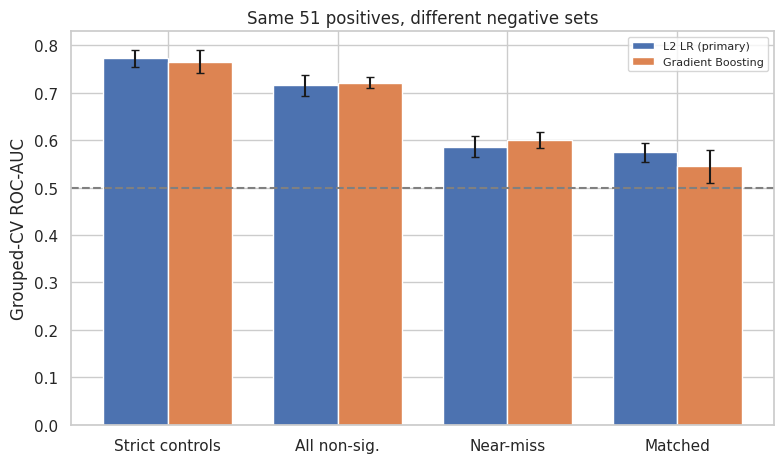


Saved: /content/T2D_v10_ML_Results/T2D_CONFOUND_DIAGNOSTIC.xlsx

confound_summary: {
  "L2 LR (primary)": {
    "strict_controls_roc": 0.772283117164495,
    "all_nonsignificant_roc": 0.7153434090826719,
    "near_miss_negatives_roc": 0.5859449662217828,
    "expression_matched_controls_roc": 0.574144,
    "logbaseMean_plus_lfcSE_only_roc": 0.7325060812873618,
    "all_14_reference_roc": 0.772283117164495
  },
  "Gradient Boosting": {
    "strict_controls_roc": 0.7657232054047134,
    "all_nonsignificant_roc": 0.7213997317966003,
    "near_miss_negatives_roc": 0.6000521777338387,
    "expression_matched_controls_roc": 0.5445599999999999,
    "logbaseMean_plus_lfcSE_only_roc": 0.675996887956589,
    "all_14_reference_roc": 0.7662491013482239
  },
  "within_lfcSE_stratum_weighted_auc_primary": 0.625261688764829,
  "primary_lr_guide": "near_chance_expression_driven"
}


In [51]:
#@title 36I. Confound diagnostic: is the signal biology, or expression / detectability?
# Tests whether the model mainly separates low-expression from high-expression genes (a consequence of how
# strict controls are defined), instead of carrying biological signal. Nothing here changes earlier results.
# Needs: cells 6-7, 27B (secondary model), 36A (fdr221/lfc221), 36C (rep10_oof, FACTORIES).

from sklearn.metrics import roc_auc_score, average_precision_score
assert raw_cols_ok, "Raw GSE221156 FDR/log2FC columns are required (see cell 36A)."
assert "rep10_oof" in globals() and "FACTORIES" in globals(), "Run cell 36C first."
if "ADDL" not in globals():
    ADDL = {}

DIAG = {}                                  # tables for this diagnostic
SEEDS_D = (11, 22, 33, 44, 55)
MODEL_NAMES = list(FACTORIES.keys())       # ["L2 LR (primary)", <secondary model>]

num_all = df[PRIMARY_FEATURES].apply(pd.to_numeric, errors="coerce")
num_all["log_baseMean"] = np.log1p(num_all["gse164416_baseMean"])
num_all["log_pancreas_tpm"] = np.log1p(num_all["gtex_pancreas_tpm"])

def groups_for(idx):
    vals = df.loc[idx, "locus_group_v6"] if "locus_group_v6" in df.columns else [None] * len(idx)
    return np.array([str(v) if (pd.notna(v) and str(v).strip() != "") else f"singleton_{i}"
                     for i, v in zip(idx, vals)])

def cv_runs(idx, ylab, cols, factory, seeds):
    """Grouped 5-fold CV on the gene set `idx` with labels `ylab`; returns list of (ROC-AUC, PR-AUC) per seed."""
    Xs = num_all.loc[idx, cols]; ys = pd.Series(np.asarray(ylab), index=idx); gs = groups_for(idx)
    out = []
    for sd in seeds:
        cvx = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=sd)
        ps = np.full(len(idx), np.nan)
        for tr, te in cvx.split(Xs, ys, gs):
            m = factory(); m.fit(Xs.iloc[tr], ys.iloc[tr])
            ps[te] = m.predict_proba(Xs.iloc[te])[:, 1]
        out.append((roc_auc_score(ys, ps), average_precision_score(ys, ps)))
    return out

def summarize_runs(runs, ylab):
    r = np.array(runs); prev = float(np.mean(ylab))
    return {"n_positive": int(np.sum(ylab)), "n_negative": int(len(ylab) - np.sum(ylab)), "prevalence": prev,
            "roc_auc_mean": r[:, 0].mean(), "roc_auc_sd": r[:, 0].std(ddof=1),
            "pr_auc_mean": r[:, 1].mean(), "pr_auc_sd": r[:, 1].std(ddof=1),
            "pr_lift_over_prevalence": r[:, 1].mean() / prev}

# =====================================================================================
# A. Alternative negative sets (positives are always the same 51 genes)
# =====================================================================================
pos_idx = df.index[(y_raw == 1).to_numpy()]
neg_sets = {
    "Reference: strict controls (FDR>=0.05 and |log2FC|<log2(1.2))": df.index[(y_raw == 0).to_numpy()],
    "All non-significant tested genes (FDR>=0.05, any fold change)": df.index[(fdr221 >= 0.05).to_numpy()],
    "Near-miss negatives only (FDR>=0.05 and |log2FC|>=log2(1.2))": df.index[((fdr221 >= 0.05) & (lfc221.abs() >= FC_THR)).to_numpy()],
}
rowsA = []
for sname, nidx in neg_sets.items():
    idx = pos_idx.append(nidx)
    ylab = np.r_[np.ones(len(pos_idx), int), np.zeros(len(nidx), int)]
    for mname, fac in FACTORIES.items():
        rowsA.append({"scenario": sname, "model": mname, **summarize_runs(cv_runs(idx, ylab, PRIMARY_FEATURES, fac, SEEDS_D), ylab)})
        print("A done:", sname[:45], "|", mname)
tabA = pd.DataFrame(rowsA)
print("\nA. Same 51 positives, different negatives (grouped CV, 5 seeds, all 14 predictors):")
display(tabA.round(4))
DIAG["A_negative_sets"] = tabA

# =====================================================================================
# B. Expression-matched controls (match on log baseMean and lfcSE, 5 controls per positive)
# =====================================================================================
MATCH_FEATS = ["log_baseMean", "lfcSE"]
BAL_FEATS = ["log_baseMean", "lfcSE", "gtex_tau_specificity", "log_pancreas_tpm"]
Zall = num_all.loc[X.index, MATCH_FEATS]
ok = Zall.notna().all(axis=1)
mu, sdv = Zall[ok].mean(), Zall[ok].std()
Zs = (Zall - mu) / sdv
pos_ok = [i for i in X.index[(y == 1).to_numpy()] if ok[i]]
ctl_ok = [i for i in X.index[(y == 0).to_numpy()] if ok[i]]

def match_controls(seed, k=5):
    rng = np.random.default_rng(seed); avail = np.array(ctl_ok); chosen = []
    for p in rng.permutation(pos_ok):
        d = ((Zs.loc[avail].to_numpy() - Zs.loc[p].to_numpy()) ** 2).sum(axis=1)
        take = avail[np.argsort(d)[:k]]; chosen += list(take)
        avail = np.array([a for a in avail if a not in set(take)])
    return chosen

def smd(a, b):
    a, b = a.dropna(), b.dropna()
    return (a.mean() - b.mean()) / np.sqrt((a.var() + b.var()) / 2)

m0 = match_controls(SEED)
bal = []
for f in BAL_FEATS:
    pv = num_all.loc[pos_ok, f]
    bal.append({"feature": f, "positives_median": pv.median(),
                "all_strict_controls_median": num_all.loc[ctl_ok, f].median(),
                "matched_controls_median": num_all.loc[m0, f].median(),
                "SMD_before_matching": smd(pv, num_all.loc[ctl_ok, f]),
                "SMD_after_matching": smd(pv, num_all.loc[m0, f]),
                "matched_on": f in MATCH_FEATS})
tabBbal = pd.DataFrame(bal)
print("\nB1. Balance check (SMD = standardized mean difference; closer to 0 = better balanced):")
display(tabBbal.round(3))
DIAG["B1_matching_balance"] = tabBbal

rowsB = []
for mname, fac in FACTORIES.items():
    runs = []
    for ms in SEEDS_D:                      # a different matched sample AND a different CV split each time
        ctl_m = match_controls(ms)
        idx = pd.Index(pos_ok).append(pd.Index(ctl_m))
        ylab = np.r_[np.ones(len(pos_ok), int), np.zeros(len(ctl_m), int)]
        runs += cv_runs(idx, ylab, PRIMARY_FEATURES, fac, (ms,))
    ylab_ref = np.r_[np.ones(len(pos_ok)), np.zeros(5 * len(pos_ok))]
    rowsB.append({"scenario": "Expression-matched controls (5 per positive, 5 matched samples)",
                  "model": mname, **summarize_runs(runs, ylab_ref)})
tabB = pd.DataFrame(rowsB)
print("\nB2. Performance on expression-matched controls (chance ROC-AUC = 0.50):")
display(tabB.round(4))
DIAG["B2_matched_controls"] = tabB

# =====================================================================================
# C. Expression-stratified AUC using the existing held-out (out-of-fold) predictions
# =====================================================================================
lab = pd.DataFrame({"y": y.to_numpy(),
                    "baseMean": num_all.loc[X.index, "gse164416_baseMean"].to_numpy(),
                    "lfcSE": num_all.loc[X.index, "lfcSE"].to_numpy()}, index=X.index)
for mname in MODEL_NAMES:
    lab[f"p::{mname}"] = rep10_oof[mname]

def boot_auc(yv, pv, n=1000, seed=SEED):
    rng = np.random.default_rng(seed); v = []
    for _ in range(n):
        i = rng.integers(0, len(yv), len(yv))
        if len(np.unique(yv[i])) == 2: v.append(roc_auc_score(yv[i], pv[i]))
    return (np.quantile(v, .025), np.quantile(v, .975)) if v else (np.nan, np.nan)

rowsC, pooledC = [], []
for var in ["baseMean", "lfcSE"]:
    d = lab.dropna(subset=[var]).copy()
    d["stratum"] = pd.qcut(d[var].rank(method="first"), 5, labels=[f"Q{i}" for i in range(1, 6)])
    for mname in MODEL_NAMES:
        w_sum = w_tot = 0.0
        for q, sub in d.groupby("stratum", observed=True):
            npos = int(sub.y.sum()); nneg = len(sub) - npos
            if npos >= 3 and nneg >= 3:
                auc = roc_auc_score(sub.y, sub[f"p::{mname}"]); lo, hi = boot_auc(sub.y.to_numpy(), sub[f"p::{mname}"].to_numpy())
                w = npos * nneg; w_sum += w * auc; w_tot += w
            else:
                auc = lo = hi = np.nan
            rowsC.append({"stratified_by": var, "model": mname, "stratum": q, "variable_min": sub[var].min(),
                          "variable_max": sub[var].max(), "n_positive": npos, "n_negative": nneg,
                          "AUC": auc, "AUC_ci_low": lo, "AUC_ci_high": hi})
        pooledC.append({"stratified_by": var, "model": mname,
                        "within_stratum_AUC_weighted": w_sum / w_tot if w_tot else np.nan,
                        "overall_AUC_unstratified": roc_auc_score(d.y, d[f"p::{mname}"])})
tabC = pd.DataFrame(rowsC); tabCp = pd.DataFrame(pooledC)
print("\nC1. AUC within expression strata (positives per stratum show where positives concentrate):")
display(tabC.round(3))
print("\nC2. Weighted within-stratum AUC vs overall AUC (if within-stratum is much lower, expression explains the signal):")
display(tabCp.round(3))
DIAG["C1_stratified_AUC"] = tabC; DIAG["C2_within_vs_overall"] = tabCp

# =====================================================================================
# D. Tiny 'detectability' models vs the full model
# =====================================================================================
idx_all, y_all = X.index, y.to_numpy()
feature_sets = {
    "log(baseMean) only": ["log_baseMean"],
    "log(baseMean) + lfcSE": ["log_baseMean", "lfcSE"],
    "log(baseMean) + lfcSE + tau + log(pancreas TPM)": ["log_baseMean", "lfcSE", "gtex_tau_specificity", "log_pancreas_tpm"],
    "All 14 predictors (reference)": PRIMARY_FEATURES,
}
rowsD = []
for fs_name, cols in feature_sets.items():
    for mname, fac in FACTORIES.items():
        rowsD.append({"feature_set": fs_name, "model": mname, "n_features": len(cols),
                      **summarize_runs(cv_runs(idx_all, y_all, cols, fac, SEEDS_D), y_all)})
        print("D done:", fs_name, "|", mname)
tabD = pd.DataFrame(rowsD)
print("\nD. Small models built only from expression/detectability features vs the full 14-predictor model:")
display(tabD.round(4))
DIAG["D_small_models"] = tabD

# =====================================================================================
# Plain-language readout (a guide, not a test statistic)
# =====================================================================================
def roc(tab, model, key):
    r = tab[(tab.model == model) & (tab.scenario.str.contains(key, regex=False))]
    return float(r.roc_auc_mean.iloc[0]) if len(r) else np.nan

print("\n" + "=" * 78 + "\nREADOUT (ROC-AUC, mean over seeds)\n" + "=" * 78)
for mname in MODEL_NAMES:
    print(f"\n{mname}")
    print(f"  strict controls (reference)      : {roc(tabA, mname, 'Reference'):.3f}")
    print(f"  all non-significant genes        : {roc(tabA, mname, 'All non-significant'):.3f}")
    print(f"  near-miss negatives only         : {roc(tabA, mname, 'Near-miss'):.3f}")
    print(f"  expression-matched controls      : {roc(tabB, mname, 'matched'):.3f}")
    d4 = tabD[(tabD.model == mname) & (tabD.feature_set == 'log(baseMean) + lfcSE')].roc_auc_mean.iloc[0]
    print(f"  log(baseMean)+lfcSE only (2 feat): {d4:.3f}")
lr_name = MODEL_NAMES[0]
lr_drop = min(roc(tabA, lr_name, 'Near-miss'), roc(tabB, lr_name, 'matched'))
print("\nGuide for the primary LR model:")
if lr_drop < 0.60:
    print("  ROC-AUC falls to ~chance when negatives are noise-matched -> the original signal is largely "
          "expression/detectability-driven (the control definition), not biology.")
elif lr_drop < 0.70:
    print("  ROC-AUC falls substantially but stays above chance -> part of the signal is expression-driven; "
          "report both numbers.")
else:
    print("  ROC-AUC largely survives -> the confound hypothesis is not supported for this model.")

# Figure
plot_rows = []
for mname in MODEL_NAMES:
    for lab_, tab_, key in [("Strict controls", tabA, "Reference"), ("All non-sig.", tabA, "All non-significant"),
                            ("Near-miss", tabA, "Near-miss"), ("Matched", tabB, "matched")]:
        r = tab_[(tab_.model == mname) & (tab_.scenario.str.contains(key, regex=False))].iloc[0]
        plot_rows.append({"model": mname, "negatives": lab_, "roc": r.roc_auc_mean, "sd": r.roc_auc_sd})
pf = pd.DataFrame(plot_rows)
fig, ax = plt.subplots(figsize=(8, 4.8)); w = 0.38; xs = np.arange(4)
for k, mname in enumerate(MODEL_NAMES):
    sub = pf[pf.model == mname]
    ax.bar(xs + (k - 0.5) * w, sub.roc, w, yerr=sub.sd, label=mname, capsize=3)
ax.axhline(0.5, ls="--", color="gray"); ax.set_xticks(xs); ax.set_xticklabels(pf.negatives.unique())
ax.set_ylabel("Grouped-CV ROC-AUC"); ax.set_title("Same 51 positives, different negative sets"); ax.legend(fontsize=8)
savefig("18_confound_diagnostic")

# Save + download
for k_, v_ in DIAG.items(): ADDL[k_[:31]] = v_
diag_x = OUT / "T2D_CONFOUND_DIAGNOSTIC.xlsx"
with pd.ExcelWriter(diag_x, engine="openpyxl") as w_:
    for k_, v_ in DIAG.items(): v_.to_excel(w_, index=False, sheet_name=k_[:31])
print("\nSaved:", diag_x)

# Compact numbers for the manifest / manuscript
def _d_roc(model, fs):
    return float(tabD[(tabD.model == model) & (tabD.feature_set == fs)].roc_auc_mean.iloc[0])
confound_summary = {
    m: {"strict_controls_roc": roc(tabA, m, "Reference"),
        "all_nonsignificant_roc": roc(tabA, m, "All non-significant"),
        "near_miss_negatives_roc": roc(tabA, m, "Near-miss"),
        "expression_matched_controls_roc": roc(tabB, m, "matched"),
        "logbaseMean_plus_lfcSE_only_roc": _d_roc(m, "log(baseMean) + lfcSE"),
        "all_14_reference_roc": _d_roc(m, "All 14 predictors (reference)")}
    for m in MODEL_NAMES}
confound_summary["within_lfcSE_stratum_weighted_auc_primary"] = float(
    tabCp[(tabCp.stratified_by == "lfcSE") & (tabCp.model == MODEL_NAMES[0])].within_stratum_AUC_weighted.iloc[0])
confound_summary["primary_lr_guide"] = ("near_chance_expression_driven" if lr_drop < 0.60 else
                                        "substantially_expression_driven" if lr_drop < 0.70 else "survives")
print("\nconfound_summary:", json.dumps(confound_summary, indent=2, default=float))

In [52]:
#@title 36J. Score distributions of positives, strict controls and unlabeled genes (manuscript Section 5.6)
# Labeled genes: held-out out-of-fold predictions of the primary grouped split (seed 20260910, `oof`).
# Unlabeled genes: out-of-sample scores of the final model fitted on all labeled genes.
# "Top 100 overall" ranks all 3,868 genes by the final-model score (in-sample for labeled genes).
lab_status = status.loc[X.index].to_numpy()
s_pos = oof[lab_status == "positive"]
s_ctl = oof[lab_status == "strict_control"]
unl_mask = (status == "unlabeled").to_numpy()
dup_mask = df["duplicate_resolution"].eq("exclude_duplicate_row").to_numpy()
s_unl = df_scores["primary_LR_score"].to_numpy()[unl_mask]
s_unl_nodup = df_scores["primary_LR_score"].to_numpy()[unl_mask & ~dup_mask]

def _q(v):
    return {"median": float(np.median(v)), "q25": float(np.quantile(v, .25)), "q75": float(np.quantile(v, .75)), "n": int(len(v))}

med_pos, p90_ctl = float(np.median(s_pos)), float(np.quantile(s_ctl, .90))
top100 = df_scores["primary_LR_score"].to_numpy().argsort()[::-1][:100]
sec56 = pd.DataFrame([
    {"group": "positives (held-out, single split)", **_q(s_pos)},
    {"group": "strict controls (held-out, single split)", **_q(s_ctl)},
    {"group": "unlabeled (out-of-sample, all 1,826)", **_q(s_unl)},
    {"group": "unlabeled (out-of-sample, duplicates excluded)", **_q(s_unl_nodup)},
])
sec56_extra = {
    "frac_unlabeled_above_median_heldout_positive": float((s_unl > med_pos).mean()),
    "frac_unlabeled_above_p90_heldout_control": float((s_unl > p90_ctl).mean()),
    "frac_unlabeled_nodup_above_median_heldout_positive": float((s_unl_nodup > med_pos).mean()),
    "frac_unlabeled_nodup_above_p90_heldout_control": float((s_unl_nodup > p90_ctl).mean()),
    "n_unlabeled_in_top100_overall_final_model": int(unl_mask[top100].sum()),
}
display(sec56.round(3))
print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in sec56_extra.items()})
sec56.assign(**{k: v for k, v in sec56_extra.items()}).to_csv(TAB / "section5_6_score_distributions.csv", index=False)
manifest["section_5_6_score_distributions"] = {"by_group": sec56.to_dict(orient="records"), **sec56_extra}


,group,median,q25,q75,n
0,"positives (held-out, single split)",0.067,0.049,0.085,51
1,"strict controls (held-out, single split)",0.036,0.025,0.052,1991
2,"unlabeled (out-of-sample, all 1,826)",0.040,0.026,0.068,1826
3,"unlabeled (out-of-sample, duplicates excluded)",0.040,0.026,0.068,1812


{'frac_unlabeled_above_median_heldout_positive': 0.256, 'frac_unlabeled_above_p90_heldout_control': 0.189, 'frac_unlabeled_nodup_above_median_heldout_positive': 0.258, 'frac_unlabeled_nodup_above_p90_heldout_control': 0.19, 'n_unlabeled_in_top100_overall_final_model': 73}


In [53]:
#@title 37. Final manifest, save fitted models, package outputs (RUN LAST)
import shutil

# 1. Save fitted models
joblib.dump(final_model, MODEL_DIR / "primary_L2LR_C0.1_all_labeled.joblib")
_sec_safe = secondary_name.lower().replace(" ", "_")
joblib.dump(secondary_full_model, MODEL_DIR / f"secondary_{_sec_safe}_all_labeled.joblib")

# 2. Rewrite the manifest with every final number
manifest["completed_utc"] = datetime.now(timezone.utc).isoformat()
manifest["notebook_revision"] = "v11 (HGNC / Ensembl identifier mapping, duplicate-gene flags, candidate tables; held-out Precision@K, nested fixed-config audit, 10-seed Table 3, packaging last; v12: Section 5.6 score-distribution cell 36J)"
manifest["software_versions_final"] = {"numpy": np.__version__, "pandas": pd.__version__,
                                       "scipy": __import__("scipy").__version__,
                                       "sklearn": __import__("sklearn").__version__,
                                       "matplotlib": matplotlib.__version__}
manifest["group_audit"] = group_audit
manifest["nested_fixed_config_audit"] = {
    "outer_predictions_match_primary_oof": bool(nested_matches_primary),
    "mean_inner_roc_auc": float(nested_audit.inner_roc_auc.mean()),
    "mean_outer_roc_auc": float(nested_audit.outer_roc_auc.mean())}
manifest["grouped_vs_plain_cv"] = plain_cv_metrics
manifest["precision_at_k_heldout_single_split"] = p_at_k_heldout.to_dict(orient="records")
manifest["precision_at_k_apparent_insample"] = p_at_k_apparent.to_dict(orient="records")
manifest["ten_seed_summary"] = rep10_summary.to_dict(orient="records")
manifest["table3_single_split_and_10seed"] = table3_seeds.to_dict(orient="records")
manifest["confound_diagnostic"] = confound_summary
with open(OUT / "run_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2, default=str)

# 3. Everything the manuscript needs must exist before zipping
required = [OUT / "run_manifest.json",
            OUT / "T2D_v10_FULL_ML_FINAL_MODEL_BENCHMARK_RESULTS.xlsx",
            OUT / "T2D_ADDITIONAL_ANALYSES_FOR_REVISION.xlsx",
            OUT / "T2D_CANDIDATE_FILTER_ANALYSIS.xlsx",
            OUT / "T2D_CONFOUND_DIAGNOSTIC.xlsx",
            TAB / "precision_at_k.csv", TAB / "precision_at_k_apparent_insample.csv",
            TAB / "table3_benchmark_single_split_and_10seed.csv",
            TAB / "table4_topk_heldout_vs_apparent.csv",
            TAB / "protocol_audit_nested_fixed_config.csv",
            TAB / "Supplementary_Table_S1_top30_unlabeled.csv", TAB / "identifier_map.csv",
            TAB / "section5_6_score_distributions.csv",
            FIG / "Figure_4_topk_heldout_vs_apparent.png"]
missing_outputs = [str(p) for p in required if not p.exists()]
assert not missing_outputs, f"Missing outputs (run all cells first): {missing_outputs}"

# 4. Package
zip_path = BASE / "T2D_v10_FULL_ML_TRAINING_OUTPUTS.zip"
if zip_path.exists():
    zip_path.unlink()
shutil.make_archive(base_name=str(zip_path.with_suffix("")), format="zip", root_dir=str(OUT))
print("Output package:", zip_path)
print("Figures:", len(list(FIG.glob("*"))), "| Tables:", len(list(TAB.glob("*"))), "| Models:", len(list(MODEL_DIR.glob("*"))))
print("ZIP size (MB):", round(zip_path.stat().st_size / 1024**2, 2))
print("Primary model: L2 Logistic Regression, C=0.1 (fixed in advance). The best secondary model is a benchmark only and was not promoted after inspection of the results.")

try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    print("Not running in Colab; download skipped.")

Output package: /content/T2D_v10_FULL_ML_TRAINING_OUTPUTS.zip
Figures: 47 | Tables: 49 | Models: 2
ZIP size (MB): 5.16
Primary model: L2 Logistic Regression, C=0.1 (fixed in advance). The best secondary model is a benchmark only and was not promoted after inspection of the results.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>